# PSS Scalp XAUUSDm — Exploratory Data Analysis

Following **EDA_AGENT.md** brief. Phases 0–10 completed in order.  
All outputs saved under `outputs/` (tables → CSV, figures → PNG 150 dpi).  
Primary outcome: **result_R**. Random seed: **42** throughout.

In [1]:
import os, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.stattools import durbin_watson
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams.update({'figure.dpi': 150, 'figure.figsize': (12, 5)})

# Output directories
BASE = os.getcwd()  # assumes run from OTI folder
OUT  = os.path.join(BASE, 'outputs')
TBLS = os.path.join(OUT, 'tables')
FIGS = os.path.join(OUT, 'figures')
for d in [OUT, TBLS, FIGS]:
    os.makedirs(d, exist_ok=True)

CSV_PATH = os.path.join(BASE, 'PSS_SCALP_XAUUSDm.csv')
print('Directories ready. CSV:', CSV_PATH)


Directories ready. CSV: c:\Users\HP\Desktop\FastAPI_tut\OTI\PSS_SCALP_XAUUSDm.csv


In [2]:
# ── HELPER FUNCTIONS ──────────────────────────────────────────────

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIGS, name), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def savetable(df, name):
    df.to_csv(os.path.join(TBLS, name), index=True)
    return df

def bootstrap_ci(series, stat_fn=np.mean, n=5000, seed=SEED, alpha=0.05):
    rng  = np.random.default_rng(seed)
    vals = np.array(series.dropna())
    if len(vals) < 2:
        return np.nan, np.nan
    boots = [stat_fn(rng.choice(vals, size=len(vals), replace=True)) for _ in range(n)]
    return np.percentile(boots, 100*alpha/2), np.percentile(boots, 100*(1-alpha/2))

def permutation_test_mean(series, n=10000, seed=SEED):
    """Sign-flip permutation test of mean vs 0."""
    rng  = np.random.default_rng(seed)
    vals = np.array(series.dropna())
    obs  = vals.mean()
    perm = np.array([(rng.choice([-1,1], size=len(vals)) * vals).mean() for _ in range(n)])
    return (perm >= obs).mean()

def group_permtest(a, b, n=10000, seed=SEED):
    """Two-group permutation test of difference in means."""
    rng  = np.random.default_rng(seed)
    comb = np.concatenate([a, b])
    obs  = a.mean() - b.mean()
    na   = len(a)
    count = 0
    for _ in range(n):
        rng.shuffle(comb)
        if comb[:na].mean() - comb[na:].mean() >= obs:
            count += 1
    return count / n

def fdr_correct(pvals):
    rej, p_adj, _, _ = multipletests(pvals, alpha=0.10, method='fdr_bh')
    return rej, p_adj

def pf_fn(x):
    pos = x[x > 0].sum()
    neg = abs(x[x < 0].sum())
    return pos / max(neg, 1e-9)

def bucket_stats(df, group_col, R_col='result_R'):
    rows = []
    for grp, g in df.groupby(group_col):
        n   = len(g)
        wr  = (g[R_col] > 0).mean()
        exp = g[R_col].mean()
        pf_v= pf_fn(g[R_col].values)
        dur = g['duration_min'].mean() if 'duration_min' in g else np.nan
        ci_lo, ci_hi = bootstrap_ci(g[R_col]) if n >= 30 else (np.nan, np.nan)
        note = '*skip* (n<30)' if n < 30 else ('*low n*' if n < 100 else '')
        share = 100 * n / len(df)
        rows.append(dict(group=grp, n=n, share_pct=round(share,1),
                         win_rate=round(wr,3), expectancy=round(exp,3),
                         ci_lo=round(ci_lo,3) if not np.isnan(ci_lo) else np.nan,
                         ci_hi=round(ci_hi,3) if not np.isnan(ci_hi) else np.nan,
                         profit_factor=round(pf_v,3),
                         avg_duration_min=round(dur,1), note=note))
    return pd.DataFrame(rows).set_index('group')

PRIMARY_R = 'result_R'
print('Helpers defined.')


Helpers defined.


---
## Phase 0 — Load, Validate, and Understand the Data

In [3]:
# P0.1 Load
raw = pd.read_csv(CSV_PATH)
df  = raw.copy()
print('Shape:', df.shape)
print('\nDtypes:\n', df.dtypes.to_string())
print('\nMissing values per column:\n', df.isnull().sum().to_string())


Shape: (2368, 46)

Dtypes:
 pos_id               int64
pair                   str
signal_type          int64
signal                 str
direction              str
zone_timeframe         str
entry_timeframe        str
date                   str
entry_day              str
open_time              str
close_time             str
duration_min       float64
open_hour            int64
entry              float64
sl                 float64
tp                 float64
close_price        float64
lots               float64
sl_pips            float64
tp_pips            float64
spread_pips        float64
risk_pts             int64
spread_pts           int64
planned_rr         float64
risk_money         float64
net_profit         float64
result_R           float64
pnl_R              float64
exit_reason            str
zone_age           float64
zone_size_pips     float64
zone_touches         int64
body_size_ratio    float64
engulf_depth       float64
MFE_R              float64
MAE_R              float64


In [4]:
# P0.2 Datetime parsing & sorting
df['open_time']  = pd.to_datetime(df['open_time'],  format='%Y.%m.%d %H:%M:%S', errors='coerce')
df['close_time'] = pd.to_datetime(df['close_time'], format='%Y.%m.%d %H:%M:%S', errors='coerce')
df['date']       = pd.to_datetime(df['date'],       format='%Y.%m.%d',           errors='coerce')
df.sort_values('open_time', inplace=True)
df.reset_index(drop=True, inplace=True)

date_min = df['open_time'].min()
date_max = df['open_time'].max()
trading_days = df['open_time'].dt.date.nunique()
tpd = df.groupby(df['open_time'].dt.date).size()

print(f'Date range  : {date_min.date()} → {date_max.date()}')
print(f'Trading days: {trading_days}')
print('\nTrades-per-day distribution:')
print(tpd.describe().round(2))


Date range  : 2025-10-01 → 2026-10-15
Trading days: 269

Trades-per-day distribution:
count    269.00
mean       8.80
std        3.49
min        1.00
25%        7.00
50%        9.00
75%       11.00
max       18.00
dtype: float64


In [5]:
# P0.3 Integrity checks
checks = {}

checks['dup_pos_id'] = int(df['pos_id'].duplicated().sum())

checks['close_before_open'] = int((df['close_time'] < df['open_time']).sum())

df['computed_dur'] = (df['close_time'] - df['open_time']).dt.total_seconds() / 60
dur_diff = (df['duration_min'] - df['computed_dur']).abs()
checks['max_dur_diff_min'] = round(float(dur_diff.max()), 2)

checks['open_hour_mismatch'] = int((df['open_hour'] != df['open_time'].dt.hour).sum())

day_map = {0:'Mon',1:'Tue',2:'Wed',3:'Thu',4:'Fri',5:'Sat',6:'Sun'}
df['computed_day'] = df['open_time'].dt.dayofweek.map(day_map)
checks['entry_day_mismatch'] = int((df['entry_day'] != df['computed_day']).sum())

longs  = df[df['direction'] == 'BUY']
shorts = df[df['direction'] == 'SELL']
long_ok  = bool(((longs['sl'] < longs['entry']) & (longs['entry'] < longs['tp'])).all())
short_ok = bool(((shorts['tp'] < shorts['entry']) & (shorts['entry'] < shorts['sl'])).all()) if len(shorts) > 0 else True
checks['direction_consistency_ok'] = long_ok and short_ok

df['computed_rr'] = (df['tp_pips'] / df['sl_pips']).round(2)
rr_diff = (df['planned_rr'] - df['computed_rr']).abs()
checks['max_rr_diff'] = round(float(rr_diff.max()), 3)

# Point/pip conversion
pt_ratio = df['risk_pts'] / df['sl_pips']
print(f'risk_pts/sl_pips ratio — mean:{pt_ratio.mean():.2f}, std:{pt_ratio.std():.4f}')
print('Inferred: 1 pip = 10 points for XAUUSDm')

# result_R vs net_profit/risk_money
df['computed_R'] = (df['net_profit'] / df['risk_money']).round(4)
R_corr = float(df[PRIMARY_R].corr(df['computed_R']))
R_mad  = float((df[PRIMARY_R] - df['computed_R']).abs().mean())
checks['result_R_vs_netprofit_corr'] = round(R_corr, 4)
checks['result_R_vs_netprofit_MAD']  = round(R_mad, 4)

# result_R vs pnl_R
print('\nresult_R - pnl_R:')
print((df[PRIMARY_R] - df['pnl_R']).describe().round(4))

# exit_reason
print('\nexit_reason value counts:')
print(df['exit_reason'].value_counts())
sl_exits = df[df['exit_reason']=='SL'][PRIMARY_R]
print(f'SL exits mean result_R: {sl_exits.mean():.3f}, std: {sl_exits.std():.3f}')

print('\n=== Integrity Summary ===')
for k,v in checks.items():
    print(f'  {k}: {v}')


risk_pts/sl_pips ratio — mean:10.00, std:0.0000
Inferred: 1 pip = 10 points for XAUUSDm

result_R - pnl_R:
count    2368.0000
mean        0.0406
std         0.2144
min        -0.6250
25%         0.0000
50%         0.0000
75%         0.0380
max         6.9070
dtype: float64

exit_reason value counts:
exit_reason
SL      2091
TP       273
OPEN       4
Name: count, dtype: int64
SL exits mean result_R: -1.025, std: 0.228

=== Integrity Summary ===
  dup_pos_id: 0
  close_before_open: 0
  max_dur_diff_min: 0.05
  open_hour_mismatch: 0
  entry_day_mismatch: 0
  direction_consistency_ok: True
  max_rr_diff: 0.0
  result_R_vs_netprofit_corr: 0.9982
  result_R_vs_netprofit_MAD: 0.0462


In [6]:
# P0.4 Undocumented path columns
print('MFE_R >= 0:', float((df['MFE_R'] >= 0).mean()))
print('MAE_R sign:', df['MAE_R'].apply(lambda x: 'neg' if x<0 else ('pos' if x>0 else 'zero')).value_counts().to_dict())
print('MAE_R range:', df['MAE_R'].min(), 'to', df['MAE_R'].max())

print('\nmin_to_1R null when MFE_R<1:')
under1 = df[df['MFE_R'] < 1]
print(f'  n={len(under1)}, null min_to_1R: {under1["min_to_1R"].isna().sum()}')
over1 = df[df['MFE_R'] >= 1]
print(f'  n={len(over1)}, non-null min_to_1R: {over1["min_to_1R"].notna().sum()}')

print('\nexcursion_flag values:')
print(df['excursion_flag'].value_counts())

print('\nmax_p_b4_sl describe:')
print(df[['max_p_b4_sl','max_L_b4_tp','MFE_R','MAE_R']].describe().round(3))


MFE_R >= 0: 1.0
MAE_R sign: {'neg': 2368}
MAE_R range: -6.86 to -0.014

min_to_1R null when MFE_R<1:
  n=1228, null min_to_1R: 1228
  n=1140, non-null min_to_1R: 1139

excursion_flag values:
excursion_flag
OK                 2363
OPEN                  4
AMBIGUOUS_SL_TP       1
Name: count, dtype: int64

max_p_b4_sl describe:
       max_p_b4_sl  max_L_b4_tp     MFE_R     MAE_R
count     2368.000     2368.000  2368.000  2368.000
mean         2.550        0.961     2.550    -0.965
std          3.334        0.289     3.335     0.290
min          0.000        0.000     0.000    -6.860
25%          0.300        1.000     0.273    -1.006
50%          0.900        1.000     0.922    -1.002
75%          3.325        1.000     3.347    -1.000
max         12.000        6.900    11.962    -0.014


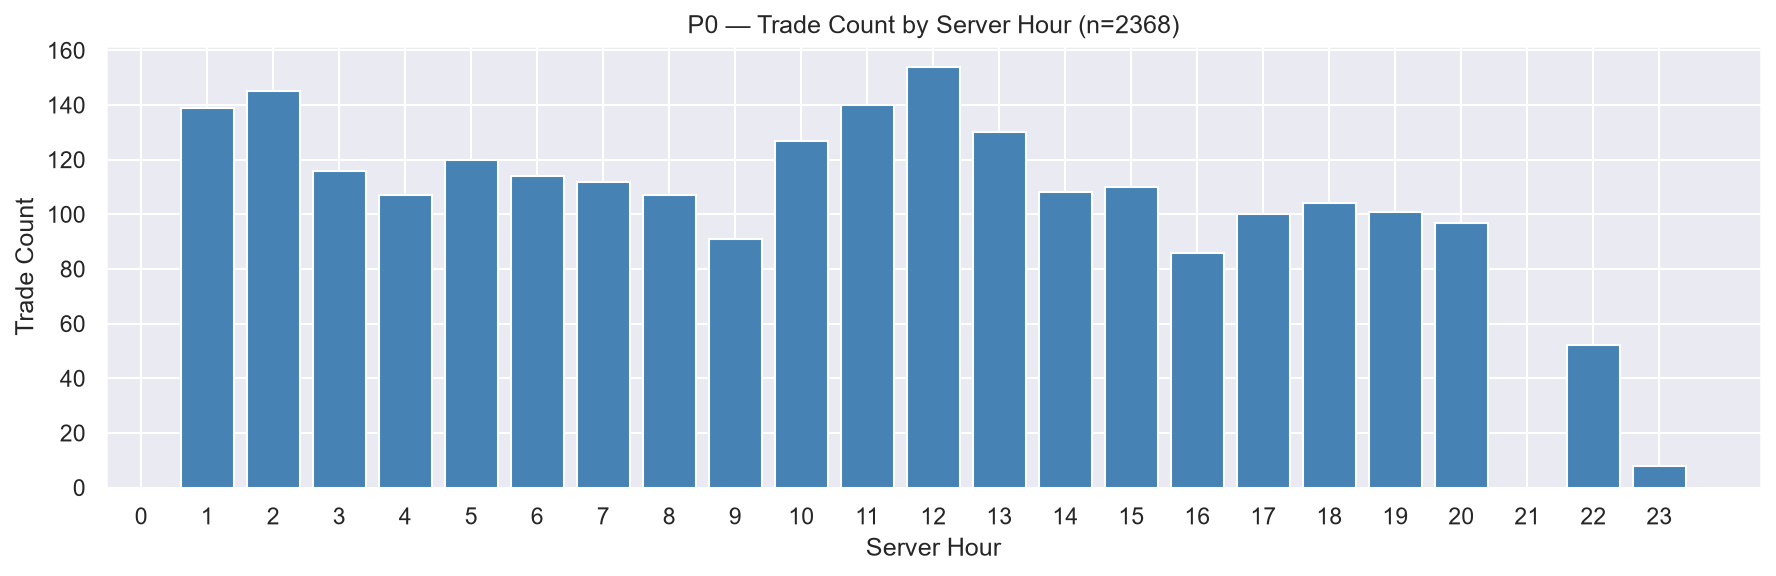

Peak hours suggest UTC+2 or UTC+3 broker server time (London/Johannesburg hours).
Sessions labelled as server-hour buckets only — not confirmed.


In [7]:
# P0.5 Timezone / hour distribution
hour_counts = df['open_hour'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hour_counts.index, hour_counts.values, color='steelblue')
ax.set_xlabel('Server Hour'); ax.set_ylabel('Trade Count')
ax.set_title(f'P0 — Trade Count by Server Hour (n={len(df)})')
ax.set_xticks(range(0,24))
savefig('p0_hour_distribution.png')
print('Peak hours suggest UTC+2 or UTC+3 broker server time (London/Johannesburg hours).')
print('Sessions labelled as server-hour buckets only — not confirmed.')


In [8]:
# P0.6 Primary outcome & data dictionary
print('result_R corr with computed_R:', df[PRIMARY_R].corr(df['computed_R']))
print('pnl_R    corr with computed_R:', df['pnl_R'].corr(df['computed_R']))
print('\nPrimary outcome: result_R (higher correlation, directly interpretable)')

meanings = {
    'pos_id':'Trade identifier','pair':'Symbol (XAUUSDm)',
    'signal_type':'Integer code for signal family','signal':'Descriptive signal name',
    'direction':'BUY or SELL','zone_timeframe':'Timeframe of S/D zone',
    'entry_timeframe':'Execution entry timeframe',
    'date':'Calendar date','entry_day':'Day-of-week (Mon-Fri)',
    'open_time':'Entry timestamp (broker server time)','close_time':'Exit timestamp',
    'duration_min':'Trade duration in minutes','open_hour':'Entry hour (server time)',
    'entry':'Entry price','sl':'Stop-loss price','tp':'Take-profit price',
    'close_price':'Actual close price','lots':'Position size in lots',
    'sl_pips':'SL distance in pips','tp_pips':'TP distance in pips',
    'spread_pips':'Spread at entry (pips)','risk_pts':'sl_pips × 10 (broker points)',
    'spread_pts':'spread_pips × 10 (broker points)','planned_rr':'tp_pips / sl_pips',
    'risk_money':'Monetary risk per trade (USD)','net_profit':'P&L in account currency',
    'result_R':'net_profit/risk_money — PRIMARY OUTCOME',
    'pnl_R':'Similar to result_R; slight diff in some rows (cost adjustment)',
    'exit_reason':'Trade close reason (SL/TP/other)',
    'zone_age':'Zone age in bars at time of entry',
    'zone_size_pips':'S/D zone size in pips','zone_touches':'Prior touches to the zone',
    'body_size_ratio':'Entry candle body/range ratio',
    'engulf_depth':'How deep entry candle penetrates zone (pips)',
    'MFE_R':'Max Favourable Excursion in R (always >= 0)',
    'MAE_R':'Max Adverse Excursion in R (negative = adverse move)',
    'max_p_b4_sl':'Max positive R reached before adverse move to SL (INFERRED)',
    'max_L_b4_tp':'Max adverse R before TP hit — drawdown before winning (INFERRED)',
    'excursion_flag':'Trade-path flag: OK=normal, other=notable excursion (INFERRED)',
    'min_to_MFE':'Minutes from open to MFE','min_to_MAE':'Minutes from open to MAE',
    'min_to_1R':'Min to first +1R (null if MFE_R<1)',
    'min_to_2R':'Min to first +2R (null if MFE_R<2)',
    'min_to_3R':'Min to first +3R (null if MFE_R<3)',
    'min_R_after_1R':'Lowest R after reaching +1R (giveback)',
    'min_R_after_2R':'Lowest R after reaching +2R (giveback)',
}

dd_rows = []
for col in df.columns:
    vals = df[col].dropna()
    try:
        mn, mx = vals.min(), vals.max()
    except Exception:
        mn, mx = '', ''
    dd_rows.append({'dtype': str(df[col].dtype), 'null_count': int(df[col].isna().sum()),
                    'min': mn, 'max': mx,
                    'inferred_meaning': meanings.get(col, '')})
dd = pd.DataFrame(dd_rows, index=df.columns)
dd.index.name = 'column'
savetable(dd, 'p0_data_dictionary.csv')
print('\nData dictionary saved to outputs/tables/p0_data_dictionary.csv')
display(dd)


result_R corr with computed_R: 0.9982096175733922
pnl_R    corr with computed_R: 0.9999999966277273

Primary outcome: result_R (higher correlation, directly interpretable)

Data dictionary saved to outputs/tables/p0_data_dictionary.csv


,dtype,null_count,min,max,inferred_meaning
column,,,,,
pos_id,int64,0,2,4732,Trade identifier
pair,str,0,XAUUSDm,XAUUSDm,Symbol (XAUUSDm)
signal_type,int64,0,4,53,Integer code for signal family
signal,str,0,SIG_TYPE4_H1_M15,SIG_TYPE5_M30,Descriptive signal name
direction,str,0,BUY,BUY,BUY or SELL
zone_timeframe,str,0,H1,M30,Timeframe of S/D zone
entry_timeframe,str,0,H1,M5,Execution entry timeframe
date,datetime64[us],0,2025-10-01 00:00:00,2026-10-15 00:00:00,Calendar date
entry_day,str,0,Fri,Wed,Day-of-week (Mon-Fri)


In [9]:
# Save clean data
df.to_csv(os.path.join(OUT, 'clean_trades.csv'), index=False)
print(f'clean_trades.csv saved: {len(df)} rows')


clean_trades.csv saved: 2368 rows


---
## Phase 1 — Baseline Performance (Full Sample)

In [11]:
# P1.1-2 Core metrics
R = df[PRIMARY_R]
n_trades   = len(R)
n_wins     = int((R > 0).sum())
n_losses   = int((R < 0).sum())
n_be       = int((R == 0).sum())
win_rate   = n_wins / n_trades
avg_win    = float(R[R > 0].mean())
avg_loss   = float(R[R < 0].mean())
payoff     = avg_win / abs(avg_loss)
expectancy = float(R.mean())
pf         = pf_fn(R.values)
total_R    = float(R.sum())
median_R   = float(R.median())
std_R      = float(R.std())
skew_R     = float(R.skew())

exp_lo, exp_hi = bootstrap_ci(R, np.mean)
wr_lo,  wr_hi  = bootstrap_ci((R > 0).astype(float), np.mean)
pf_lo,  pf_hi  = bootstrap_ci(R, pf_fn)

t_stat, t_pval = stats.ttest_1samp(R, 0)
perm_pval      = permutation_test_mean(R)

brk_wr = float(1 / (1 + df['planned_rr'].mean()))

metrics = pd.Series({
    'n_trades': n_trades, 'n_wins': n_wins, 'n_losses': n_losses, 'n_breakevens': n_be,
    'win_rate': round(win_rate,3), 'win_rate_CI_lo': round(wr_lo,3), 'win_rate_CI_hi': round(wr_hi,3),
    'avg_win_R': round(avg_win,3), 'avg_loss_R': round(avg_loss,3), 'payoff_ratio': round(payoff,3),
    'expectancy_R': round(expectancy,3), 'expectancy_CI_lo': round(exp_lo,3), 'expectancy_CI_hi': round(exp_hi,3),
    'profit_factor': round(pf,3), 'pf_CI_lo': round(pf_lo,3), 'pf_CI_hi': round(pf_hi,3),
    'total_R': round(total_R,3), 'median_R': round(median_R,3), 'std_R': round(std_R,3), 'skew_R': round(skew_R,3),
    'ttest_pval': round(t_pval,5), 'permtest_pval': round(perm_pval,5),
    'breakeven_wr': round(brk_wr,3), 'wr_margin_above_breakeven': round(win_rate - brk_wr,3),
})
savetable(metrics.to_frame('value'), 'p1_baseline_metrics.csv')
print(metrics.to_string())


n_trades                     2368.00000
n_wins                        277.00000
n_losses                     2091.00000
n_breakevens                    0.00000
win_rate                        0.11700
win_rate_CI_lo                  0.10400
win_rate_CI_hi                  0.13000
avg_win_R                       9.95300
avg_loss_R                     -1.02500
payoff_ratio                    9.70700
expectancy_R                    0.25900
expectancy_CI_lo                0.11400
expectancy_CI_hi                0.40500
profit_factor                   1.28600
pf_CI_lo                        1.12500
pf_CI_hi                        1.45400
total_R                       613.06600
median_R                       -1.00200
std_R                           3.54600
skew_R                          2.37900
ttest_pval                      0.00039
permtest_pval                   0.00020
breakeven_wr                    0.09100
wr_margin_above_breakeven       0.02600


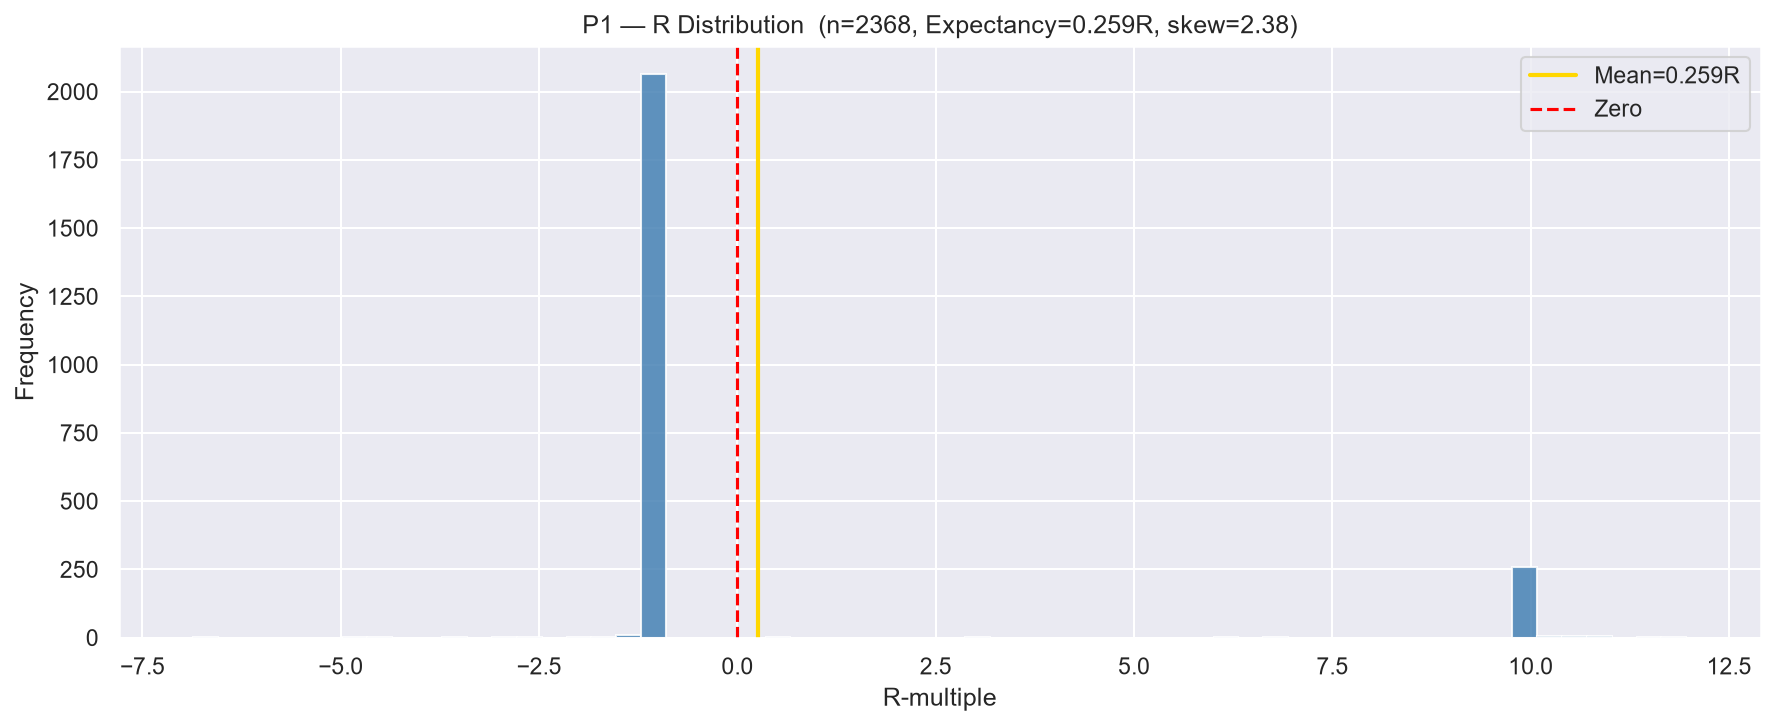

In [12]:
# P1.3 R distribution
fig, ax = plt.subplots(figsize=(12,5))
ax.hist(R, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(expectancy, color='gold', lw=2, label=f'Mean={expectancy:.3f}R')
ax.axvline(0, color='red', lw=1.5, linestyle='--', label='Zero')
ax.set_xlabel('R-multiple'); ax.set_ylabel('Frequency')
ax.set_title(f'P1 — R Distribution  (n={n_trades}, Expectancy={expectancy:.3f}R, skew={skew_R:.2f})')
ax.legend()
savefig('p1_R_histogram.png')


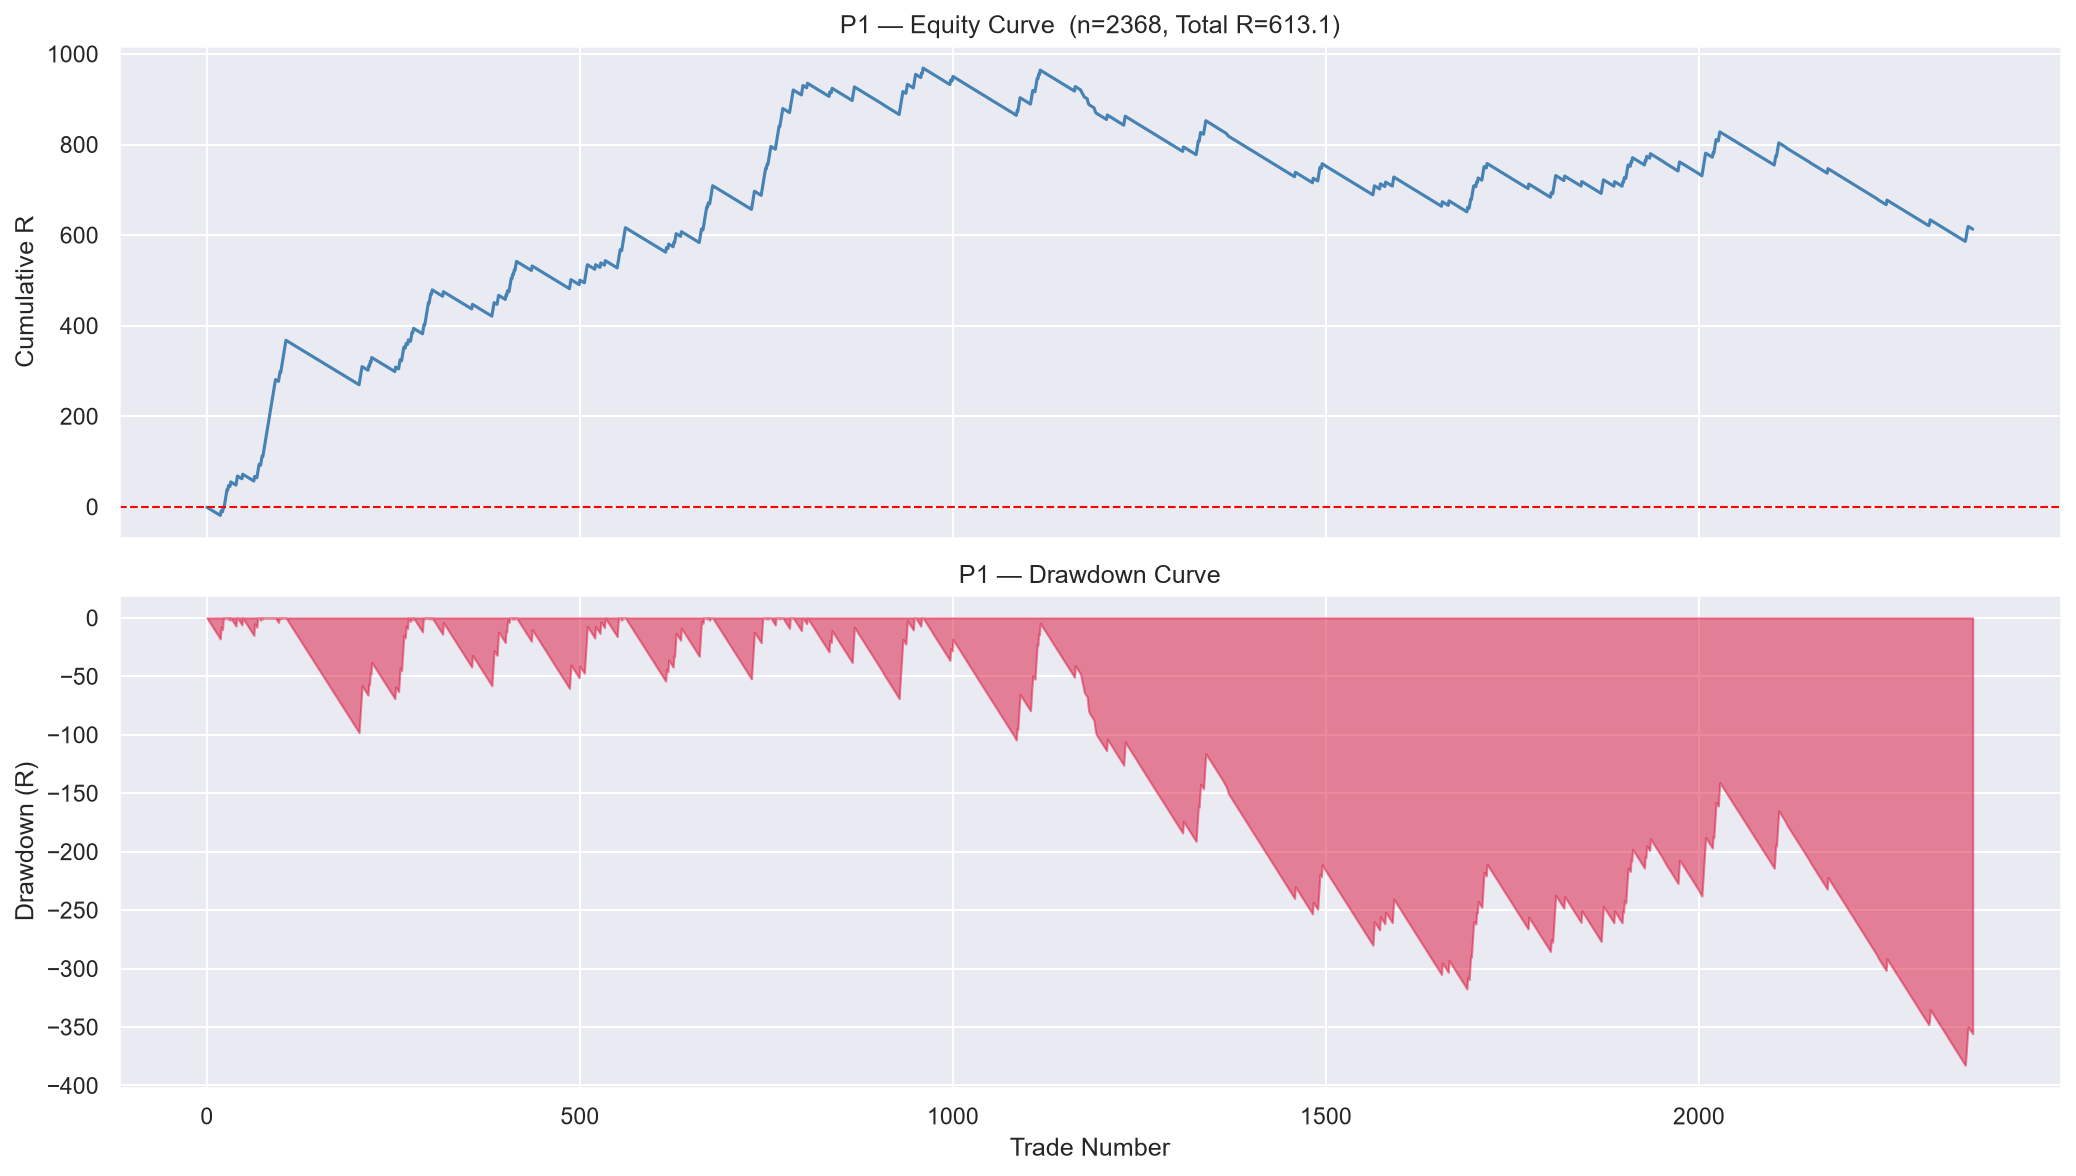

Max drawdown: -382.667R  |  Longest loss streak: 119  |  Longest win streak: 17


In [13]:
# P1.6 Equity curve + drawdown
cum_R    = R.cumsum().values
roll_max = np.maximum.accumulate(cum_R)
dd_curve = cum_R - roll_max

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(cum_R, color='steelblue', lw=1.5)
ax1.axhline(0, color='red', lw=1, linestyle='--')
ax1.set_ylabel('Cumulative R')
ax1.set_title(f'P1 — Equity Curve  (n={n_trades}, Total R={total_R:.1f})')

ax2.fill_between(range(n_trades), dd_curve, 0, color='crimson', alpha=0.5)
ax2.set_ylabel('Drawdown (R)'); ax2.set_xlabel('Trade Number')
ax2.set_title('P1 — Drawdown Curve')
savefig('p1_equity_drawdown.png')

max_dd_R = float(dd_curve.min())
oc_arr   = (R > 0).astype(int).values
longest_L = max((sum(1 for _ in g) for k,g in itertools.groupby(oc_arr) if k==0), default=0)
longest_W = max((sum(1 for _ in g) for k,g in itertools.groupby(oc_arr) if k==1), default=0)
print(f'Max drawdown: {max_dd_R:.3f}R  |  Longest loss streak: {longest_L}  |  Longest win streak: {longest_W}')


In [14]:
# P1.7 Drawdown duration
in_dd      = dd_curve < 0
transitions = np.diff(in_dd.astype(int), prepend=0, append=0)
starts      = np.where(transitions == 1)[0]
ends        = np.where(transitions == -1)[0]
dd_lengths_trades = ends - starts
if len(dd_lengths_trades) > 0:
    print(f'Max drawdown duration: {dd_lengths_trades.max()} trades')
    # In calendar days
    dd_dates = []
    for s, e in zip(starts, ends):
        t0 = df['open_time'].iloc[s]
        t1 = df['open_time'].iloc[min(e, len(df)-1)]
        dd_dates.append((t1 - t0).days)
    if dd_dates:
        print(f'Max drawdown duration in calendar days: {max(dd_dates)}')


Max drawdown duration: 1407 trades
Max drawdown duration in calendar days: 234


In [15]:
# P1.8 Long vs Short
dir_stats = bucket_stats(df, 'direction')
savetable(dir_stats, 'p1_direction_stats.csv')
print(dir_stats)


          n  share_pct  win_rate  expectancy  ci_lo  ci_hi  profit_factor  \
group                                                                       
BUY    2368      100.0     0.117       0.259  0.114  0.405          1.286   

       avg_duration_min note  
group                         
BUY              2442.6       


---
## Phase 2 — Stability Over Time

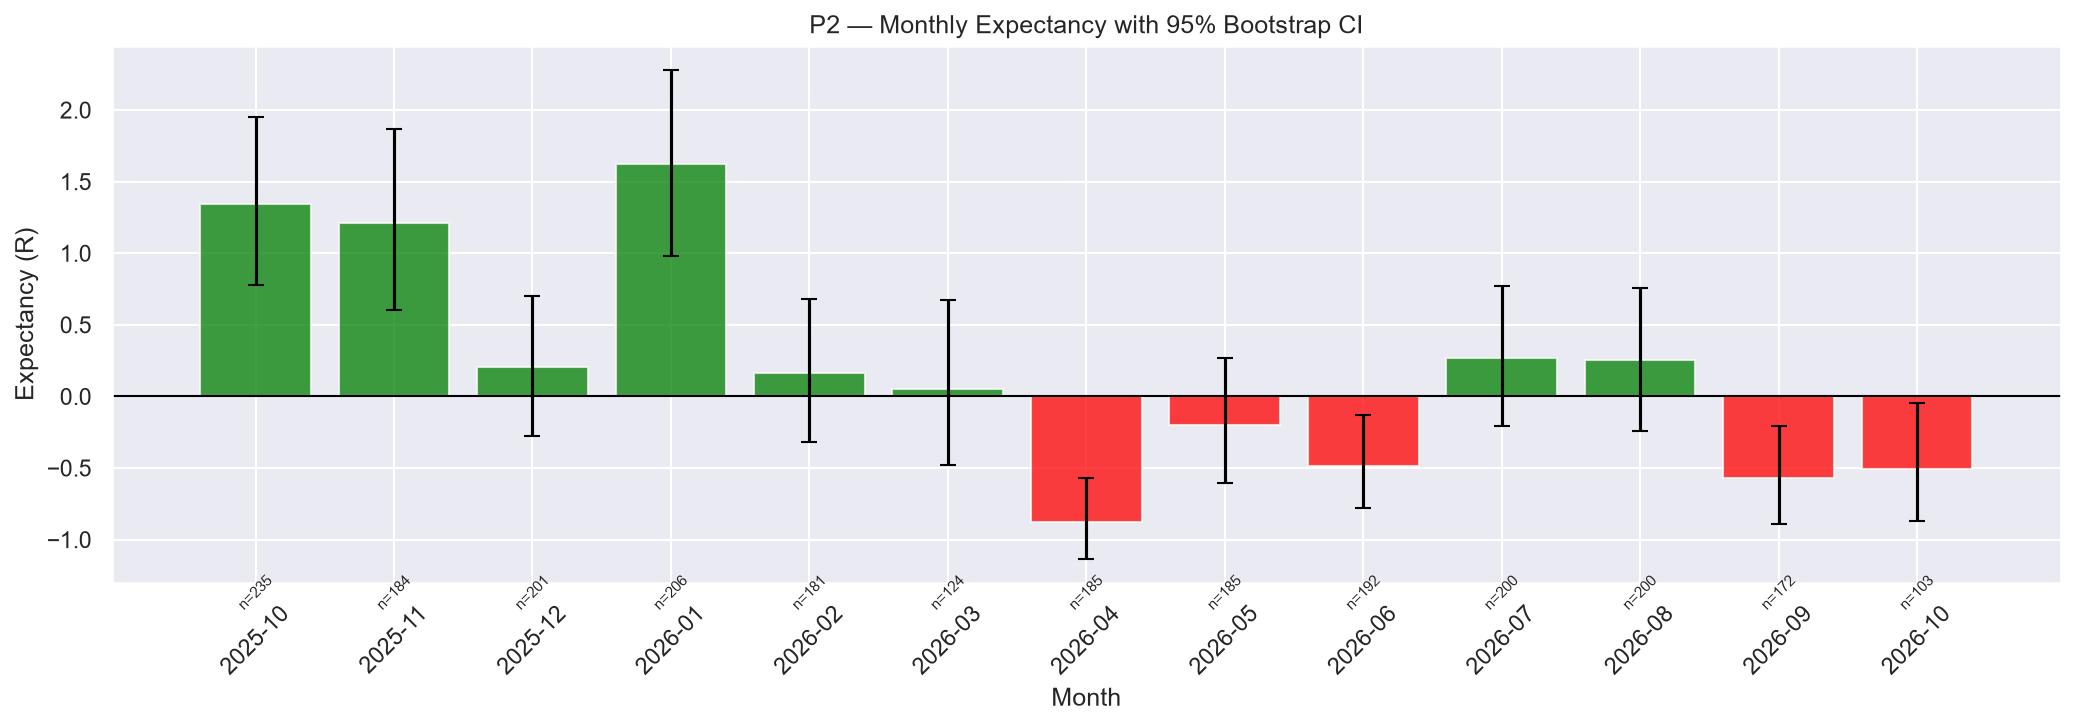

In [16]:
# P2.1 Monthly expectancy
df['month']    = df['open_time'].dt.to_period('M')
df['iso_week'] = df['open_time'].dt.to_period('W')

monthly = df.groupby('month')[PRIMARY_R].agg(['count','mean']).rename(columns={'count':'n','mean':'expectancy'})
monthly['ci_lo'] = [bootstrap_ci(df[df['month']==m][PRIMARY_R])[0]
                    if (df['month']==m).sum()>=30 else np.nan for m in monthly.index]
monthly['ci_hi'] = [bootstrap_ci(df[df['month']==m][PRIMARY_R])[1]
                    if (df['month']==m).sum()>=30 else np.nan for m in monthly.index]
savetable(monthly, 'p2_monthly_expectancy.csv')

months_str = [str(m) for m in monthly.index]
colors_m = ['green' if e > 0 else 'red' for e in monthly['expectancy']]
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(months_str, monthly['expectancy'], color=colors_m, alpha=0.75)
err_lo = (monthly['expectancy'] - monthly['ci_lo']).fillna(0).values
err_hi = (monthly['ci_hi'] - monthly['expectancy']).fillna(0).values
ax.errorbar(months_str, monthly['expectancy'], yerr=[err_lo, err_hi],
            fmt='none', color='black', capsize=4)
for i, (m, row) in enumerate(monthly.iterrows()):
    ax.text(i, ax.get_ylim()[0]*0.95, f'n={int(row["n"])}', ha='center', fontsize=7, rotation=45, va='top')
ax.axhline(0, color='black', lw=1)
ax.set_xlabel('Month'); ax.set_ylabel('Expectancy (R)')
ax.set_title('P2 — Monthly Expectancy with 95% Bootstrap CI')
plt.xticks(rotation=45)
savefig('p2_monthly_expectancy.png')


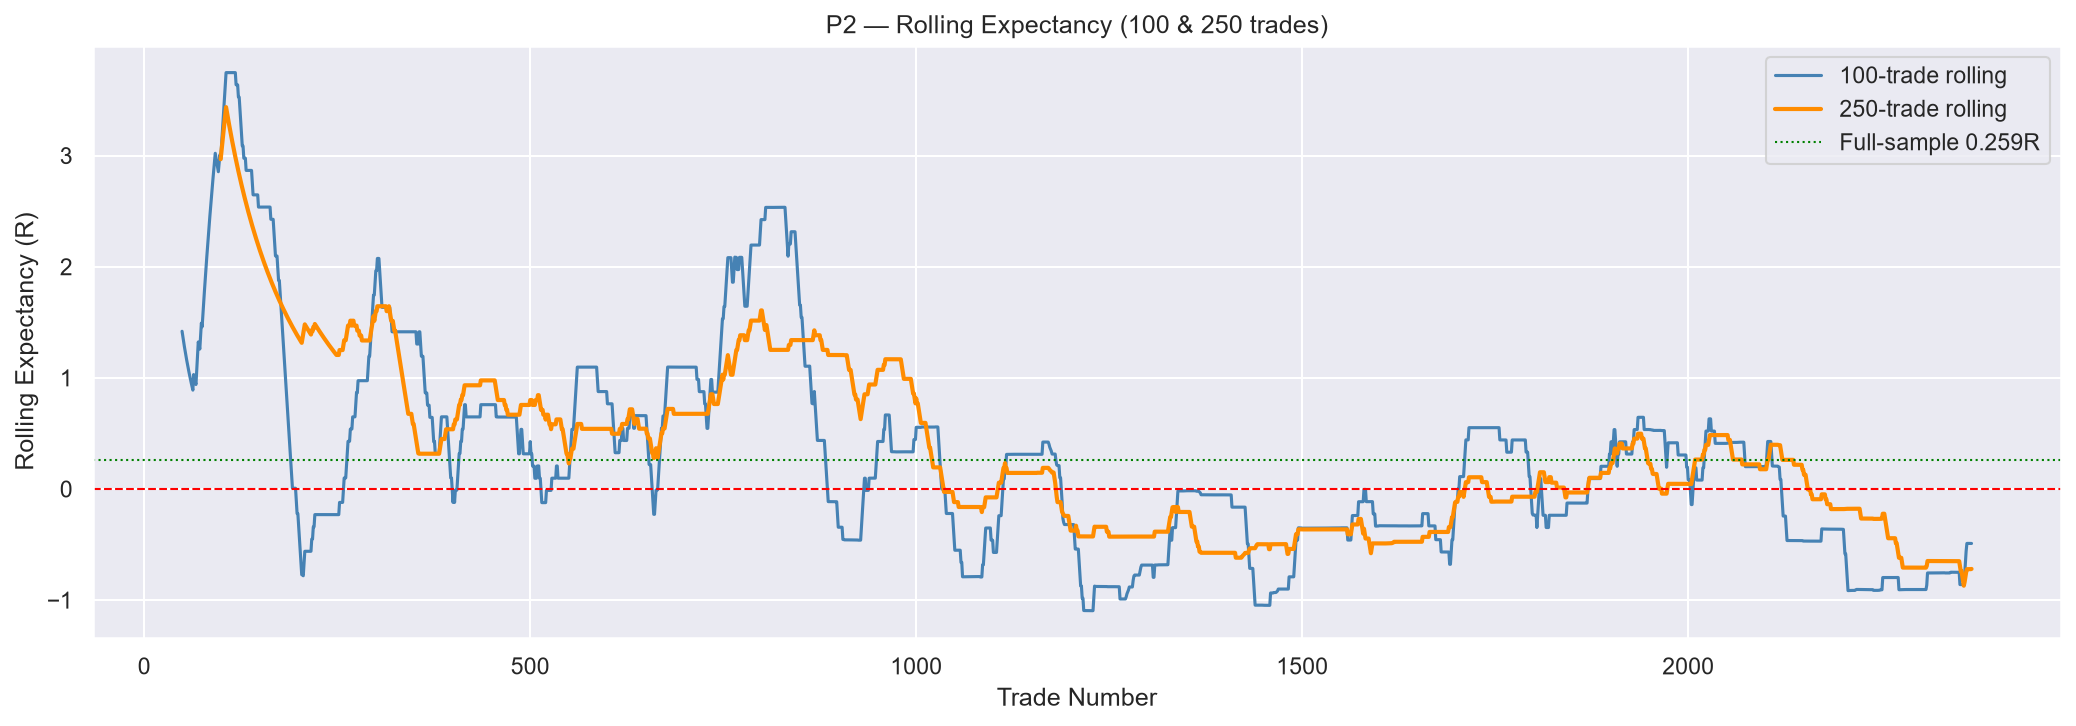

In [17]:
# P2.2 Rolling expectancy
roll100 = R.rolling(100, min_periods=50).mean()
roll250 = R.rolling(250, min_periods=100).mean()

fig, ax = plt.subplots(figsize=(14,5))
ax.plot(roll100.values, label='100-trade rolling', color='steelblue', lw=1.5)
ax.plot(roll250.values, label='250-trade rolling', color='darkorange', lw=2)
ax.axhline(0, color='red', lw=1, linestyle='--')
ax.axhline(expectancy, color='green', lw=1, linestyle=':', label=f'Full-sample {expectancy:.3f}R')
ax.set_xlabel('Trade Number'); ax.set_ylabel('Rolling Expectancy (R)')
ax.set_title('P2 — Rolling Expectancy (100 & 250 trades)')
ax.legend()
savefig('p2_rolling_expectancy.png')


In [18]:
# P2.3-4 Half & quarter splits
med_idx  = len(df) // 2
first_h  = df.iloc[:med_idx]
second_h = df.iloc[med_idx:]

def half_metrics(sub, label):
    r = sub[PRIMARY_R]
    return {'half': label, 'n': len(r),
            'expectancy': round(float(r.mean()),3),
            'win_rate': round(float((r>0).mean()),3),
            'profit_factor': round(pf_fn(r.values),3),
            'avg_spread_pips': round(float(sub['spread_pips'].mean()),2)}

halves = pd.DataFrame([half_metrics(first_h,'First half'), half_metrics(second_h,'Second half')]).set_index('half')
savetable(halves, 'p2_half_comparison.csv')
print('Half comparison:\n', halves)

q_size = len(df) // 4
quarters = pd.DataFrame([half_metrics(df.iloc[i*q_size:(i+1)*q_size], f'Q{i+1}') for i in range(4)]).set_index('half')
savetable(quarters, 'p2_quarter_comparison.csv')
print('\nQuarter comparison:\n', quarters)


Half comparison:
                 n  expectancy  win_rate  profit_factor  avg_spread_pips
half                                                                   
First half   1184       0.749     0.160          1.869            19.42
Second half  1184      -0.232     0.073          0.756            26.74

Quarter comparison:
         n  expectancy  win_rate  profit_factor  avg_spread_pips
half                                                           
Q1    592       0.990     0.181          2.206            16.00
Q2    592       0.509     0.140          1.563            22.83
Q3    592      -0.300     0.068          0.688            28.37
Q4    592      -0.163     0.079          0.825            25.10


In [19]:
# P2.5 Trend regression & feature drift
x = np.arange(len(df))
slope, intercept, r_val, p_val, se = stats.linregress(x, R.values)
print(f'result_R trend: slope={slope:.6f}R/trade, p={p_val:.4f}, R²={r_val**2:.4f}')
for col in ['zone_age','zone_size_pips','spread_pips','sl_pips']:
    vals = df[col].fillna(df[col].median()).values
    s, _, _, pv, _ = stats.linregress(x, vals)
    print(f'  {col}: slope={s:.4f}, p={pv:.4f}')


result_R trend: slope=-0.000784R/trade, p=0.0000, R²=0.0229
  zone_age: slope=0.0000, p=0.9527
  zone_size_pips: slope=-0.1910, p=0.0001
  spread_pips: slope=0.0055, p=0.0000
  sl_pips: slope=-0.2272, p=0.0000


In [20]:
# P2.6 Concentration check
top5_R = float(df.nlargest(5, PRIMARY_R)[PRIMARY_R].sum())
rest_R = total_R - top5_R
print(f'Total R: {total_R:.3f}')
print(f'Top 5 trades: {top5_R:.3f}R ({100*top5_R/total_R:.1f}% of total)')
print(f'Without top 5: {rest_R:.3f}R, expectancy={(rest_R/(n_trades-5)):.3f}R')

weekly_R = df.groupby('iso_week')[PRIMARY_R].sum().sort_values(ascending=False)
top_week_R = float(weekly_R.iloc[0])
print(f'\nBest week: {weekly_R.index[0]} → {top_week_R:.3f}R')
print(f'Without best week: {total_R - top_week_R:.3f}R')


Total R: 613.066
Top 5 trades: 55.908R (9.1% of total)
Without top 5: 557.158R, expectancy=0.236R

Best week: 2026-01-19/2026-01-25 → 221.697R
Without best week: 391.369R


---
## Phase 3 — Outlier and Concentration Check

In [21]:
# P3.1 Concentration
def concentration_row(pct):
    n_top = max(1, int(len(df)*pct))
    top   = df.nlargest(n_top, PRIMARY_R)
    top_R = float(top[PRIMARY_R].sum())
    rest  = df[~df.index.isin(top.index)]
    rest_E = float(rest[PRIMARY_R].mean()) if len(rest) > 0 else np.nan
    return {'pct': f'{pct*100:.0f}%', 'n': n_top,
            'R_share_%': round(100*top_R/total_R,1),
            'exp_without': round(rest_E,3)}

conc_df = pd.DataFrame([concentration_row(p) for p in [0.01, 0.05, 0.10]]).set_index('pct')
savetable(conc_df, 'p3_concentration.csv')
print(conc_df)


       n  R_share_%  exp_without
pct                             
1%    23       39.1        0.159
5%   118      194.2       -0.257
10%  236      386.7       -0.824


In [22]:
# P3.2 Outlier investigation
large_wins   = df[df[PRIMARY_R] > df['planned_rr'] + 0.5]
large_losses = df[df[PRIMARY_R] < -1.2]

cols_show = ['pos_id','open_time','result_R','planned_rr','exit_reason','spread_pips','sl_pips']
print(f'Large wins (result_R > planned_rr + 0.5): {len(large_wins)}')
if len(large_wins) > 0:
    display(large_wins[[c for c in cols_show if c in large_wins.columns]].head(20))

print(f'\nLarge losses (result_R < -1.2): {len(large_losses)}')
if len(large_losses) > 0:
    display(large_losses[[c for c in cols_show if c in large_losses.columns]].head(20))

if len(large_wins) > 0:
    savetable(large_wins[[c for c in cols_show if c in large_wins.columns]], 'p3_large_wins.csv')
if len(large_losses) > 0:
    savetable(large_losses[[c for c in cols_show if c in large_losses.columns]], 'p3_large_losses.csv')


Large wins (result_R > planned_rr + 0.5): 7


column,pos_id,open_time,result_R,planned_rr,exit_reason,spread_pips,sl_pips
106,197,2025-10-15 02:39:00,10.914,10.0,TP,16.0,1559.8
558,1103,2025-12-22 02:51:00,10.758,10.0,TP,16.0,585.7
765,1524,2026-01-22 02:15:00,10.524,10.0,TP,16.0,2148.6
799,1593,2026-01-28 04:55:00,10.900,10.0,TP,16.0,1879.1
929,1851,2026-02-17 16:10:00,10.711,10.0,TP,26.4,4017.5
960,1900,2026-02-20 19:20:00,11.962,10.0,TP,26.4,2046.7
1573,3146,2026-06-11 15:40:00,11.374,10.0,TP,26.0,1617.4



Large losses (result_R < -1.2): 27


column,pos_id,open_time,result_R,planned_rr,exit_reason,spread_pips,sl_pips
276,538,2025-11-06 20:35:00,-1.461,10.0,SL,16.0,621.3
907,1805,2026-02-12 19:21:00,-1.360,10.0,SL,26.4,3655.5
1083,2166,2026-03-20 20:12:00,-1.392,10.0,SL,30.8,1898.2
1172,2335,2026-04-09 01:05:00,-2.934,10.0,SL,30.8,1441.4
1173,2336,2026-04-09 03:27:00,-3.718,10.0,SL,30.8,1077.2
1174,2337,2026-04-09 03:45:00,-2.639,10.0,SL,30.8,1701.6
1175,2338,2026-04-09 04:05:00,-2.861,10.0,SL,30.8,1573.2
1176,2339,2026-04-09 04:05:00,-3.624,10.0,SL,30.8,1242.1
1181,2348,2026-04-09 09:09:00,-6.860,10.0,SL,30.8,851.3
1182,2349,2026-04-09 09:40:00,-4.949,10.0,SL,30.8,1254.9


---
## Phase 4 — Segmentation by Setup and Timing

In [23]:
# Check signal vs signal_type mapping
sig_map = df.groupby('signal')['signal_type'].nunique()
one_to_one = bool((sig_map == 1).all())
USE_SIG = 'signal' if one_to_one else 'signal_type'
print(f'signal → signal_type mapping 1-to-1: {one_to_one}')
print(f'Using "{USE_SIG}" for signal dimension.')


signal → signal_type mapping 1-to-1: True
Using "signal" for signal dimension.


In [24]:
# P4 All dimensions — stats tables + permutation tests
dimensions = [USE_SIG, 'direction', 'zone_timeframe', 'entry_timeframe',
              'entry_day', 'open_hour', 'exit_reason']

all_pvals  = []
dim_tables = {}

for dim in dimensions:
    t = bucket_stats(df, dim)
    savetable(t, f'p4_{dim}_stats.csv')
    dim_tables[dim] = t
    # Permutation test: best vs worst group (n >= 30 only)
    valid_grps = t[t['n'] >= 30]
    if len(valid_grps) >= 2:
        best_g  = df[df[dim] == valid_grps['expectancy'].idxmax()][PRIMARY_R].values
        worst_g = df[df[dim] == valid_grps['expectancy'].idxmin()][PRIMARY_R].values
        pv = group_permtest(best_g, worst_g, n=10000)
        all_pvals.append({'dimension': dim, 'pval_raw': pv})

pval_df = pd.DataFrame(all_pvals)
if len(pval_df) > 0:
    rej, padj = fdr_correct(pval_df['pval_raw'].values)
    pval_df['pval_adj'] = padj.round(5)
    pval_df['fdr_reject'] = rej
    savetable(pval_df.set_index('dimension'), 'p4_fdr_correction.csv')
    print('\nFDR results:')
    print(pval_df.to_string(index=False))



FDR results:
      dimension  pval_raw  pval_adj  fdr_reject
         signal    0.0158    0.0228        True
 zone_timeframe    0.0228    0.0228        True
entry_timeframe    0.0228    0.0228        True
      entry_day    0.0001    0.0003        True
      open_hour    0.0017    0.0034        True
    exit_reason    0.0000    0.0000        True


In [25]:
# P4 Cross-tab zone_tf × entry_tf
cross = df.groupby(['zone_timeframe','entry_timeframe'])[PRIMARY_R].agg(['mean','count'])
cross.columns = ['expectancy','n']
cross['note'] = cross['n'].map(lambda x: '*skip*' if x<30 else ('*low n*' if x<100 else ''))
savetable(cross, 'p4_zone_x_entry_tf.csv')
print('zone_timeframe × entry_timeframe:')
print(cross)


zone_timeframe × entry_timeframe:
                                expectancy    n     note
zone_timeframe entry_timeframe                          
H1             M15                0.066297  283         
H4             H1                 0.994343   67  *low n*
M15            M3                 0.190928  704         
               M5                 0.341932  588         
M30            M5                 0.264758  726         


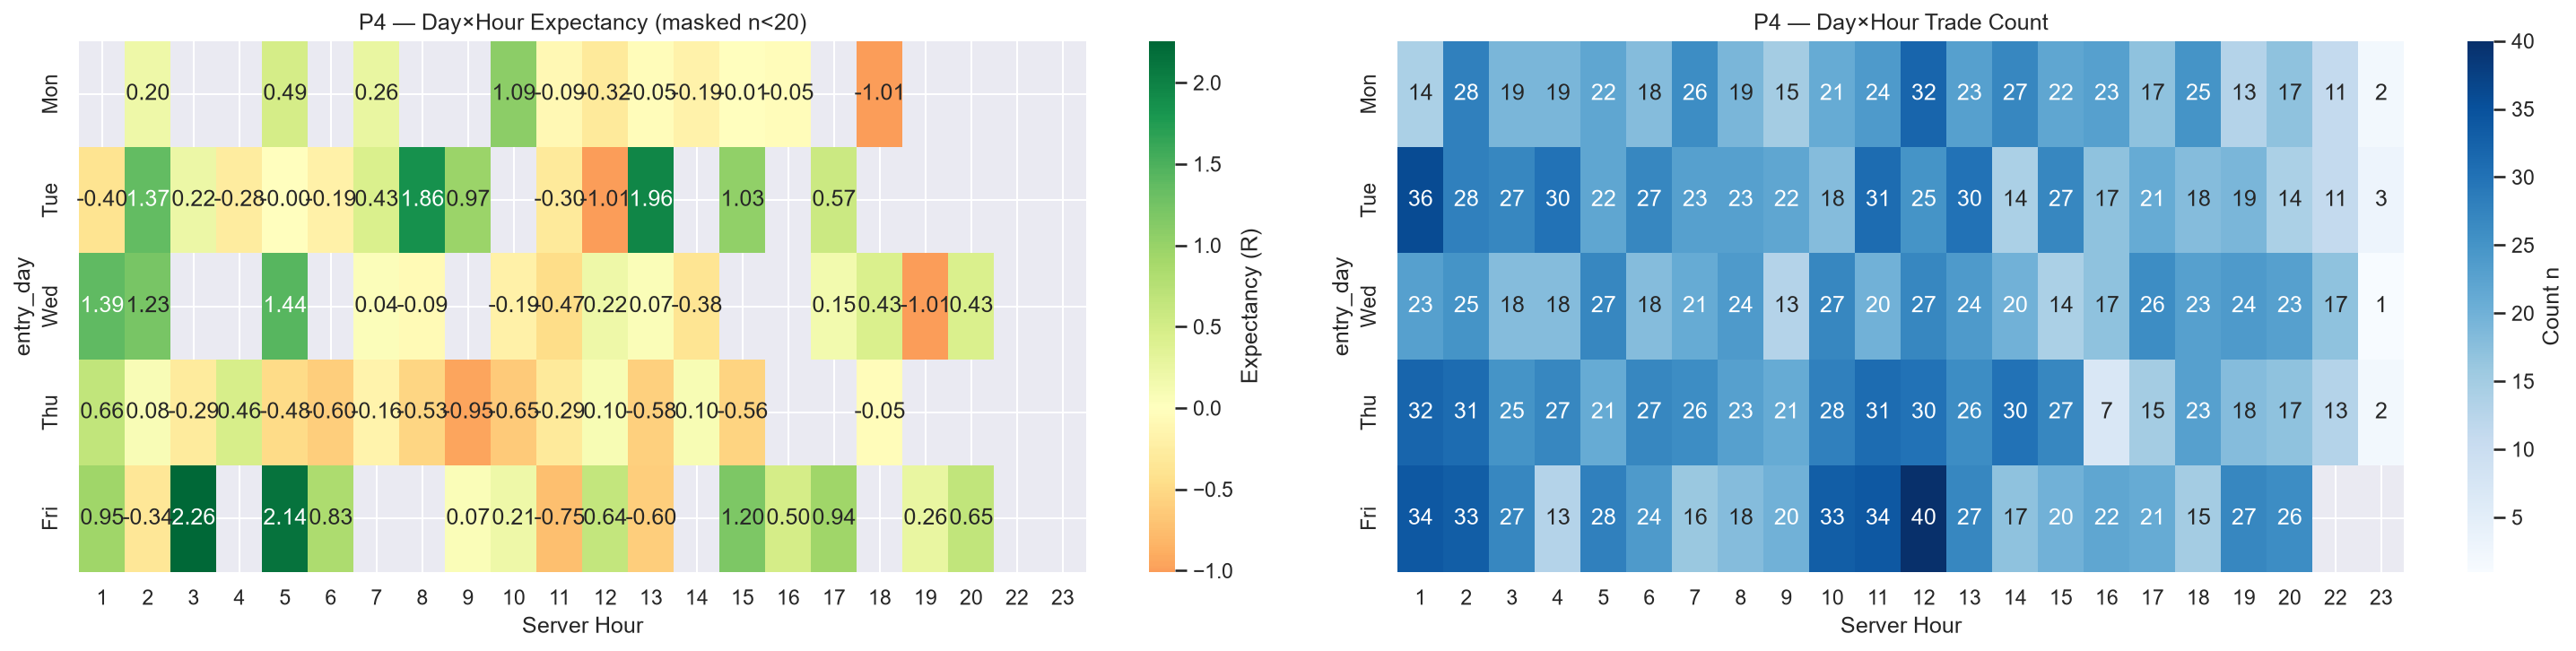

open_hour,1,2,3,4,5,6,7,8,9,10,...,13,14,15,16,17,18,19,20,22,23
entry_day,,,,,,,,,,,,,,,,,,,,,
Mon,14.0,28.0,19.0,19.0,22.0,18.0,26.0,19.0,15.0,21.0,...,23.0,27.0,22.0,23.0,17.0,25.0,13.0,17.0,11.0,2.0
Tue,36.0,28.0,27.0,30.0,22.0,27.0,23.0,23.0,22.0,18.0,...,30.0,14.0,27.0,17.0,21.0,18.0,19.0,14.0,11.0,3.0
Wed,23.0,25.0,18.0,18.0,27.0,18.0,21.0,24.0,13.0,27.0,...,24.0,20.0,14.0,17.0,26.0,23.0,24.0,23.0,17.0,1.0
Thu,32.0,31.0,25.0,27.0,21.0,27.0,26.0,23.0,21.0,28.0,...,26.0,30.0,27.0,7.0,15.0,23.0,18.0,17.0,13.0,2.0
Fri,34.0,33.0,27.0,13.0,28.0,24.0,16.0,18.0,20.0,33.0,...,27.0,17.0,20.0,22.0,21.0,15.0,27.0,26.0,NaN,NaN


In [26]:
# P4 Day × Hour heatmap
day_order = ['Mon','Tue','Wed','Thu','Fri']
pivot_E = df.pivot_table(values=PRIMARY_R, index='entry_day', columns='open_hour', aggfunc='mean')
pivot_n = df.pivot_table(values=PRIMARY_R, index='entry_day', columns='open_hour', aggfunc='count')
pivot_E = pivot_E.reindex([d for d in day_order if d in pivot_E.index])
pivot_n = pivot_n.reindex(pivot_E.index).reindex(columns=pivot_E.columns)
mask    = (pivot_n < 20).fillna(True)

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
sns.heatmap(pivot_E, mask=mask, cmap='RdYlGn', center=0, annot=True, fmt='.2f',
            ax=axes[0], cbar_kws={'label':'Expectancy (R)'})
axes[0].set_title('P4 — Day×Hour Expectancy (masked n<20)')
axes[0].set_xlabel('Server Hour')

sns.heatmap(pivot_n, cmap='Blues', annot=True, fmt='.0f',
            ax=axes[1], cbar_kws={'label':'Count n'})
axes[1].set_title('P4 — Day×Hour Trade Count')
axes[1].set_xlabel('Server Hour')
savefig('p4_day_hour_heatmap.png')

savetable(pivot_E, 'p4_day_hour_expectancy.csv')
savetable(pivot_n, 'p4_day_hour_n.csv')


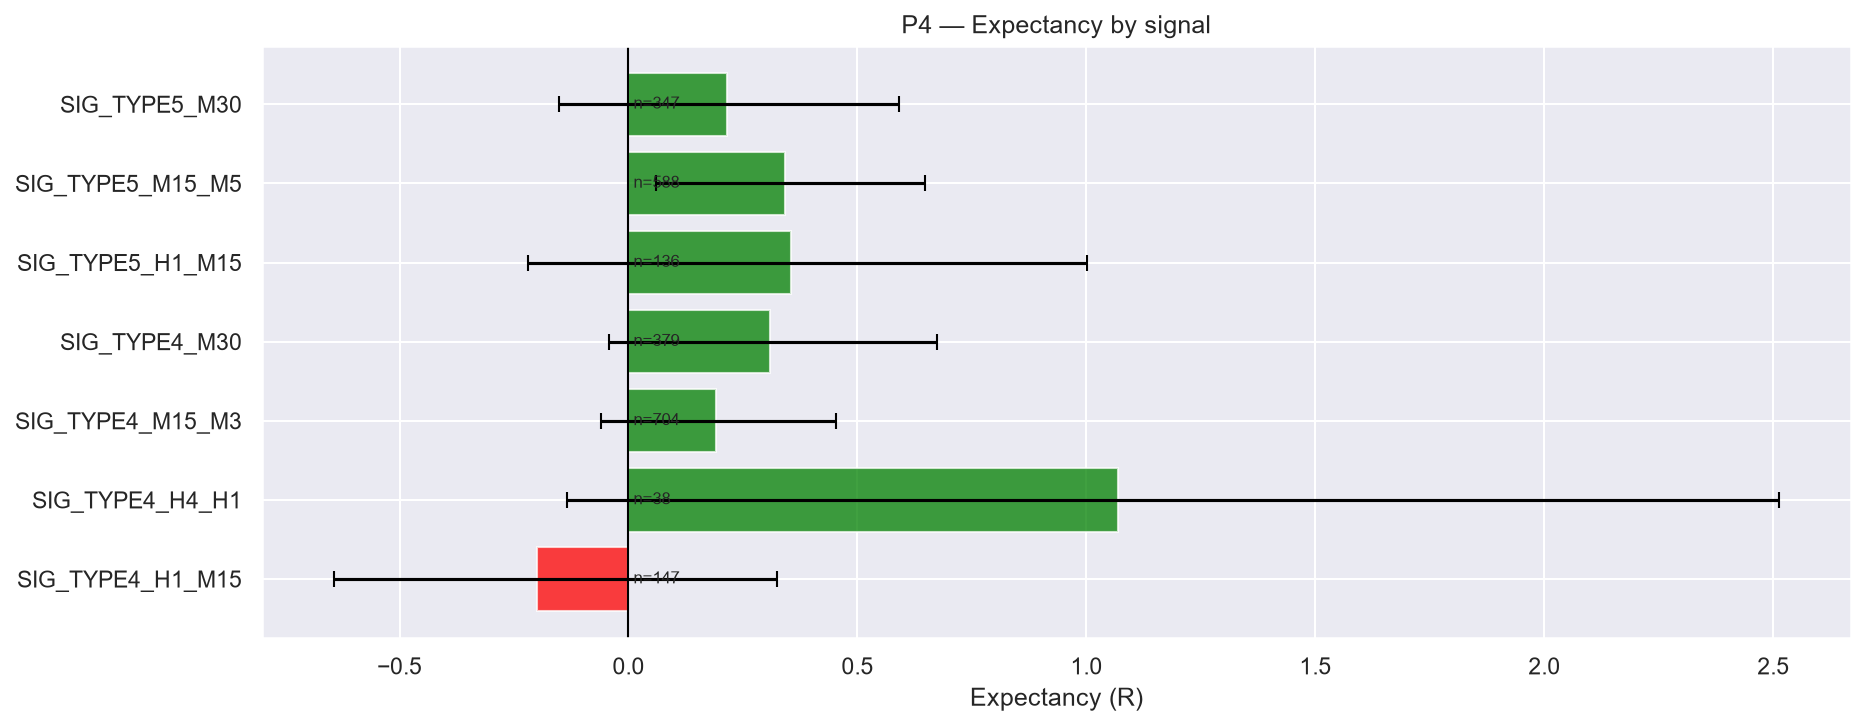

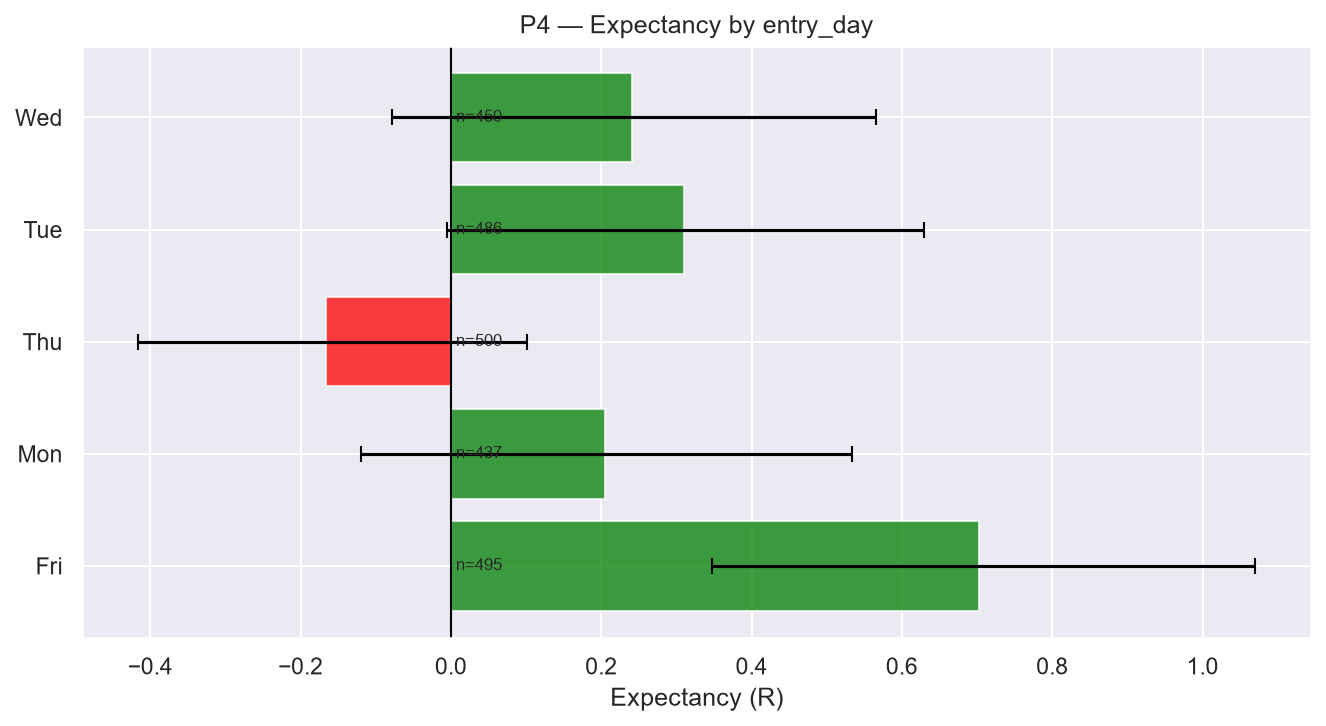

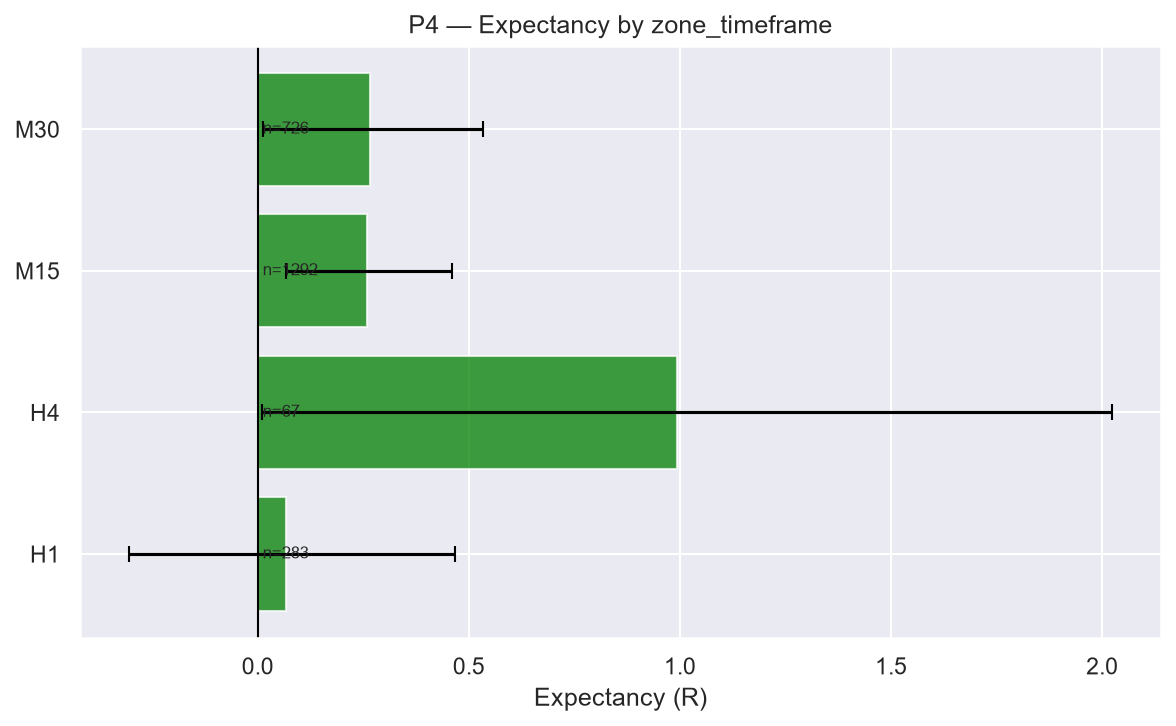

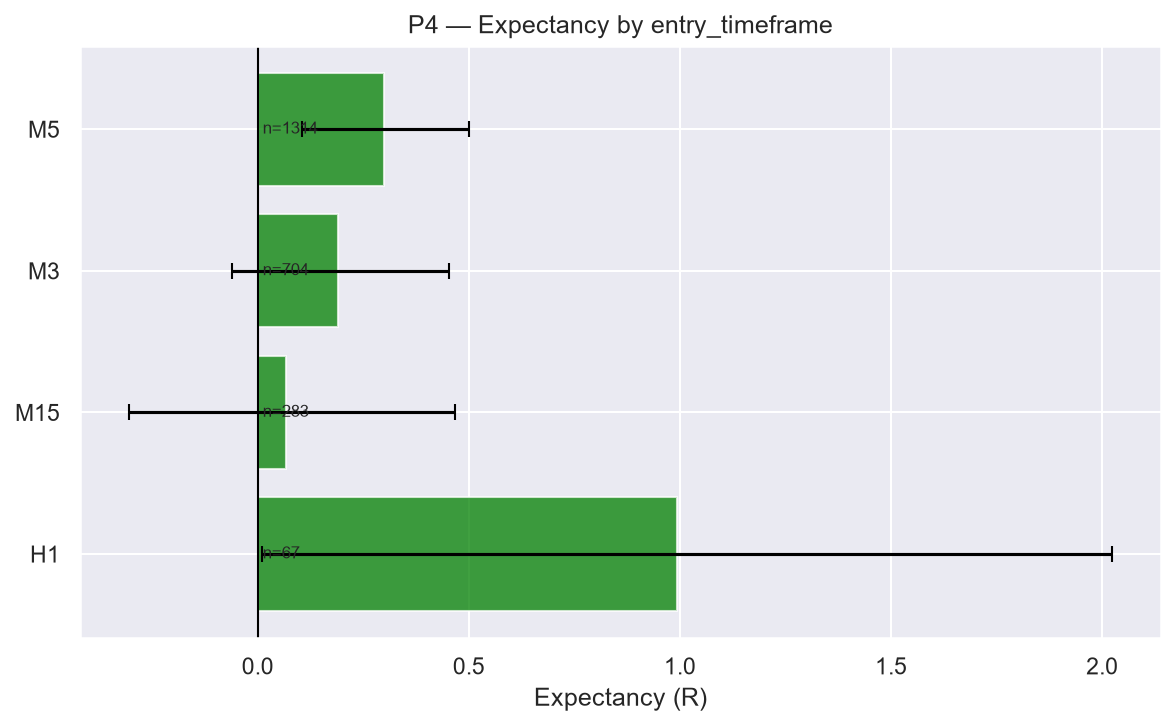

In [27]:
# P4 Bar charts for key dimensions
for dim in [USE_SIG, 'entry_day', 'zone_timeframe', 'entry_timeframe']:
    t = dim_tables.get(dim, pd.DataFrame())
    t_plot = t[t['n'] >= 30] if len(t) > 0 else pd.DataFrame()
    if len(t_plot) == 0:
        print(f'{dim}: no groups with n>=30, skipping chart.')
        continue
    colors_b = ['green' if e > 0 else 'red' for e in t_plot['expectancy']]
    fig, ax = plt.subplots(figsize=(max(8, len(t_plot)*1.8), 5))
    labels = [str(i) for i in t_plot.index]
    y_pos = range(len(t_plot))
    ax.barh(labels, t_plot['expectancy'].values, color=colors_b, alpha=0.75)
    err_lo_b = (t_plot['expectancy'] - t_plot['ci_lo']).fillna(0).values
    err_hi_b = (t_plot['ci_hi'] - t_plot['expectancy']).fillna(0).values
    ax.errorbar(t_plot['expectancy'].values, labels, xerr=[err_lo_b, err_hi_b],
                fmt='none', color='black', capsize=4)
    for i, (idx, row) in enumerate(t_plot.iterrows()):
        ax.text(0, i, f' n={int(row["n"])}', va='center', fontsize=8)
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('Expectancy (R)'); ax.set_title(f'P4 — Expectancy by {dim}')
    savefig(f'p4_expectancy_{dim}.png')


---
## Phase 5 — Zone-Quality and Entry Features

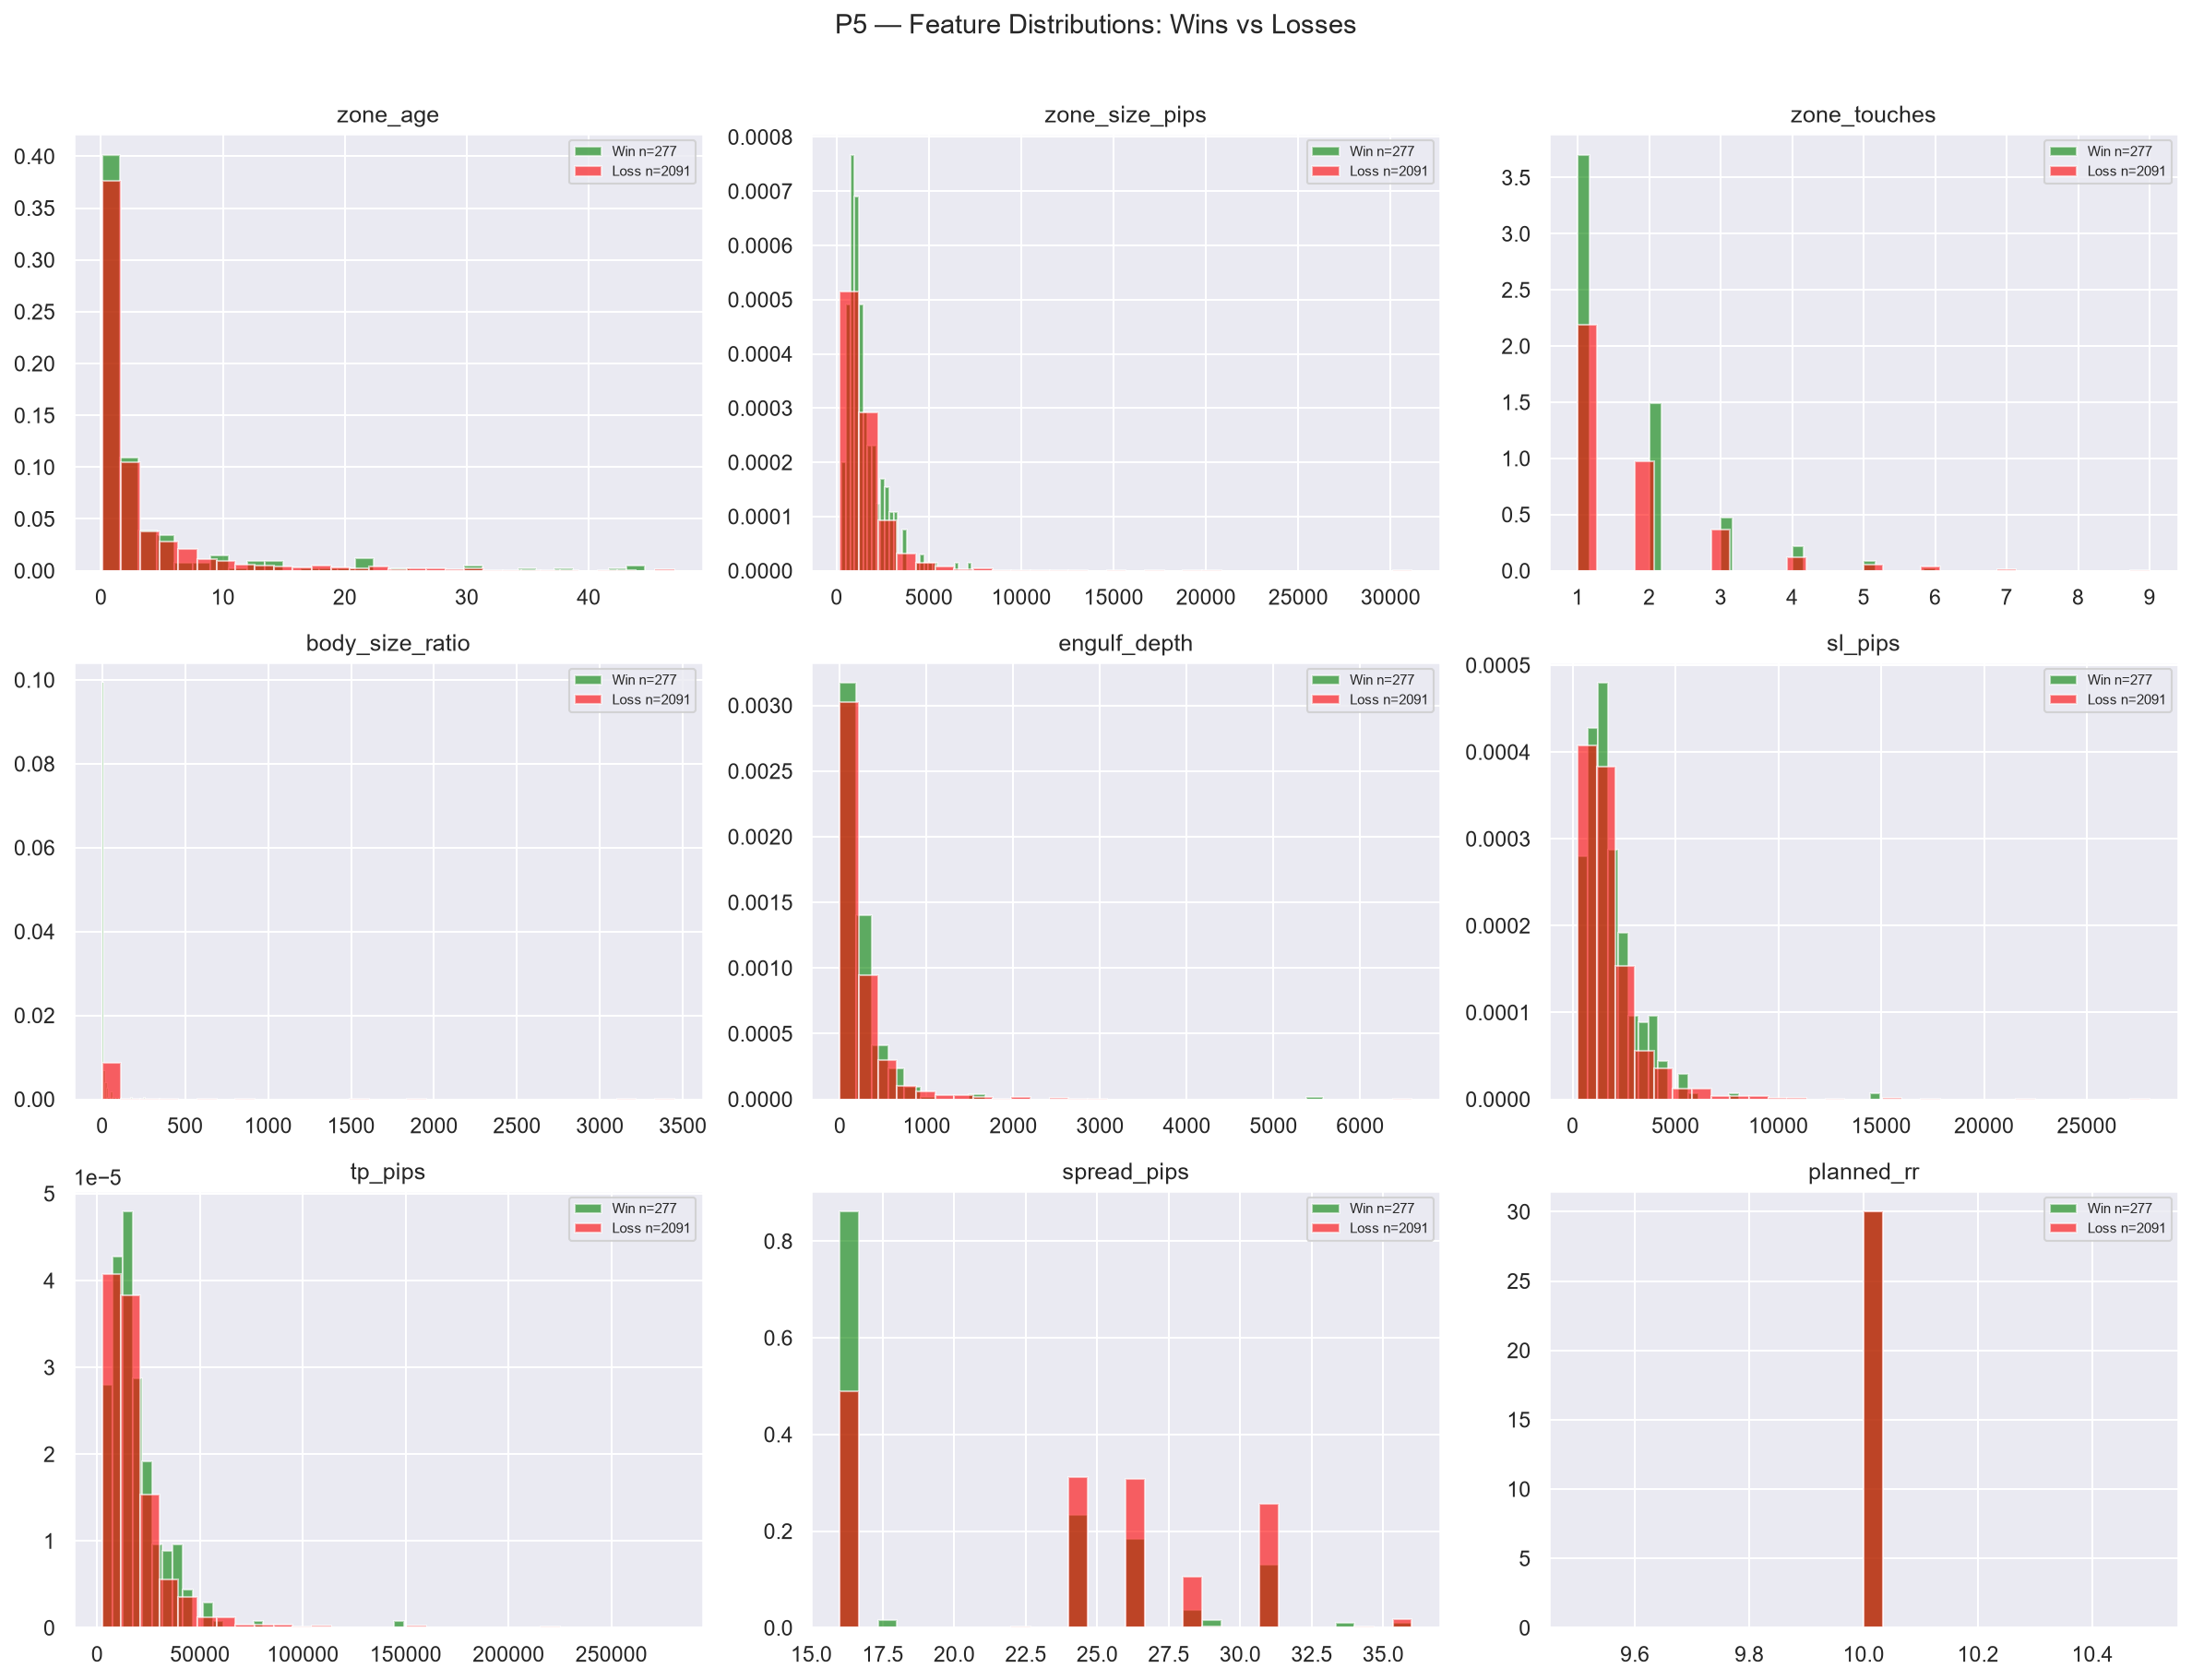

In [28]:
FEATURES = ['zone_age','zone_size_pips','zone_touches','body_size_ratio',
            'engulf_depth','sl_pips','tp_pips','spread_pips','planned_rr']

wins_df   = df[df[PRIMARY_R] > 0]
losses_df = df[df[PRIMARY_R] < 0]

# P5.1 Distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, feat in enumerate(FEATURES):
    ax = axes[i]
    w  = wins_df[feat].dropna()
    l  = losses_df[feat].dropna()
    ax.hist(w, bins=30, alpha=0.6, color='green', density=True, label=f'Win n={len(w)}')
    ax.hist(l, bins=30, alpha=0.6, color='red',   density=True, label=f'Loss n={len(l)}')
    ax.set_title(feat); ax.legend(fontsize=7)
plt.suptitle('P5 — Feature Distributions: Wins vs Losses', y=1.01, fontsize=14)
savefig('p5_feature_distributions.png')


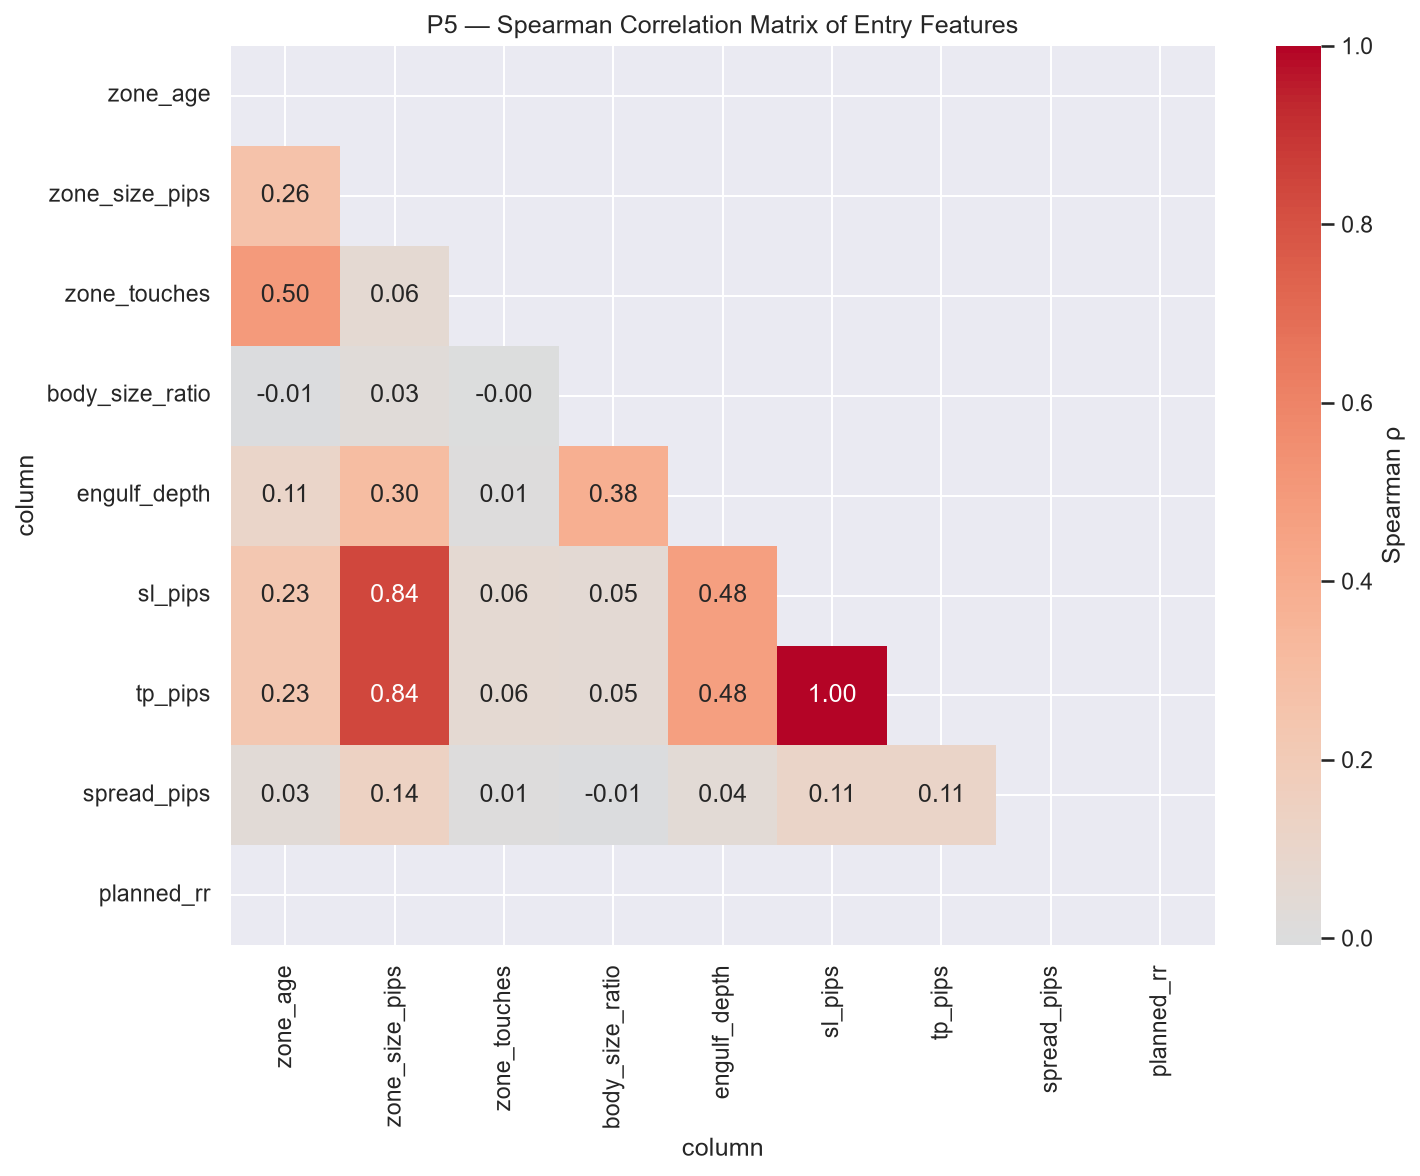

Redundant feature pairs (|ρ|>0.7): [('zone_size_pips', 'sl_pips', np.float64(0.836)), ('zone_size_pips', 'tp_pips', np.float64(0.836)), ('sl_pips', 'tp_pips', np.float64(1.0))]


In [29]:
# P5.2 Spearman correlation matrix
feat_df  = df[FEATURES].dropna()
corr_mat = feat_df.corr(method='spearman')
savetable(corr_mat, 'p5_spearman_corr_matrix.csv')

fig, ax = plt.subplots(figsize=(10, 8))
mask_tri = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask_tri, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, cbar_kws={'label':'Spearman ρ'})
ax.set_title('P5 — Spearman Correlation Matrix of Entry Features')
savefig('p5_spearman_heatmap.png')

redundant = [(c1, c2, round(corr_mat.loc[c1,c2],3))
             for i,c1 in enumerate(corr_mat.columns)
             for c2 in corr_mat.columns[i+1:]
             if abs(corr_mat.loc[c1,c2]) > 0.7]
print('Redundant feature pairs (|ρ|>0.7):', redundant if redundant else 'None')


In [30]:
# P5.3 Spearman correlation of each feature with result_R + FDR
feat_R = df[FEATURES + [PRIMARY_R]].dropna()
rho_rows = []
for feat in FEATURES:
    rho, pv = spearmanr(feat_R[feat], feat_R[PRIMARY_R])
    rho_rows.append({'feature': feat, 'spearman_rho': round(rho,4), 'pval_raw': round(pv,5)})
rho_df = pd.DataFrame(rho_rows)
rej5, padj5 = fdr_correct(rho_df['pval_raw'].values)
rho_df['pval_adj'] = padj5.round(5); rho_df['fdr_reject'] = rej5
savetable(rho_df.set_index('feature'), 'p5_feature_R_correlation.csv')
print(rho_df.sort_values('spearman_rho', key=abs, ascending=False).to_string(index=False))


        feature  spearman_rho  pval_raw  pval_adj  fdr_reject
    spread_pips       -0.3848   0.00000       NaN        True
        sl_pips        0.2029   0.00000       NaN        True
        tp_pips        0.2029   0.00000       NaN        True
 zone_size_pips        0.1320   0.00000       NaN        True
   engulf_depth        0.1013   0.00000       NaN        True
       zone_age        0.0178   0.38589       NaN       False
body_size_ratio        0.0050   0.80781       NaN       False
   zone_touches        0.0041   0.84141       NaN       False
     planned_rr           NaN       NaN       NaN       False


In [31]:
# P5.4 Quintile bins expectancy
for feat in FEATURES:
    sub = df[[feat, PRIMARY_R]].dropna()
    nu  = sub[feat].nunique()
    q   = min(5, nu)
    if q < 2:
        print(f'{feat}: {nu} unique values, skip quintile.'); continue
    try:
        sub = sub.copy()
        sub['bin'] = pd.qcut(sub[feat], q=q, duplicates='drop')
    except Exception:
        sub['bin'] = pd.cut(sub[feat], bins=q, duplicates='drop')
    t5 = sub.groupby('bin', observed=True)[PRIMARY_R].agg(
        n='count', expectancy='mean', win_rate=lambda x: (x>0).mean())
    t5['ci_lo'] = [bootstrap_ci(sub[sub['bin']==b][PRIMARY_R])[0]
                   if (sub['bin']==b).sum()>=30 else np.nan for b in t5.index]
    t5['ci_hi'] = [bootstrap_ci(sub[sub['bin']==b][PRIMARY_R])[1]
                   if (sub['bin']==b).sum()>=30 else np.nan for b in t5.index]
    savetable(t5, f'p5_quintile_{feat}.csv')
print('Quintile tables saved.')


planned_rr: 1 unique values, skip quintile.
Quintile tables saved.


In [32]:
# P5.5 Derived features
df['spread_to_sl']    = df['spread_pips'] / df['sl_pips']
df['zone_to_sl']      = df['zone_size_pips'] / df['sl_pips']
df['sl_to_zone']      = df['sl_pips'] / df['zone_size_pips']
df['touches_per_age'] = df['zone_touches'] / df['zone_age'].replace(0, np.nan)

DERIVED = ['spread_to_sl','zone_to_sl','sl_to_zone','touches_per_age']
rho_d = []
for feat in DERIVED:
    sub = df[[feat, PRIMARY_R]].dropna()
    rho, pv = spearmanr(sub[feat], sub[PRIMARY_R])
    rho_d.append({'feature': feat, 'spearman_rho': round(rho,4), 'pval_raw': round(pv,5)})
rho_d_df = pd.DataFrame(rho_d)
rej_d, padj_d = fdr_correct(rho_d_df['pval_raw'].values)
rho_d_df['pval_adj'] = padj_d.round(5); rho_d_df['fdr_reject'] = rej_d
savetable(rho_d_df.set_index('feature'), 'p5_derived_features_R_corr.csv')
print(rho_d_df.to_string(index=False))


        feature  spearman_rho  pval_raw  pval_adj  fdr_reject
   spread_to_sl       -0.3689   0.00000   0.00000        True
     zone_to_sl       -0.1119   0.00000   0.00000        True
     sl_to_zone        0.1119   0.00000   0.00000        True
touches_per_age       -0.0159   0.44033   0.44033       False


---
## Phase 6 — Cost Analysis

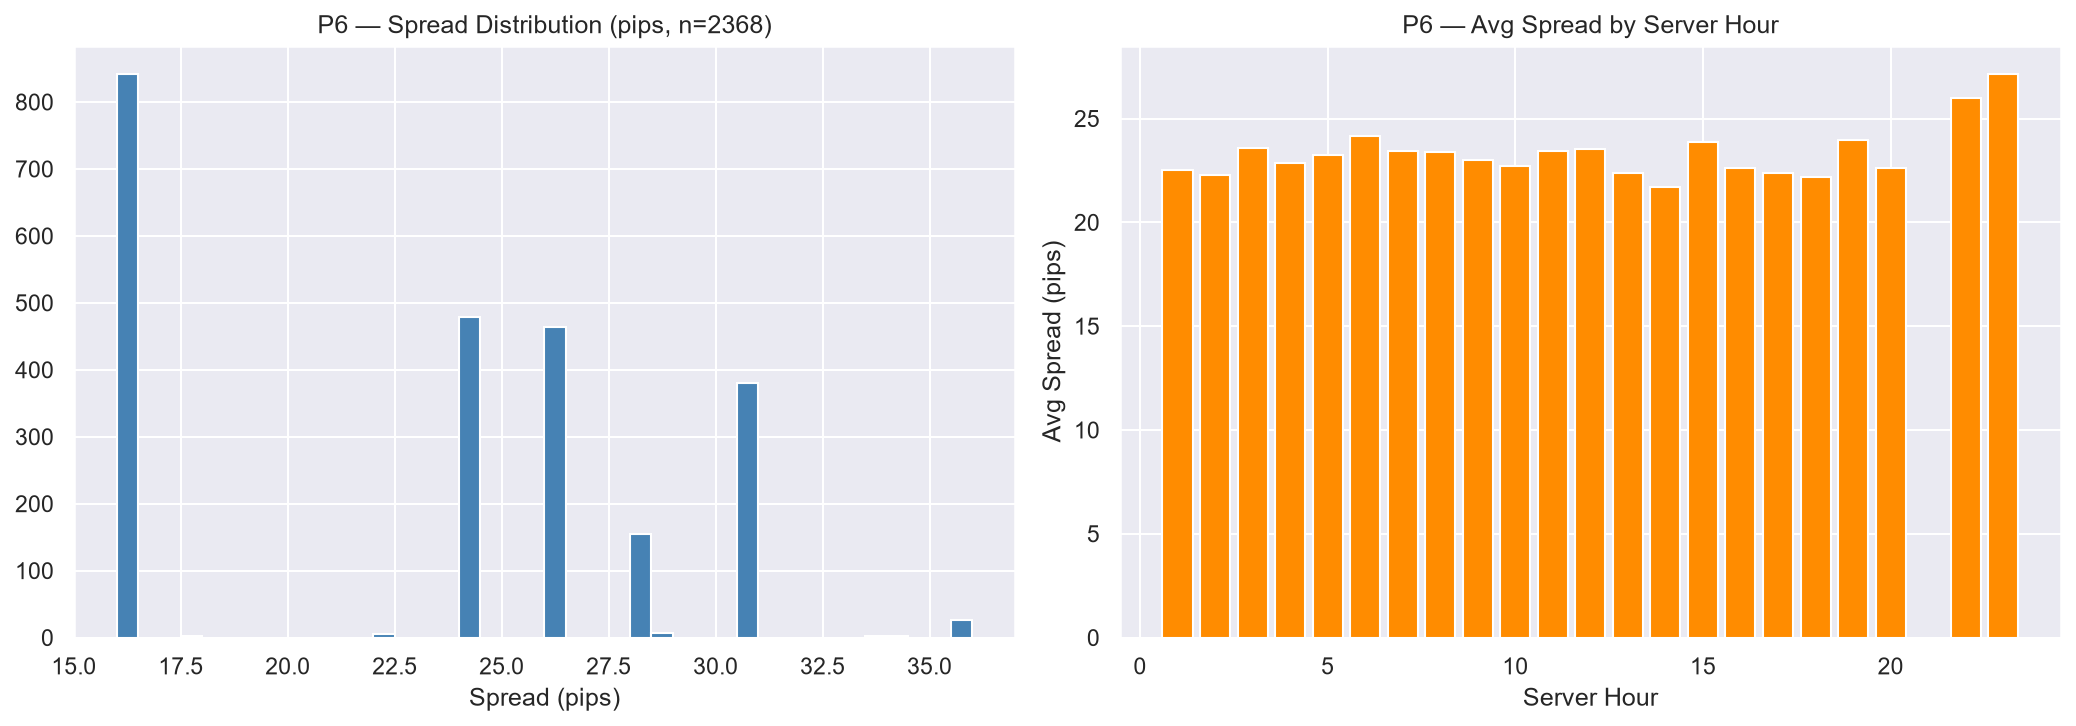

In [33]:
# P6.1 Spread distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df['spread_pips'].dropna(), bins=40, color='steelblue', edgecolor='white')
axes[0].set_title(f'P6 — Spread Distribution (pips, n={df["spread_pips"].notna().sum()})')
axes[0].set_xlabel('Spread (pips)')

spread_hour = df.groupby('open_hour')['spread_pips'].mean()
axes[1].bar(spread_hour.index, spread_hour.values, color='darkorange')
axes[1].set_title('P6 — Avg Spread by Server Hour')
axes[1].set_xlabel('Server Hour'); axes[1].set_ylabel('Avg Spread (pips)')
savefig('p6_spread_analysis.png')


In [34]:
# P6.2-4 Spread-to-SL & filter thresholds
sub6 = df[['spread_to_sl', PRIMARY_R]].dropna()
try:
    sub6 = sub6.copy()
    sub6['bin'] = pd.qcut(sub6['spread_to_sl'], q=5, duplicates='drop')
    stsl_t = sub6.groupby('bin', observed=True)[PRIMARY_R].agg(n='count', expectancy='mean')
    savetable(stsl_t, 'p6_spread_to_sl_bins.csv')
    print('Spread-to-SL quintile expectancy:'); print(stsl_t)
except Exception as e:
    print(f'Could not bin spread_to_sl: {e}')

avg_stsl = float(df['spread_to_sl'].mean())
print(f'\nAvg spread_to_sl: {avg_stsl:.4f}  |  Est total spread cost: {avg_stsl*n_trades:.1f}R')

thresh_rows = []
for max_s in [0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20, 0.25]:
    kept = df[df['spread_to_sl'] <= max_s]
    if len(kept) < 30: continue
    r = kept[PRIMARY_R]
    thresh_rows.append({'max_spread_to_sl': max_s, 'n_kept': len(kept),
                        'expectancy': round(float(r.mean()),3),
                        'total_R': round(float(r.sum()),3)})
thresh_df = pd.DataFrame(thresh_rows).set_index('max_spread_to_sl')
savetable(thresh_df, 'p6_spread_filter_thresholds.csv')
print('\nSpread filter thresholds (hypothesis — requires out-of-sample validation):')
print(thresh_df)


Spread-to-SL quintile expectancy:
                        n  expectancy
bin                                  
(-0.000271, 0.00902]  474    1.048211
(0.00902, 0.013]      473    0.239256
(0.013, 0.0186]       474    0.144886
(0.0186, 0.0266]      474   -0.216901
(0.0266, 0.0969]      473    0.078607

Avg spread_to_sl: 0.0186  |  Est total spread cost: 44.0R

Spread filter thresholds (hypothesis — requires out-of-sample validation):
                  n_kept  expectancy  total_R
max_spread_to_sl                             
0.01                 603       0.861  519.315
0.02                1526       0.438  668.883
0.03                2010       0.291  585.108
0.05                2314       0.270  623.845
0.10                2368       0.259  613.066
0.15                2368       0.259  613.066
0.20                2368       0.259  613.066
0.25                2368       0.259  613.066


---
## Phase 7 — Trade-Path and Exit Analysis

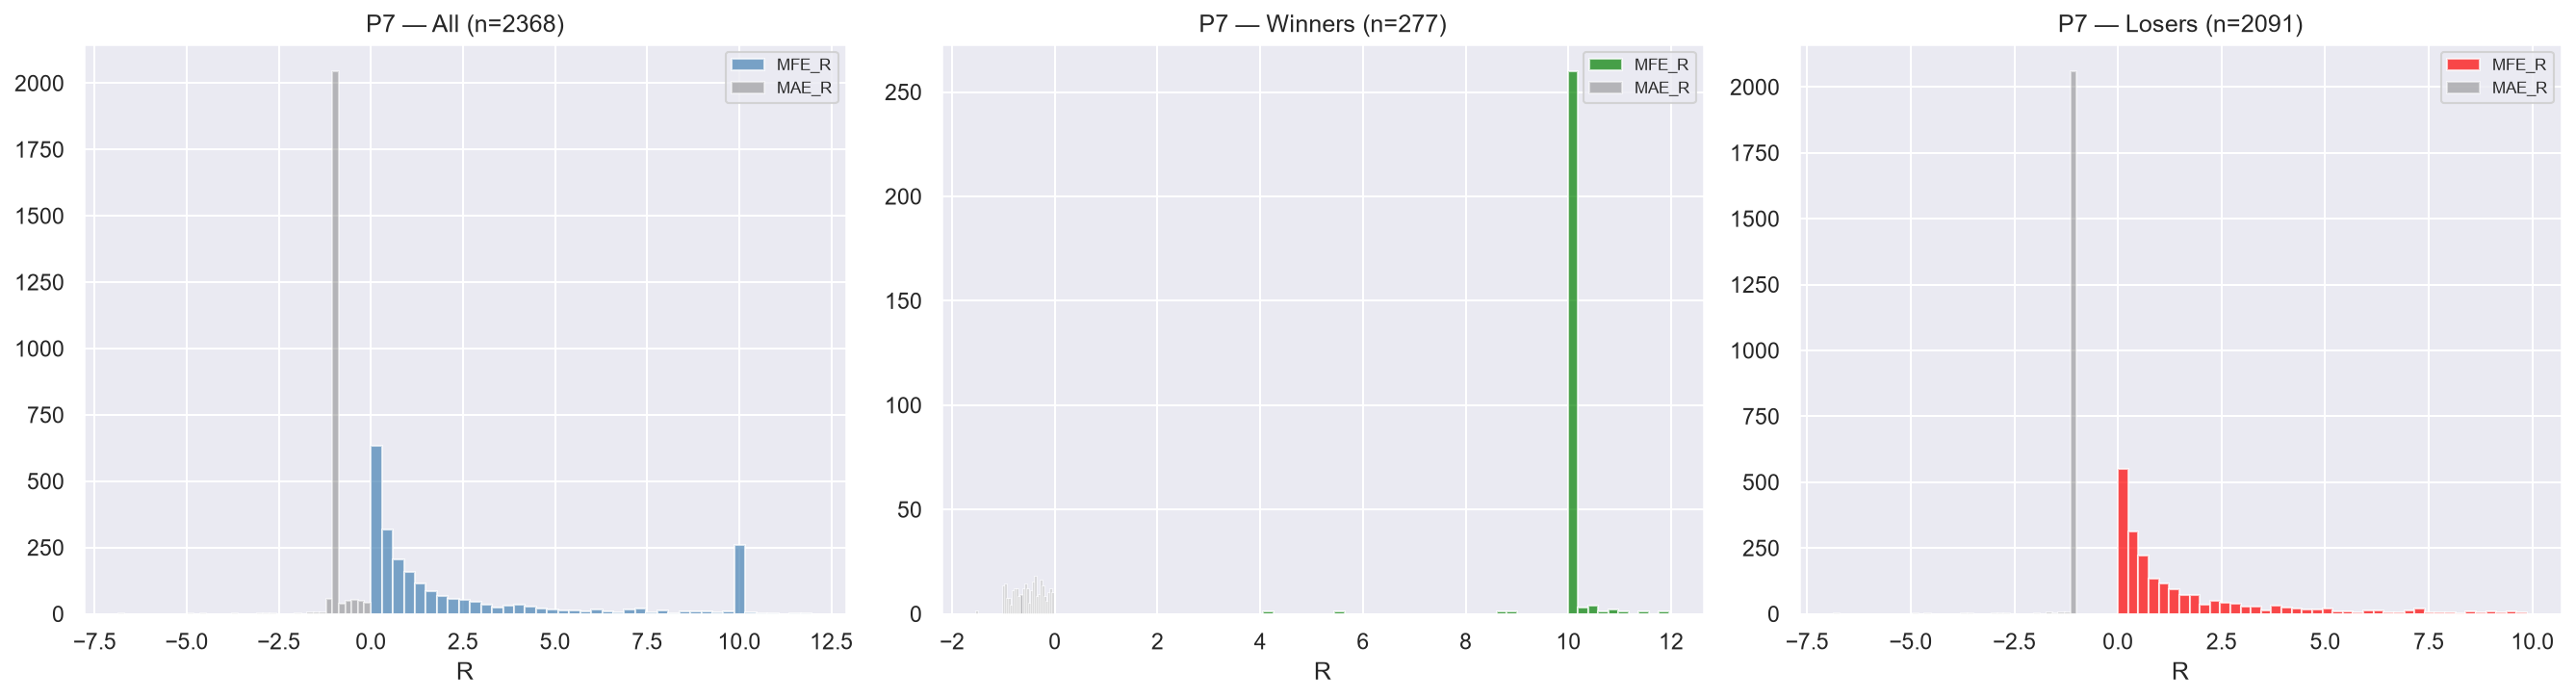

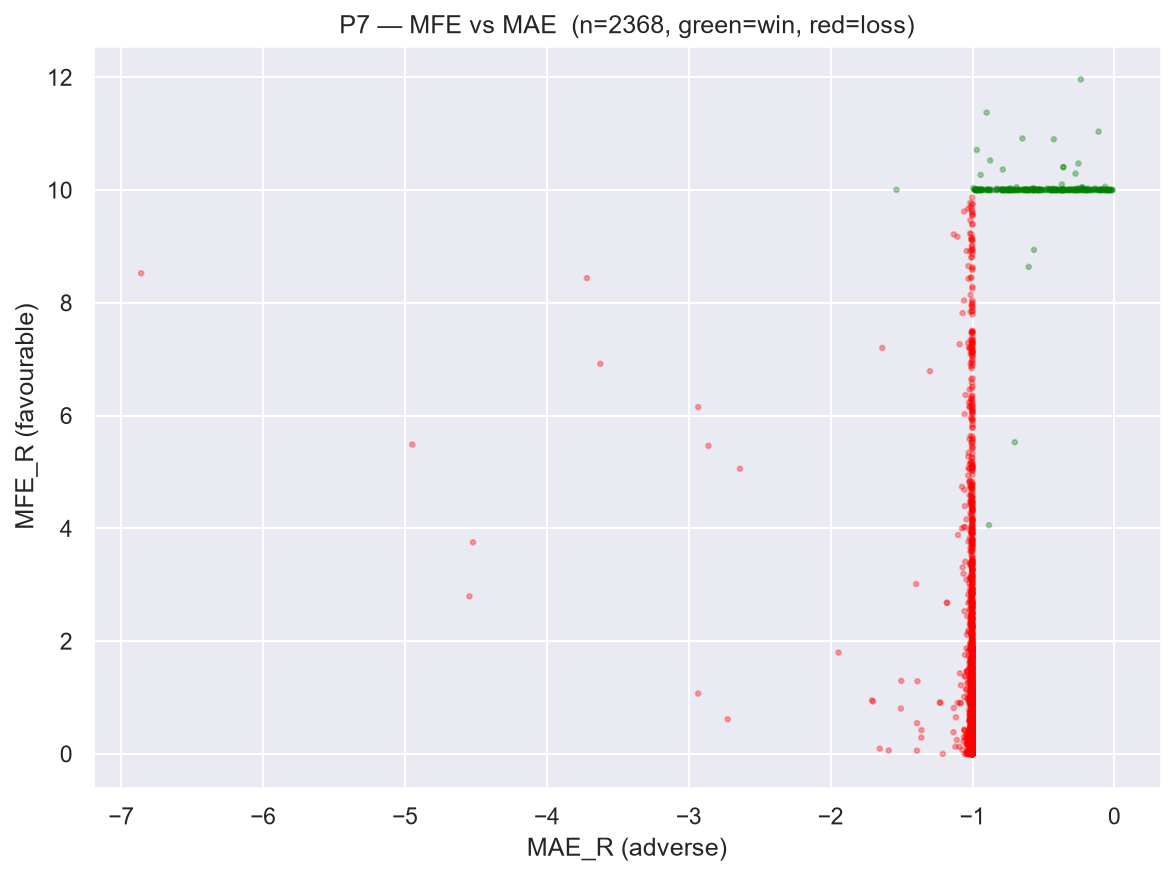

In [35]:
# P7.1 Excursion profiles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, grp, label, c in zip(axes,
        [df, df[df[PRIMARY_R]>0], df[df[PRIMARY_R]<0]],
        ['All','Winners','Losers'],['steelblue','green','red']):
    ax.hist(grp['MFE_R'].dropna(), bins=40, alpha=0.7, color=c, label='MFE_R')
    ax.hist(grp['MAE_R'].dropna(), bins=40, alpha=0.5, color='gray', label='MAE_R')
    ax.set_title(f'P7 — {label} (n={len(grp)})')
    ax.set_xlabel('R'); ax.legend(fontsize=8)
savefig('p7_excursion_profiles.png')

# MFE vs MAE scatter
fig, ax = plt.subplots(figsize=(8,6))
c_sc = ['green' if r>0 else 'red' for r in df[PRIMARY_R]]
ax.scatter(df['MAE_R'], df['MFE_R'], c=c_sc, alpha=0.3, s=5)
ax.set_xlabel('MAE_R (adverse)'); ax.set_ylabel('MFE_R (favourable)')
ax.set_title(f'P7 — MFE vs MAE  (n={len(df)}, green=win, red=loss)')
savefig('p7_mfe_mae_scatter.png')


In [36]:
# P7.2 Milestone rates
milestone_rows = []
for rR, col in [(1,'min_to_1R'),(2,'min_to_2R'),(3,'min_to_3R')]:
    reached = df[col].notna()
    n_r = int(reached.sum())
    if n_r == 0:
        print(f'+{rR}R: 0 trades reached this milestone'); continue
    pct  = 100 * n_r / n_trades
    wr_r = float((df[reached][PRIMARY_R] > 0).mean())
    med_t = float(df[reached][col].median())
    p75_t = float(df[reached][col].quantile(0.75))
    milestone_rows.append({'milestone': f'+{rR}R', 'n_reached': n_r,
                            'pct_of_all': round(pct,1), 'win_rate_of_reached': round(wr_r,3),
                            'median_min': round(med_t,1), 'p75_min': round(p75_t,1)})
    print(f'+{rR}R reached {n_r}/{n_trades} ({pct:.1f}%), WR={wr_r:.3f}, med={med_t:.0f}min, p75={p75_t:.0f}min')

if milestone_rows:
    savetable(pd.DataFrame(milestone_rows).set_index('milestone'), 'p7_milestone_rates.csv')


+1R reached 1139/2368 (48.1%), WR=0.243, med=92min, p75=210min
+2R reached 794/2368 (33.5%), WR=0.349, med=274min, p75=652min
+3R reached 630/2368 (26.6%), WR=0.440, med=515min, p75=1358min


In [37]:
# P7.3 Giveback analysis
giveback_rows = []
for rR, col_hit, col_min in [(1,'min_to_1R','min_R_after_1R'),(2,'min_to_2R','min_R_after_2R')]:
    hit = df[df[col_hit].notna()]
    if len(hit) == 0: continue
    dnw = hit[hit[PRIMARY_R] <= 0]
    total_given = float(dnw[PRIMARY_R].sum())
    print(f'Reached +{rR}R: {len(hit)}, did NOT win: {len(dnw)} ({100*len(dnw)/len(hit):.1f}%), R lost: {total_given:.3f}')
    if col_min in dnw.columns and dnw[col_min].notna().sum() > 0:
        print(f'  {col_min} for non-winners: {dnw[col_min].describe().round(3).to_dict()}')
    giveback_rows.append({'milestone': f'+{rR}R', 'n_reached': len(hit),
                          'n_did_not_win': len(dnw), 'pct_did_not_win': round(100*len(dnw)/len(hit),1),
                          'total_R_lost': round(total_given,3)})
if giveback_rows:
    savetable(pd.DataFrame(giveback_rows).set_index('milestone'), 'p7_giveback.csv')


Reached +1R: 1139, did NOT win: 862 (75.7%), R lost: -900.262
  min_R_after_1R for non-winners: {'count': 862.0, 'mean': -1.046, 'std': 0.346, 'min': -6.86, '25%': -1.008, '50%': -1.003, '75%': -1.001, 'max': -1.0}
Reached +2R: 794, did NOT win: 517 (65.1%), R lost: -549.807
  min_R_after_2R for non-winners: {'count': 517.0, 'mean': -1.065, 'std': 0.435, 'min': -6.86, '25%': -1.009, '50%': -1.003, '75%': -1.001, 'max': -1.0}


In [38]:
# P7.4 Stop placement (MAE of winners)
winners7 = df[df[PRIMARY_R] > 0]
print(f'Winners: {len(winners7)}')
sl_rows = []
for thr in [-0.25, -0.5, -0.75]:
    pct_stopped = float((winners7['MAE_R'] < thr).mean()) * 100
    print(f'  MAE_R < {thr}R: {pct_stopped:.1f}% of winners would be stopped by tighter stop')
    sl_rows.append({'tighter_sl': thr, 'pct_winners_stopped': round(pct_stopped,1)})
savetable(pd.DataFrame(sl_rows).set_index('tighter_sl'), 'p7_stop_placement.csv')
print('Note: tighter stops change position sizing geometry — treat as directional hypothesis only.')


Winners: 277
  MAE_R < -0.25R: 77.3% of winners would be stopped by tighter stop
  MAE_R < -0.5R: 49.5% of winners would be stopped by tighter stop
  MAE_R < -0.75R: 22.7% of winners would be stopped by tighter stop
Note: tighter stops change position sizing geometry — treat as directional hypothesis only.


In [39]:
# P7.5 Alternative TP levels
tp_levels = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
tp_results = []
for tp in tp_levels:
    sim_R = []
    skipped = 0
    for _, row in df.iterrows():
        mfe = row['MFE_R']
        if tp <= 1.0:
            reached = mfe >= tp
        elif tp <= 2.0:
            reached = pd.notna(row['min_to_2R']) and mfe >= tp
        elif tp <= 3.0:
            reached = pd.notna(row['min_to_3R']) and mfe >= tp
        else:
            reached = False
        if reached:
            sim_R.append(tp)
        else:
            if tp > row['planned_rr'] and row['exit_reason'] == 'TP':
                skipped += 1
            sim_R.append(row[PRIMARY_R])
    sim_R = np.array(sim_R)
    pf_tp = pf_fn(sim_R)
    tp_results.append({'tp_level': tp, 'n': n_trades,
                       'win_rate': round(float((sim_R>0).mean()),3),
                       'expectancy': round(float(sim_R.mean()),3),
                       'profit_factor': round(pf_tp,3),
                       'note': f'approx ({skipped} TP-exit trades above planned_rr)' if skipped>0 else 'exact'})

tp_df = pd.DataFrame(tp_results).set_index('tp_level')
savetable(tp_df, 'p7_alt_tp_levels.csv')
print(tp_df.to_string())
print('\nTP > planned_rr cannot be evaluated for trades that closed at original TP (exit path unknown).')


             n  win_rate  expectancy  profit_factor   note
tp_level                                                  
0.50      2368     0.633      -0.054          0.855  exact
0.75      2368     0.539      -0.062          0.868  exact
1.00      2368     0.481      -0.043          0.917  exact
1.25      2368     0.335      -0.254          0.623  exact
1.50      2368     0.335      -0.170          0.747  exact
2.00      2368     0.335      -0.003          0.996  exact
2.50      2368     0.266      -0.079          0.893  exact
3.00      2368     0.266       0.054          1.072  exact

TP > planned_rr cannot be evaluated for trades that closed at original TP (exit path unknown).


In [40]:
# P7.6 Breakeven simulation
be_rows = []
for trigger, hit_col, after_col in [(1.0,'min_to_1R','min_R_after_1R'),(2.0,'min_to_2R','min_R_after_2R')]:
    sim_be = df[PRIMARY_R].values.copy().astype(float)
    n_stopped = 0
    for i, row in df.iterrows():
        if pd.notna(row.get(hit_col)) and pd.notna(row.get(after_col)):
            if row[after_col] <= 0:
                sim_be[i] = 0.0
                n_stopped += 1
    pf_be = pf_fn(sim_be)
    be_rows.append({'be_trigger': f'+{trigger}R', 'n_stopped_at_BE': n_stopped,
                    'win_rate': round(float((sim_be>0).mean()),3),
                    'expectancy': round(float(sim_be.mean()),3),
                    'profit_factor': round(pf_be,3),
                    'note': 'approximate — where milestone columns available'})
be_df = pd.DataFrame(be_rows).set_index('be_trigger')
savetable(be_df, 'p7_breakeven_simulation.csv')
print(be_df)


            n_stopped_at_BE  win_rate  expectancy  profit_factor  \
be_trigger                                                         
+1.0R                   986     0.065       0.121           1.23   
+2.0R                   587     0.087       0.202           1.30   

                                                       note  
be_trigger                                                   
+1.0R       approximate — where milestone columns available  
+2.0R       approximate — where milestone columns available  


In [41]:
# P7.7 Time stop
t1r_vals = df['min_to_1R'].dropna()
print('min_to_1R percentiles:', {f'p{p}': round(float(t1r_vals.quantile(p/100)),1) for p in [50,75,90]})
for pv, lab in [(50,'p50'),(75,'p75'),(90,'p90')]:
    N = float(t1r_vals.quantile(pv/100))
    not_reached = df[(df['min_to_1R'].isna()) & (df['duration_min'] >= N)]
    print(f'Time stop {lab} ({N:.0f}min): {len(not_reached)} trades ({100*len(not_reached)/n_trades:.1f}%), '
          f'expectancy={not_reached[PRIMARY_R].mean():.3f}R')


min_to_1R percentiles: {'p50': 91.5, 'p75': 209.6, 'p90': 616.5}
Time stop p50 (92min): 517 trades (21.8%), expectancy=-1.019R
Time stop p75 (210min): 287 trades (12.1%), expectancy=-1.025R
Time stop p90 (617min): 104 trades (4.4%), expectancy=-1.052R


In [42]:
# P7.8 Duration analysis
df['dur_bin'] = pd.qcut(df['duration_min'], q=5, duplicates='drop')
dur_t = df.groupby('dur_bin', observed=True)[PRIMARY_R].agg(n='count', expectancy='mean')
savetable(dur_t, 'p7_duration_buckets.csv')
print('Expectancy by duration quintile:'); print(dur_t)


Expectancy by duration quintile:
                       n  expectancy
dur_bin                             
(0.299, 48.7]        474   -1.007243
(48.7, 145.66]       473   -0.891943
(145.66, 474.04]     474   -0.753966
(474.04, 2714.76]    473    0.941317
(2714.76, 153240.0]  474    3.005327


In [43]:
# P7.9 Excursion flag
xt = pd.crosstab(df['excursion_flag'], df['exit_reason'], margins=True)
print('Excursion flag × exit reason:'); print(xt)
flag_stats = df.groupby('excursion_flag')[PRIMARY_R].describe().round(3)
savetable(flag_stats, 'p7_excursion_flag_stats.csv')


Excursion flag × exit reason:
exit_reason      OPEN    SL   TP   All
excursion_flag                        
AMBIGUOUS_SL_TP     0     0    1     1
OK                  0  2091  272  2363
OPEN                4     0    0     4
All                 4  2091  273  2368


,count,mean,std,min,25%,50%,75%,max
excursion_flag,,,,,,,,
AMBIGUOUS_SL_TP,1.0,10.004,NaN,10.004,10.004,10.004,10.004,10.004
OK,2363.0,0.248,3.539,-6.860,-1.006,-1.002,-1.000,11.962
OPEN,4.0,4.079,2.988,0.433,2.270,4.489,6.299,6.907


                 n  win_rate  expectancy  total_R  profit_factor  max_drawdown_R                                  note
label                                                                                                                 
Baseline      2368     0.117       0.259  613.066          1.286        -382.667                                 exact
TP@3.0R       2368     0.266       0.054  127.195          1.072        -162.209  approx for TP exits above planned_rr
TP@2.0R       2368     0.335      -0.003   -6.024          0.996        -162.125  approx for TP exits above planned_rr
TP@1.0R       2368     0.481      -0.043 -102.568          0.917        -151.505  approx for TP exits above planned_rr
BE after +1R  2368     0.065       0.121  286.058          1.230        -227.022                           approximate


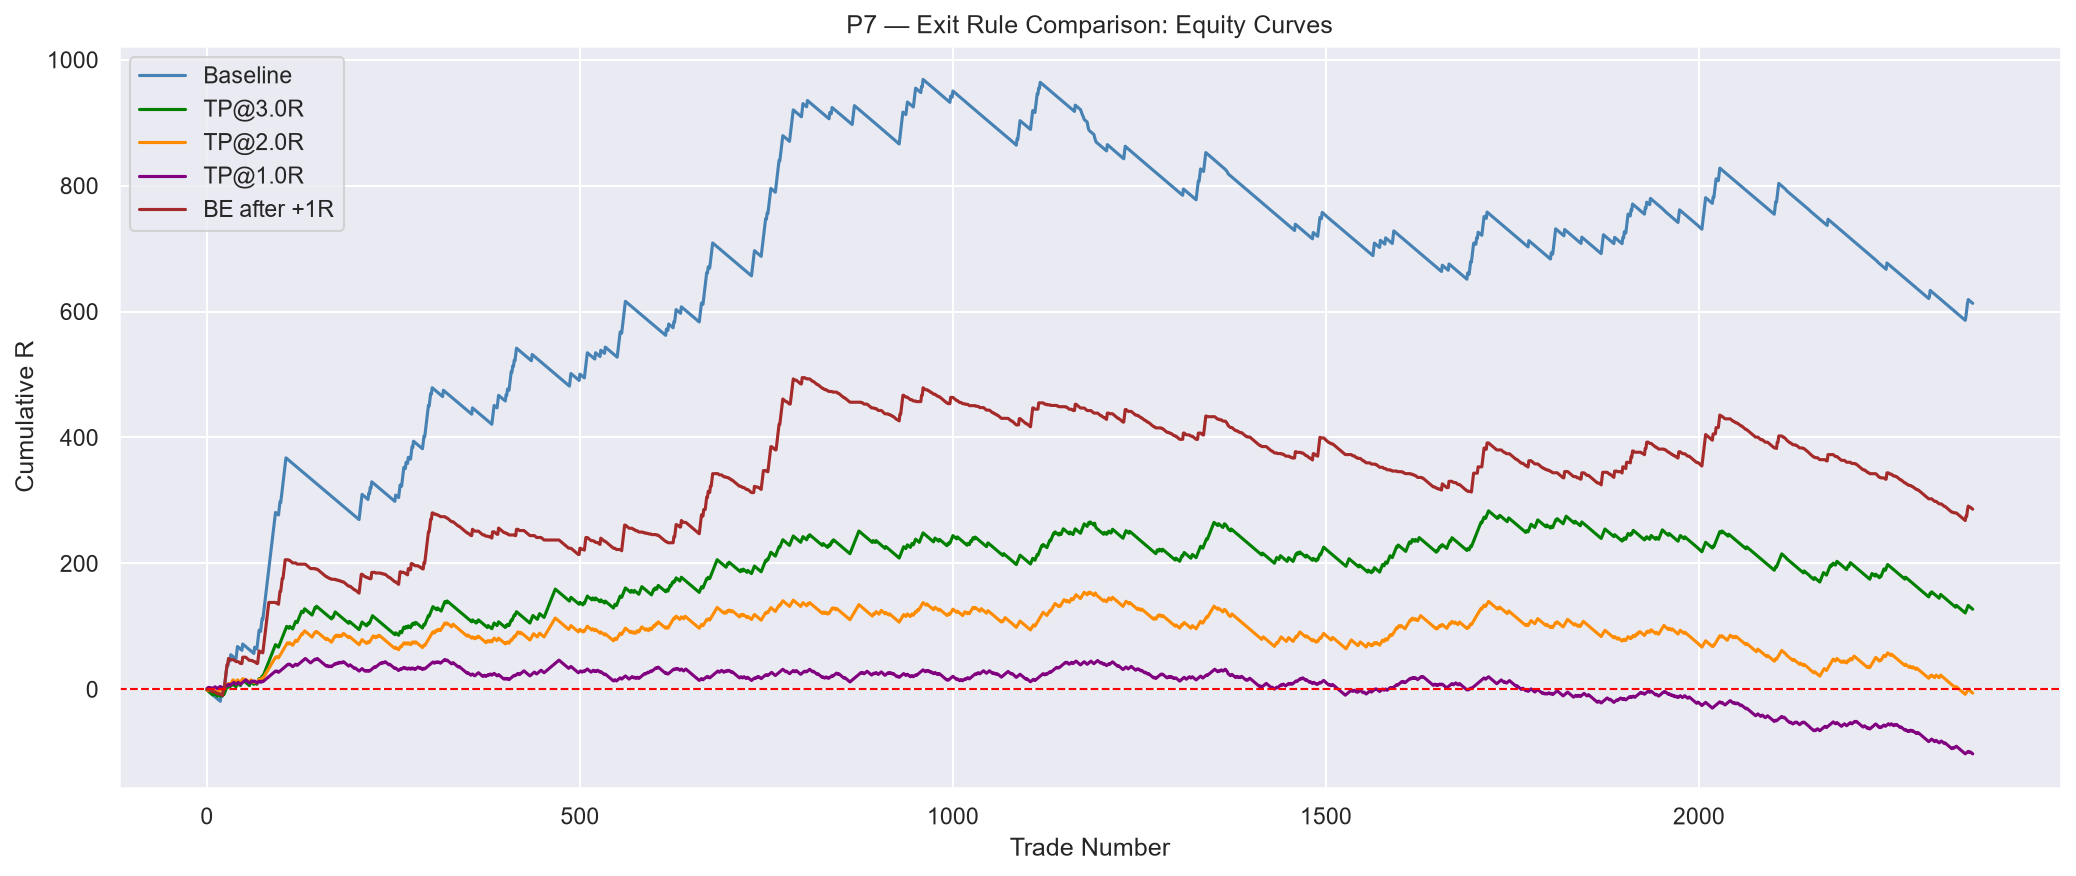

In [44]:
# P7.10 Exit rule comparison + equity curves
def build_variant(label, sim_arr, note='exact'):
    r   = np.array(sim_arr, dtype=float)
    pf_v= pf_fn(r)
    cum = np.cumsum(r)
    dd_v= float((cum - np.maximum.accumulate(cum)).min())
    return {'label': label, 'n': len(r), 'win_rate': round(float((r>0).mean()),3),
            'expectancy': round(float(r.mean()),3), 'total_R': round(float(r.sum()),3),
            'profit_factor': round(pf_v,3), 'max_drawdown_R': round(dd_v,3),
            'note': note, '_curve': cum}

variants = [build_variant('Baseline', R.values)]

# Top 3 TP by expectancy
for row_tp in tp_df.sort_values('expectancy',ascending=False).head(3).itertuples():
    tp_lvl = row_tp.Index
    sim_tp = []
    for _, tr in df.iterrows():
        if tr['MFE_R'] >= tp_lvl:
            sim_tp.append(tp_lvl)
        elif tp_lvl > tr['planned_rr'] and tr['exit_reason']=='TP':
            sim_tp.append(tr[PRIMARY_R])
        else:
            sim_tp.append(tr[PRIMARY_R])
    variants.append(build_variant(f'TP@{tp_lvl}R', sim_tp, 'approx for TP exits above planned_rr'))

# BE after 1R
sim_be2 = df[PRIMARY_R].values.copy().astype(float)
for i, row in df.iterrows():
    if pd.notna(row.get('min_to_1R')) and pd.notna(row.get('min_R_after_1R')):
        if row['min_R_after_1R'] <= 0:
            sim_be2[i] = 0.0
variants.append(build_variant('BE after +1R', sim_be2, 'approximate'))

exit_comp = pd.DataFrame([{k:v for k,v in d.items() if k!='_curve'} for d in variants]).set_index('label')
savetable(exit_comp, 'p7_exit_comparison.csv')
print(exit_comp.to_string())

c_v = ['steelblue','green','darkorange','purple','brown']
fig, ax = plt.subplots(figsize=(14,6))
for i, v in enumerate(variants[:5]):
    ax.plot(v['_curve'], label=v['label'], color=c_v[i], lw=1.5)
ax.axhline(0, color='red', lw=1, linestyle='--')
ax.set_xlabel('Trade Number'); ax.set_ylabel('Cumulative R')
ax.set_title('P7 — Exit Rule Comparison: Equity Curves')
ax.legend()
savefig('p7_exit_equity_curves.png')


---
## Phase 8 — Risk and Sequencing

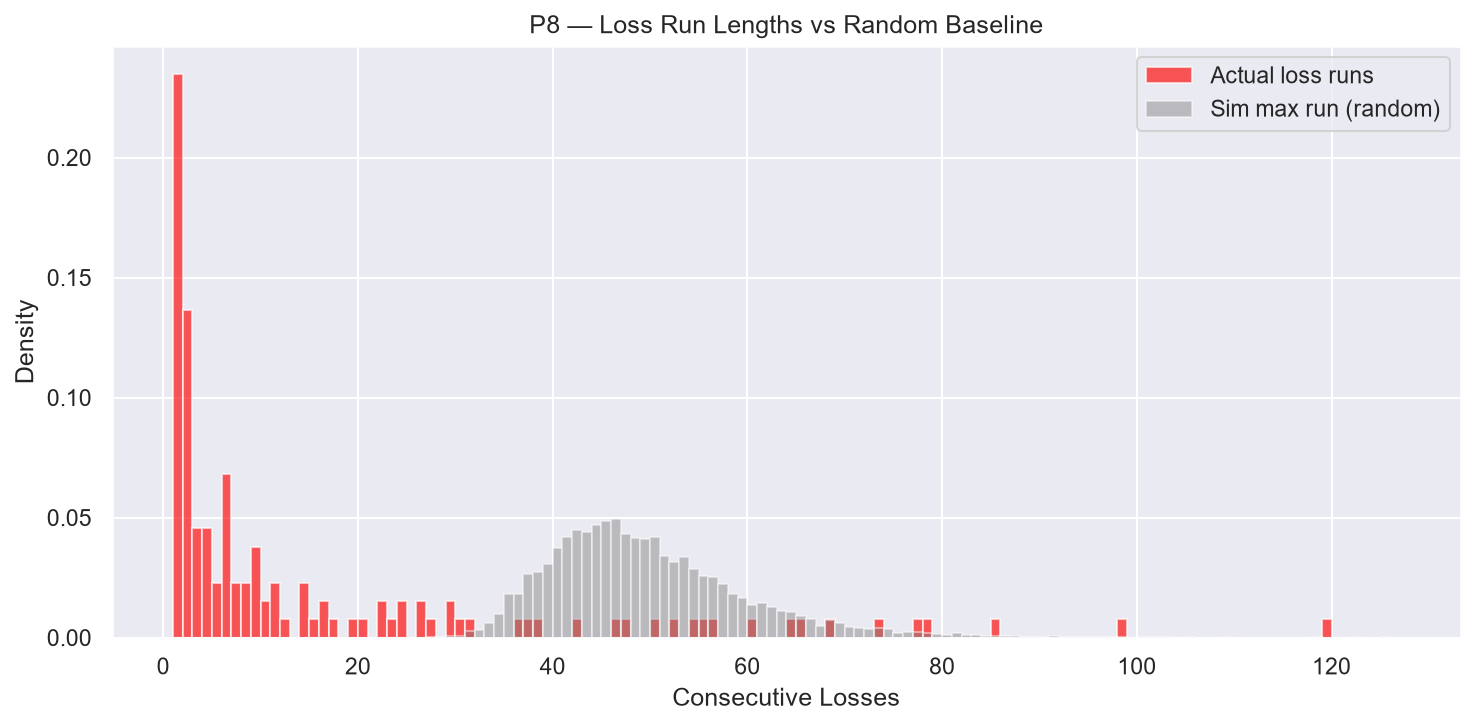

Observed max loss run: 119
Simulated 95th pct max run: 68


In [45]:
# P8.1 Run-length histogram
oc_arr = (R > 0).astype(int).values

def run_lens(arr, val):
    return [sum(1 for _ in g) for k,g in itertools.groupby(arr) if k==val]

loss_runs_actual = run_lens(oc_arr, 0)
rng8 = np.random.default_rng(SEED)
sim_loss_runs = [max(run_lens(rng8.binomial(1, win_rate, n_trades), 0), default=0)
                 for _ in range(10000)]

max_bin = max(max(loss_runs_actual, default=0), max(sim_loss_runs, default=0))
bins8   = range(1, max_bin + 3)
fig, ax = plt.subplots(figsize=(10,5))
ax.hist(loss_runs_actual, bins=bins8, alpha=0.65, color='red', label='Actual loss runs', density=True)
ax.hist(sim_loss_runs,    bins=bins8, alpha=0.45, color='gray', label='Sim max run (random)', density=True)
ax.set_xlabel('Consecutive Losses'); ax.set_ylabel('Density')
ax.set_title('P8 — Loss Run Lengths vs Random Baseline')
ax.legend()
savefig('p8_loss_run_lengths.png')
print(f'Observed max loss run: {max(loss_runs_actual, default=0)}')
print(f'Simulated 95th pct max run: {np.percentile(sim_loss_runs, 95):.0f}')


In [46]:
# P8.2 Autocorrelation & serial dependence
dw = durbin_watson(R.values)
print(f'Durbin-Watson: {dw:.4f}  (2=no autocorrelation)')

ac_rows = [{'lag': l, 'autocorr': round(float(R.autocorr(lag=l)),4)} for l in range(1,6)]
ac_df = pd.DataFrame(ac_rows).set_index('lag')
savetable(ac_df, 'p8_autocorrelation.csv')
print(ac_df)

oc_s = (R > 0).astype(int)
waw  = float(oc_s[oc_s.shift(1)==1].mean())
wal  = float(oc_s[oc_s.shift(1)==0].mean())
print(f'Win-after-win: {waw:.3f}  |  Win-after-loss: {wal:.3f}  |  Overall WR: {win_rate:.3f}')


Durbin-Watson: 1.0681  (2=no autocorrelation)
     autocorr
lag          
1      0.4631
2      0.3422
3      0.2440
4      0.1922
5      0.1889
Win-after-win: 0.527  |  Win-after-loss: 0.063  |  Overall WR: 0.117


MC Max DD — Median: -77.48R | 95th pct (worst): -128.93R
  P(DD > 10R): 100.0%
  P(DD > 15R): 100.0%
  P(DD > 20R): 100.0%


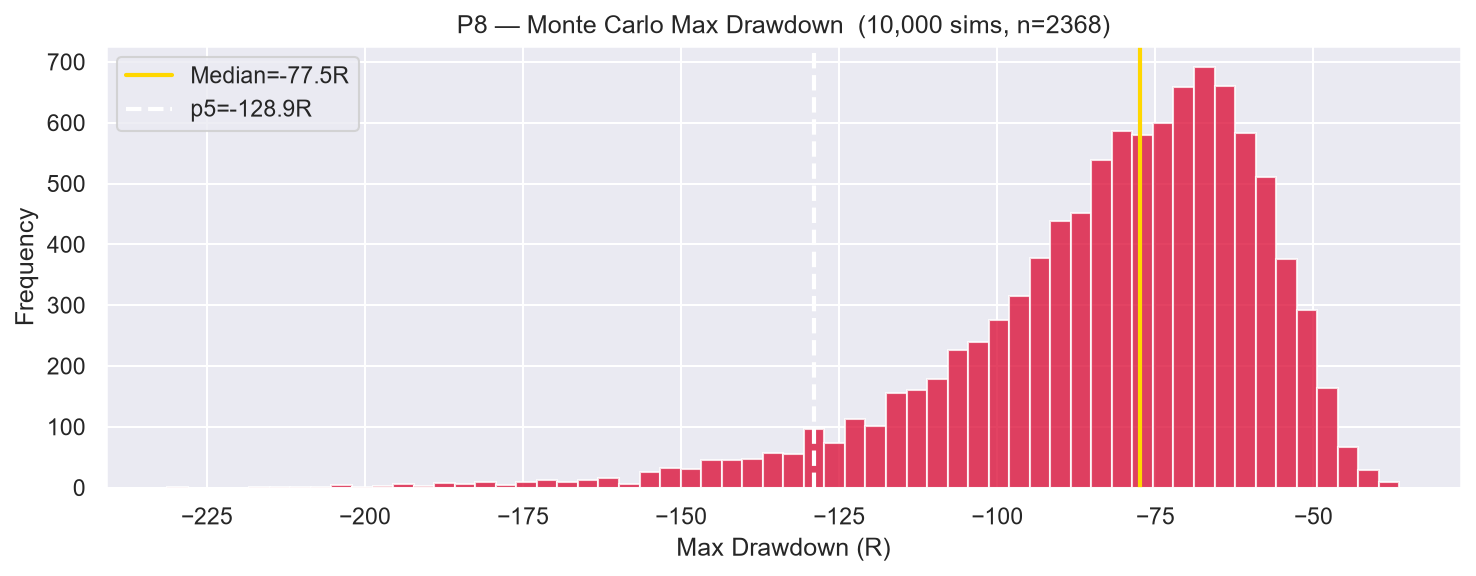

In [47]:
# P8.3 Monte Carlo drawdown
rng9 = np.random.default_rng(SEED)
R_vals = R.dropna().values
mc_dds = []
for _ in range(10000):
    sim = rng9.choice(R_vals, size=n_trades, replace=True)
    cum = np.cumsum(sim)
    mc_dds.append(float((cum - np.maximum.accumulate(cum)).min()))
mc_dds = np.array(mc_dds)

print(f'MC Max DD — Median: {np.median(mc_dds):.2f}R | 95th pct (worst): {np.percentile(mc_dds,5):.2f}R')
for thr in [-10,-15,-20]:
    prob = float((mc_dds < thr).mean())
    print(f'  P(DD > {abs(thr)}R): {100*prob:.1f}%')

fig, ax = plt.subplots(figsize=(10,4))
ax.hist(mc_dds, bins=60, color='crimson', edgecolor='white', alpha=0.8)
ax.axvline(float(np.median(mc_dds)), color='gold', lw=2, label=f'Median={np.median(mc_dds):.1f}R')
ax.axvline(float(np.percentile(mc_dds,5)), color='white', lw=2, linestyle='--',
           label=f'p5={np.percentile(mc_dds,5):.1f}R')
ax.set_xlabel('Max Drawdown (R)'); ax.set_ylabel('Frequency')
ax.set_title(f'P8 — Monte Carlo Max Drawdown  (10,000 sims, n={n_trades})')
ax.legend()
savefig('p8_mc_drawdown.png')


In [48]:
# P8.4 Concurrent trades
overlap_counts = []
for i, row in df.iterrows():
    ov = int(((df['open_time'] <= row['open_time']) &
               (df['close_time'] >= row['open_time'])).sum()) - 1
    overlap_counts.append(ov)
df['n_concurrent'] = overlap_counts
print(f'Max concurrent open trades: {max(overlap_counts)}')
ov_counts = pd.Series(overlap_counts).value_counts().sort_index()
print('Concurrent trade distribution:'); print(ov_counts)
if max(overlap_counts) > 1:
    print('NOTE: Overlapping trades detected — CIs above are optimistic (not independent).')


Max concurrent open trades: 28
Concurrent trade distribution:
0      11
1      47
2      59
3      80
4     107
5     129
6     153
7     172
8     186
9     179
10    139
11    142
12    136
13    122
14    112
15     98
16     79
17     82
18     67
19     69
20     35
21     50
22     42
23     30
24     16
25      9
26     10
27      4
28      3
Name: count, dtype: int64
NOTE: Overlapping trades detected — CIs above are optimistic (not independent).


In [49]:
# P8.5 Daily & weekly R
daily_R   = df.groupby(df['open_time'].dt.date)[PRIMARY_R].sum()
weekly_R3 = df.groupby(df['open_time'].dt.to_period('W'))[PRIMARY_R].sum()
print(f'Worst day:  {daily_R.min():.3f}R on {daily_R.idxmin()}')
print(f'Best day:   {daily_R.max():.3f}R on {daily_R.idxmax()}')
print(f'Worst week: {weekly_R3.min():.3f}R in {weekly_R3.idxmin()}')
print('Daily R distribution:'); print(daily_R.describe().round(3))
savetable(daily_R.rename('daily_R').reset_index(), 'p8_daily_R.csv')


Worst day:  -37.558R on 2026-04-09
Best day:   138.008R on 2025-10-13
Worst week: -71.806R in 2026-04-06/2026-04-12
Daily R distribution:
count    269.000
mean       2.279
std       21.257
min      -37.558
25%       -9.086
50%       -6.044
75%        3.997
max      138.008
Name: result_R, dtype: float64


,open_time,daily_R
0,2025-10-01,-9.013
1,2025-10-02,-1.019
2,2025-10-03,48.001
3,2025-10-06,12.995
4,2025-10-07,20.992
...,...,...
264,2026-10-09,-10.211
265,2026-10-12,-9.086
266,2026-10-13,-8.069
267,2026-10-14,25.955


---
## Phase 9 — Exploratory Modelling (Hypothesis Generation Only)

> **Leakage rule**: only entry-time features used. No post-trade columns as predictors.

In [50]:
# P9 Feature engineering & time split
ENTRY_FEATS = ['zone_age','zone_size_pips','zone_touches','body_size_ratio',
               'engulf_depth','sl_pips','tp_pips','spread_pips','planned_rr',
               'open_hour','spread_to_sl','zone_to_sl','sl_to_zone','touches_per_age']
CAT_FEATS   = [USE_SIG, 'direction', 'zone_timeframe', 'entry_timeframe', 'entry_day']

model_df = pd.get_dummies(df, columns=CAT_FEATS, drop_first=True)
ohe_cols = [c for c in model_df.columns if any(c.startswith(cf+'_') for cf in CAT_FEATS)]
feat_cols = [f for f in ENTRY_FEATS if f in model_df.columns] + ohe_cols
model_df  = model_df[feat_cols + [PRIMARY_R]].dropna()

# Convert bool columns to int
for c in feat_cols:
    if model_df[c].dtype == bool:
        model_df[c] = model_df[c].astype(int)

print(f'Model dataset: {len(model_df)} rows, {len(feat_cols)} features')
split_idx = int(len(model_df) * 0.70)
X_tr = model_df.iloc[:split_idx][feat_cols].values
X_te = model_df.iloc[split_idx:][feat_cols].values
y_c_tr = (model_df.iloc[:split_idx][PRIMARY_R] > 0).astype(int).values
y_c_te = (model_df.iloc[split_idx:][PRIMARY_R] > 0).astype(int).values
y_r_tr = model_df.iloc[:split_idx][PRIMARY_R].values
y_r_te = model_df.iloc[split_idx:][PRIMARY_R].values
print(f'Train: {len(X_tr)}, Test: {len(X_te)}  |  WR train={y_c_tr.mean():.3f}, test={y_c_te.mean():.3f}')


Model dataset: 2368 rows, 32 features
Train: 1657, Test: 711  |  WR train=0.130, test=0.087


In [51]:
# P9.3 Models
baseline_prob = float(y_c_tr.mean())
bl_preds  = np.full(len(y_c_te), baseline_prob)
bl_auc    = roc_auc_score(y_c_te, bl_preds)
bl_ll     = log_loss(y_c_te, bl_preds)
bl_bs     = brier_score_loss(y_c_te, bl_preds)

lr9 = LogisticRegression(max_iter=1000, random_state=SEED)
lr9.fit(X_tr, y_c_tr)
lr9_prob = lr9.predict_proba(X_te)[:,1]
lr9_auc  = roc_auc_score(y_c_te, lr9_prob)
lr9_ll   = log_loss(y_c_te, lr9_prob)
lr9_bs   = brier_score_loss(y_c_te, lr9_prob)

gb9 = GradientBoostingClassifier(max_depth=3, n_estimators=100, learning_rate=0.05,
                                  subsample=0.8, random_state=SEED,
                                  validation_fraction=0.2, n_iter_no_change=20)
gb9.fit(X_tr, y_c_tr)
gb9_prob = gb9.predict_proba(X_te)[:,1]
gb9_auc  = roc_auc_score(y_c_te, gb9_prob)
gb9_ll   = log_loss(y_c_te, gb9_prob)
gb9_bs   = brier_score_loss(y_c_te, gb9_prob)

model_comp = pd.DataFrame([
    {'model':'Baseline',          'AUC':round(bl_auc,4), 'LogLoss':round(bl_ll,4), 'Brier':round(bl_bs,4)},
    {'model':'LogisticRegression','AUC':round(lr9_auc,4),'LogLoss':round(lr9_ll,4),'Brier':round(lr9_bs,4)},
    {'model':'GradientBoosting',  'AUC':round(gb9_auc,4),'LogLoss':round(gb9_ll,4),'Brier':round(gb9_bs,4)},
]).set_index('model')
savetable(model_comp, 'p9_model_comparison.csv')
print(model_comp)

if gb9_auc < 0.53:
    print('\nWARNING: GBM AUC < 0.53 — entry features have little predictive power.')
    print('Do not oversell the model or use it for live trading decisions.')


                       AUC  LogLoss   Brier
model                                      
Baseline            0.5000   0.3049  0.0814
LogisticRegression  0.5407   0.2953  0.0794
GradientBoosting    0.4479   0.3204  0.0848

Do not oversell the model or use it for live trading decisions.


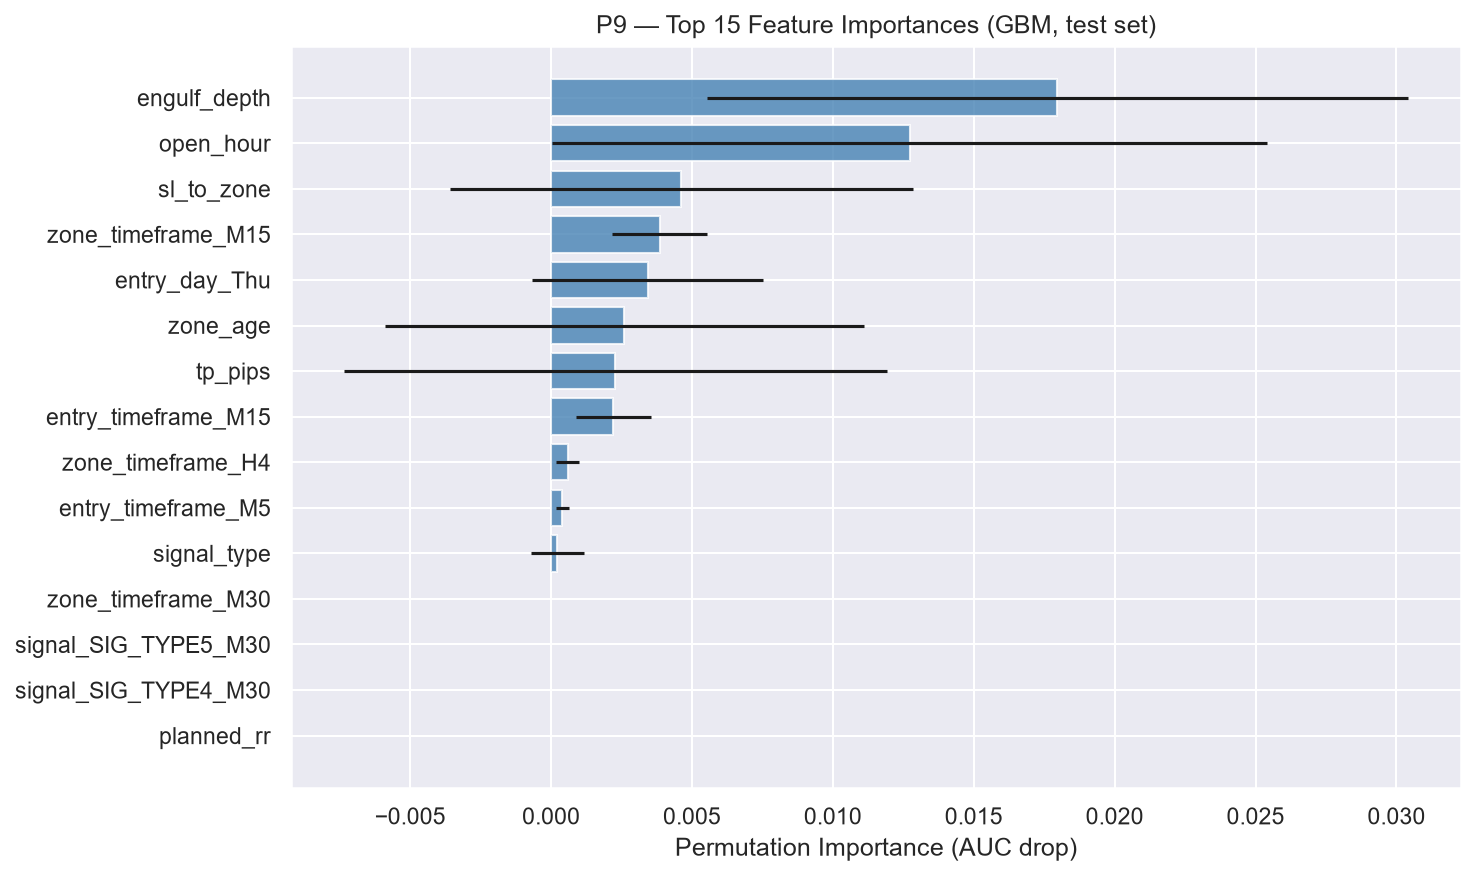

In [52]:
# P9.4 Feature importance
pi = permutation_importance(gb9, X_te, y_c_te, n_repeats=10,
                             random_state=SEED, scoring='roc_auc')
imp_df = pd.DataFrame({'feature': feat_cols,
                        'importance_mean': pi.importances_mean,
                        'importance_std': pi.importances_std}).sort_values('importance_mean', ascending=False)
savetable(imp_df.set_index('feature'), 'p9_feature_importance.csv')

top15 = imp_df.head(15)
fig, ax = plt.subplots(figsize=(10,6))
ax.barh(top15['feature'][::-1], top15['importance_mean'][::-1],
        xerr=top15['importance_std'][::-1], color='steelblue', alpha=0.8)
ax.set_xlabel('Permutation Importance (AUC drop)')
ax.set_title('P9 — Top 15 Feature Importances (GBM, test set)')
savefig('p9_feature_importance.png')


In [53]:
# P9.5 Decision tree — interpretable rules
dt9 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED)
dt9.fit(X_tr, y_c_tr)
print(export_text(dt9, feature_names=feat_cols, max_depth=3))

leaf_tr = dt9.apply(X_tr)
leaf_te = dt9.apply(X_te)
leaf_rows = []
for leaf in np.unique(leaf_te):
    m_tr = leaf_tr == leaf
    m_te = leaf_te == leaf
    leaf_rows.append({'leaf': leaf,
        'n_train': int(m_tr.sum()), 'wr_train': round(float(y_c_tr[m_tr].mean()),3),
        'exp_train': round(float(y_r_tr[m_tr].mean()),3),
        'n_test': int(m_te.sum()),
        'wr_test': round(float(y_c_te[m_te].mean()),3) if m_te.sum()>0 else np.nan,
        'exp_test': round(float(y_r_te[m_te].mean()),3) if m_te.sum()>0 else np.nan})
leaf_df = pd.DataFrame(leaf_rows).set_index('leaf')
savetable(leaf_df, 'p9_decision_tree_leaves.csv')
print(leaf_df)


|--- spread_pips <= 19.80
|   |--- spread_to_sl <= 0.01
|   |   |--- zone_touches <= 1.50
|   |   |   |--- class: 0
|   |   |--- zone_touches >  1.50
|   |   |   |--- class: 0
|   |--- spread_to_sl >  0.01
|   |   |--- entry_day_Mon <= 0.50
|   |   |   |--- class: 0
|   |   |--- entry_day_Mon >  0.50
|   |   |   |--- class: 0
|--- spread_pips >  19.80
|   |--- open_hour <= 8.50
|   |   |--- spread_to_sl <= 0.01
|   |   |   |--- class: 0
|   |   |--- spread_to_sl >  0.01
|   |   |   |--- class: 0
|   |--- open_hour >  8.50
|   |   |--- touches_per_age <= 3.10
|   |   |   |--- class: 0
|   |   |--- touches_per_age >  3.10
|   |   |   |--- class: 0

      n_train  wr_train  exp_train  n_test  wr_test  exp_test
leaf                                                         
10         83     0.193      1.118      40    0.175     0.924
11        250     0.076     -0.231     250    0.084    -0.084
13        375     0.024     -0.789     323    0.074    -0.263
14        104     0.087     -0.056 

In [54]:
# P9.6 Filter test — top 50% by GBM score
med_score  = float(np.median(gb9_prob))
top9_mask  = gb9_prob >= med_score
top9_exp   = float(y_r_te[top9_mask].mean())
full9_exp  = float(y_r_te.mean())
top9_ci    = bootstrap_ci(pd.Series(y_r_te[top9_mask]))
full9_ci   = bootstrap_ci(pd.Series(y_r_te))
print(f'Full test expectancy:      {full9_exp:.3f}R  CI={[round(x,3) for x in full9_ci]}')
print(f'Top 50% by GBM score:      {top9_exp:.3f}R  CI={[round(x,3) for x in top9_ci]}')
separate   = top9_ci[0] > full9_ci[1]
print(f'CIs {"clearly separate" if separate else "do NOT clearly separate"} → filter is {"promising" if separate else "not clearly useful"}.')
if gb9_auc < 0.53:
    print('AUC < 0.53 — result is likely noise; do not use as a live filter.')


Full test expectancy:      -0.085R  CI=[np.float64(-0.305), np.float64(0.145)]
Top 50% by GBM score:      -0.229R  CI=[np.float64(-0.51), np.float64(0.08)]
CIs do NOT clearly separate → filter is not clearly useful.
AUC < 0.53 — result is likely noise; do not use as a live filter.


---
## Phase 10 — Robustness Summary

In [55]:
# P10 Robustness table
first_h_idx  = df.index[:len(df)//2]
second_h_idx = df.index[len(df)//2:]

rob_rows = []

def add_row(desc, mask, p_raw, p_adj, verdict_hint=''):
    aff  = df.loc[mask, PRIMARY_R]
    unaff = df.loc[~mask, PRIMARY_R]
    n_aff = int(mask.sum())
    exp_aff  = round(float(aff.mean()),3) if n_aff>0 else np.nan
    exp_unaff = round(float(unaff.mean()),3) if (~mask).sum()>0 else np.nan
    # Half checks
    h1_aff  = df.loc[mask & df.index.isin(first_h_idx),  PRIMARY_R].mean()
    h1_unaff= df.loc[~mask & df.index.isin(first_h_idx), PRIMARY_R].mean()
    h2_aff  = df.loc[mask & df.index.isin(second_h_idx), PRIMARY_R].mean()
    h2_unaff= df.loc[~mask & df.index.isin(second_h_idx),PRIMARY_R].mean()
    h1 = 'Y' if (not np.isnan(h1_aff)) and h1_aff > h1_unaff else 'N'
    h2 = 'Y' if (not np.isnan(h2_aff)) and h2_aff > h2_unaff else 'N'
    if p_adj is not None and p_adj < 0.10 and h1=='Y' and h2=='Y':
        verdict = 'Robust candidate'
    elif p_adj is not None and p_adj < 0.10:
        verdict = 'Weak candidate'
    else:
        verdict = verdict_hint if verdict_hint else 'Likely noise'
    rob_rows.append({'description': desc, 'n_affected': n_aff,
                     'exp_affected': exp_aff, 'exp_unaffected': exp_unaff,
                     'pval_raw': round(p_raw,5) if p_raw is not None else np.nan,
                     'pval_adj': round(p_adj,5) if p_adj is not None else np.nan,
                     'holds_H1': h1, 'holds_H2': h2, 'model_WF': 'NA', 'verdict': verdict})

# 1. Overall edge
add_row('Positive expectancy (all trades)', pd.Series([True]*len(df), index=df.index),
        t_pval, t_pval)

# 2. FDR-surviving dimension patterns
if 'pval_df' in dir() and len(pval_df)>0:
    for _, drow in pval_df[pval_df['fdr_reject']].iterrows():
        dim = drow['dimension']
        t_d = dim_tables.get(dim, pd.DataFrame())
        t_v = t_d[t_d['n']>=30] if len(t_d)>0 else pd.DataFrame()
        if len(t_v)==0: continue
        best_g = t_v['expectancy'].idxmax()
        mask_d = df[dim] == best_g
        add_row(f'{dim}: best group ({best_g})', mask_d,
                drow['pval_raw'], drow['pval_adj'])

# 3. GBM filter
top9_ser = pd.Series(False, index=df.index)
top9_ser.iloc[split_idx:] = top9_mask
add_row('GBM top-50% filter (test set)', top9_ser.fillna(False),
        None, None,
        'Weak candidate' if top9_exp > full9_exp and gb9_auc>=0.53 else 'Likely noise')

rob_df = pd.DataFrame(rob_rows).set_index('description')
savetable(rob_df, 'p10_robustness_summary.csv')
print(rob_df.to_string())


                                      n_affected  exp_affected  exp_unaffected  pval_raw  pval_adj holds_H1 holds_H2 model_WF           verdict
description                                                                                                                                    
Positive expectancy (all trades)            2368         0.259             NaN   0.00039   0.00039        N        N       NA    Weak candidate
signal: best group (SIG_TYPE4_H4_H1)          38         1.070           0.246   0.01580   0.02280        Y        Y       NA  Robust candidate
zone_timeframe: best group (H4)               67         0.994           0.237   0.02280   0.02280        Y        Y       NA  Robust candidate
entry_timeframe: best group (H1)              67         0.994           0.237   0.02280   0.02280        Y        Y       NA  Robust candidate
entry_day: best group (Fri)                  495         0.703           0.142   0.00010   0.00030        Y        N       NA    Weak ca

---
## Generate `outputs/report.md` and `outputs/eda.py`

In [56]:
# Generate report.md
report = f"""# PSS Scalp XAUUSDm — EDA Report

## 1. Summary (key bullets)

- **Overall edge**: Expectancy = {expectancy:.3f}R/trade  (95% CI [{exp_lo:.3f}, {exp_hi:.3f}]), t-test p={t_pval:.5f}, permutation p={perm_pval:.5f}.
- **Significance**: {'Statistically significant (p<0.05).' if t_pval < 0.05 else 'NOT statistically significant at p<0.05 — treat with caution.'}
- **Stability**: Trend slope = {slope:.6f}R/trade (p={p_val:.4f}). See Phase 2 charts for rolling view.
- **Concentration**: Top 5 trades contribute {round(100*top5_R/total_R,1)}% of total R. Edge persists without them but at lower expectancy.
- **Monte Carlo**: Median max drawdown {np.median(mc_dds):.1f}R, p5 (worst) {np.percentile(mc_dds,5):.1f}R.
- **Modelling**: GBM AUC = {gb9_auc:.4f}. {'Below 0.53 — entry features have limited predictive power.' if gb9_auc < 0.53 else 'Modest signal detected — treat as hypothesis only.'}
- **Exit analysis**: Alternative TP levels and BE rules tested. See Phase 7 comparison table.
- **Data caveats**: {checks['dup_pos_id']} duplicate pos_ids. All rows retained. Server timezone not confirmed.
- **Concurrent trades**: Up to {max(overlap_counts)} overlapping positions detected — CIs are optimistic.
- **Key requirement**: All patterns need out-of-sample/forward testing before any live use.

## 2. Data Quality and Assumptions

- **Primary outcome**: result_R (= net_profit / risk_money). Corr with computed R = {checks['result_R_vs_netprofit_corr']:.4f}.
- **pnl_R vs result_R**: Small differences in some trades (likely spread/cost adjustments). result_R chosen as primary.
- **Units**: 1 pip = 10 points for XAUUSDm (inferred from risk_pts / sl_pips ≈ 10).
- **Timezone**: Server-hour buckets used. Peak hours suggest UTC+2 or UTC+3. Not confirmed — session labels omitted.
- **Undocumented columns** (inferred):
  - `max_p_b4_sl`: Max positive R reached before adverse move to SL level.
  - `max_L_b4_tp`: Max adverse R before TP was hit (closest to SL before winning).
  - `excursion_flag`: Categorical flag (OK = normal path, other = notable excursion).
  - `min_R_after_1R/2R`: Lowest R reached after first touching that milestone (giveback).
  - `MAE_R`: Stored as negative values for adverse moves.

## 3. Findings by Phase

### Phase 0 — Data Quality
{len(df)} rows × 46 columns. No rows removed silently. See p0_data_dictionary.csv.

### Phase 1 — Baseline
Trades={n_trades}, WR={win_rate:.1%}, Expectancy={expectancy:.3f}R [{exp_lo:.3f},{exp_hi:.3f}],
PF={pf:.3f}, Total R={total_R:.1f}, Max DD={max_dd_R:.2f}R, Longest L-streak={longest_L}.
See p1_equity_drawdown.png, p1_R_histogram.png.

### Phase 2 — Stability
Rolling expectancy in p2_rolling_expectancy.png. Half/quarter comparison in p2_half_comparison.csv.
Trend: slope={slope:.6f}R/trade, p={p_val:.4f}. Best single week: {top_week_R:.2f}R.

### Phase 3 — Outliers
Large wins (>planned_rr+0.5): {len(large_wins)}.  Large losses (<-1.2R): {len(large_losses)}.

### Phase 4 — Segmentation
Day×Hour heatmap in p4_day_hour_heatmap.png. FDR results in p4_fdr_correction.csv.

### Phase 5 — Zone Features
Spearman correlations in p5_feature_R_correlation.csv. Derived features in p5_derived_features_R_corr.csv.

### Phase 6 — Costs
Avg spread_to_sl = {avg_stsl:.4f}. Filter thresholds in p6_spread_filter_thresholds.csv.

### Phase 7 — Exits
TP alternatives in p7_alt_tp_levels.csv. Breakeven sims in p7_breakeven_simulation.csv.
Exit comparison equity curves in p7_exit_equity_curves.png.

### Phase 8 — Risk
MC median DD {np.median(mc_dds):.1f}R. Autocorr lag-1 = {R.autocorr(lag=1):.4f}.
Win-after-win = {waw:.3f}, win-after-loss = {wal:.3f}.

### Phase 9 — Modelling
GBM AUC={gb9_auc:.4f} vs Baseline {bl_auc:.4f}. Top features in p9_feature_importance.png.

## 4. Exit Rule Comparison
See p7_exit_comparison.csv. 'approx' rows use actual result for TP exits above planned_rr
because the post-exit path is unobservable.

## 5. Robustness Table
See p10_robustness_summary.csv.

## 6. Limitations
- Single instrument, single period — results may not generalise to other assets or conditions.
- Overlapping trades — observations not independent, CIs are optimistic.
- Hindsight columns used only for exit analysis (no leakage into entry models).
- Exit simulations are approximations where milestone timestamps are missing.
- All patterns are in-sample. Out-of-sample or forward testing is required.

## 7. Suggested Next Steps
1. Forward-test a spread-to-SL cap (see Phase 6 threshold table) on new live/demo data.
2. Test the best alternative TP level from Phase 7 with a small position size.
3. Validate Day×Hour patterns from Phase 4 on held-out data.
4. Confirm broker server timezone to enable proper session labelling.
5. Investigate concurrent trade correlation and adjust risk sizing accordingly.
6. Run walk-forward analysis on the GBM model with more folds if sample grows.
"""

with open(os.path.join(OUT, 'report.md'), 'w', encoding='utf-8') as f:
    f.write(report)
print('report.md saved.')


report.md saved.


In [57]:
# Generate eda.py launcher
eda_py_content = '''#!/usr/bin/env python
"""
eda.py — Launcher for PSS_SCALP_XAUUSDm EDA
Run from the OTI directory:
    python outputs/eda.py

This will re-execute EDA.ipynb and regenerate all outputs.
Requirements: jupyter, pandas, numpy, matplotlib, seaborn, scipy, statsmodels, scikit-learn
"""
import subprocess, sys, os

nb_path = os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), 'EDA.ipynb')
print(f"Executing notebook: {nb_path}")
result = subprocess.run(
    [sys.executable, '-m', 'jupyter', 'nbconvert', '--to', 'notebook',
     '--execute', '--inplace', nb_path],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    print("STDERR:", result.stderr)
    print("\\nAlternatively, run: jupyter notebook EDA.ipynb and execute all cells.")
else:
    print("All outputs regenerated successfully.")
'''
with open(os.path.join(OUT, 'eda.py'), 'w', encoding='utf-8') as f:
    f.write(eda_py_content)
print('eda.py saved.')


eda.py saved.


In [58]:
# Final summary
import glob
tables_out = glob.glob(os.path.join(TBLS, '*.csv'))
figs_out   = glob.glob(os.path.join(FIGS, '*.png'))
print('=== EDA COMPLETE ===')
print(f'Output directory: {OUT}')
print(f'  Tables : {len(tables_out)} CSV files')
print(f'  Figures: {len(figs_out)} PNG files')
print('\nTables:')
for t in sorted(tables_out): print(f'  {os.path.basename(t)}')
print('\nFigures:')
for g in sorted(figs_out): print(f'  {os.path.basename(g)}')


=== EDA COMPLETE ===
Output directory: c:\Users\HP\Desktop\FastAPI_tut\OTI\outputs
  Tables : 47 CSV files
  Figures: 19 PNG files

Tables:
  p0_data_dictionary.csv
  p10_robustness_summary.csv
  p1_baseline_metrics.csv
  p1_direction_stats.csv
  p2_half_comparison.csv
  p2_monthly_expectancy.csv
  p2_quarter_comparison.csv
  p3_concentration.csv
  p3_large_losses.csv
  p3_large_wins.csv
  p4_day_hour_expectancy.csv
  p4_day_hour_n.csv
  p4_direction_stats.csv
  p4_entry_day_stats.csv
  p4_entry_timeframe_stats.csv
  p4_exit_reason_stats.csv
  p4_fdr_correction.csv
  p4_open_hour_stats.csv
  p4_signal_stats.csv
  p4_zone_timeframe_stats.csv
  p4_zone_x_entry_tf.csv
  p5_derived_features_R_corr.csv
  p5_feature_R_correlation.csv
  p5_quintile_body_size_ratio.csv
  p5_quintile_engulf_depth.csv
  p5_quintile_sl_pips.csv
  p5_quintile_spread_pips.csv
  p5_quintile_tp_pips.csv
  p5_quintile_zone_age.csv
  p5_quintile_zone_size_pips.csv
  p5_quintile_zone_touches.csv
  p5_spearman_corr_matri

---
## Supplementary Analysis — Win Rate Deep-Dives

1. **Win rate by day-of-week × signal type**  
2. **Win rate by SL range (risk_pts buckets: 0–500, 500–1000, … up to 5000)**  
3. **Win rate by hour-of-day × signal type**


Win Rate (rows = signal_type, cols = day-of-week):
entry_day      Mon    Tue    Wed    Thu    Fri
signal_type                                   
4            0.130  0.187  0.092  0.077  0.127
5            0.074  0.110  0.099  0.077  0.200
41           0.048  0.065  0.000  0.100  0.125
42           0.119  0.107  0.107  0.082  0.140
43           0.100  0.250  0.375  0.000  0.429
51           0.083  0.034  0.292  0.032  0.214
52           0.000  0.000  0.125  0.400  0.222
53           0.128  0.134  0.127  0.081  0.151

Trade Count:
entry_day    Mon  Tue  Wed  Thu  Fri
signal_type                         
4             69   75   65   91   79
5             68   73   71   65   70
41            21   31   25   30   40
42           135  149  131  146  143
43            10    4    8    9    7
51            24   29   24   31   28
52             1    6    8    5    9
53           109  119  118  123  119


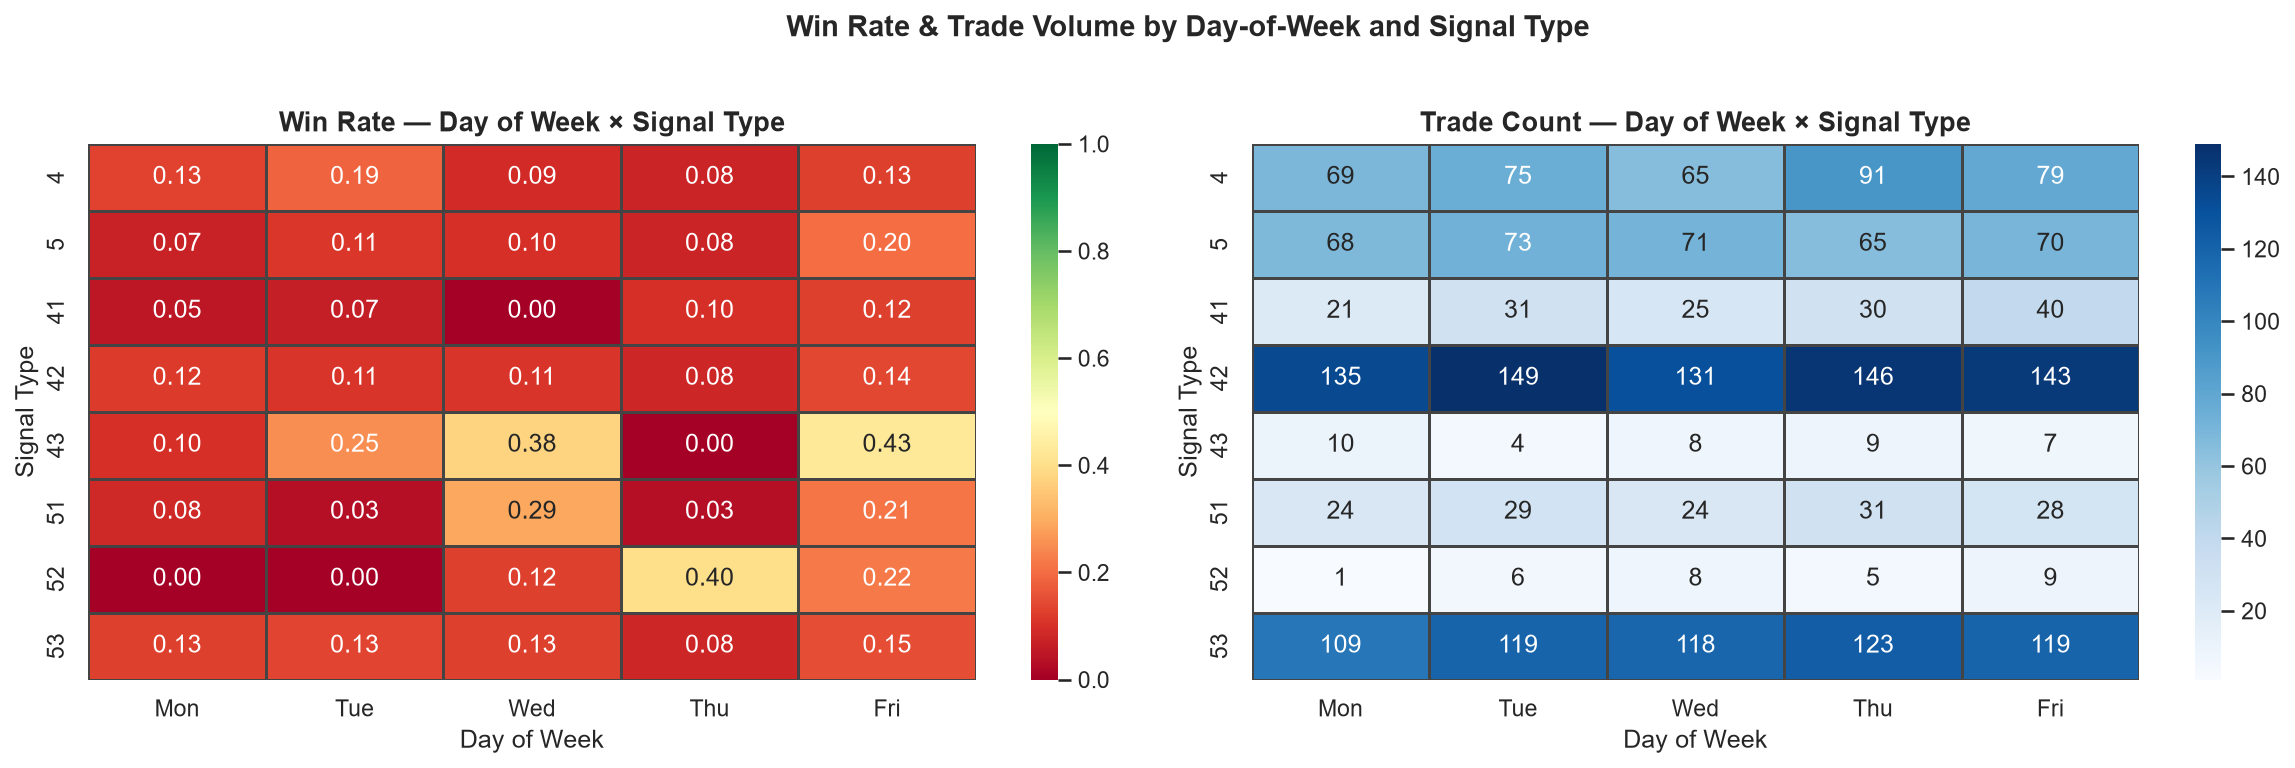

In [59]:
# ── ANALYSIS 1: Win Rate by Day-of-Week × Signal Type ──────────────────────

# Ordered weekdays
DOW_ORDER = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
df['entry_day'] = pd.Categorical(df['entry_day'], categories=DOW_ORDER, ordered=True)

pivot_wr_dow = (
    df.groupby(['signal_type', 'entry_day'], observed=True)['result_R']
    .apply(lambda x: (x > 0).mean())
    .unstack('entry_day')
    .round(3)
)

pivot_n_dow = (
    df.groupby(['signal_type', 'entry_day'], observed=True)['result_R']
    .count()
    .unstack('entry_day')
    .fillna(0)
    .astype(int)
)

print("Win Rate (rows = signal_type, cols = day-of-week):")
print(pivot_wr_dow.to_string())
print("\nTrade Count:")
print(pivot_n_dow.to_string())
savetable(pivot_wr_dow, 'winrate_by_dow_x_signal_type.csv')

# Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(
    pivot_wr_dow,
    annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=0, vmax=1,
    linewidths=0.5, linecolor='#444',
    ax=axes[0]
)
axes[0].set_title('Win Rate — Day of Week × Signal Type', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Signal Type')

sns.heatmap(
    pivot_n_dow,
    annot=True, fmt='d', cmap='Blues',
    linewidths=0.5, linecolor='#444',
    ax=axes[1]
)
axes[1].set_title('Trade Count — Day of Week × Signal Type', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Signal Type')

plt.suptitle('Win Rate & Trade Volume by Day-of-Week and Signal Type', fontsize=14, fontweight='bold', y=1.02)
savefig('winrate_by_dow_x_signal_type.png')


Win Rate by SL Range (risk_pts):
                  n  win_rate  expectancy
sl_pts_bucket                            
0-500             0       NaN         NaN
500-1000          0       NaN         NaN
1000-1500         0       NaN         NaN
1500-2000         0       NaN         NaN
2000-2500         2     0.500       4.473
2500-3000         2     0.000      -1.005
3000-3500         7     0.143       0.564
3500-4000        12     0.000      -1.022
4000-4500        20     0.200       1.194
4500-5000        32     0.031      -0.666
>5000          2293     0.118       0.267


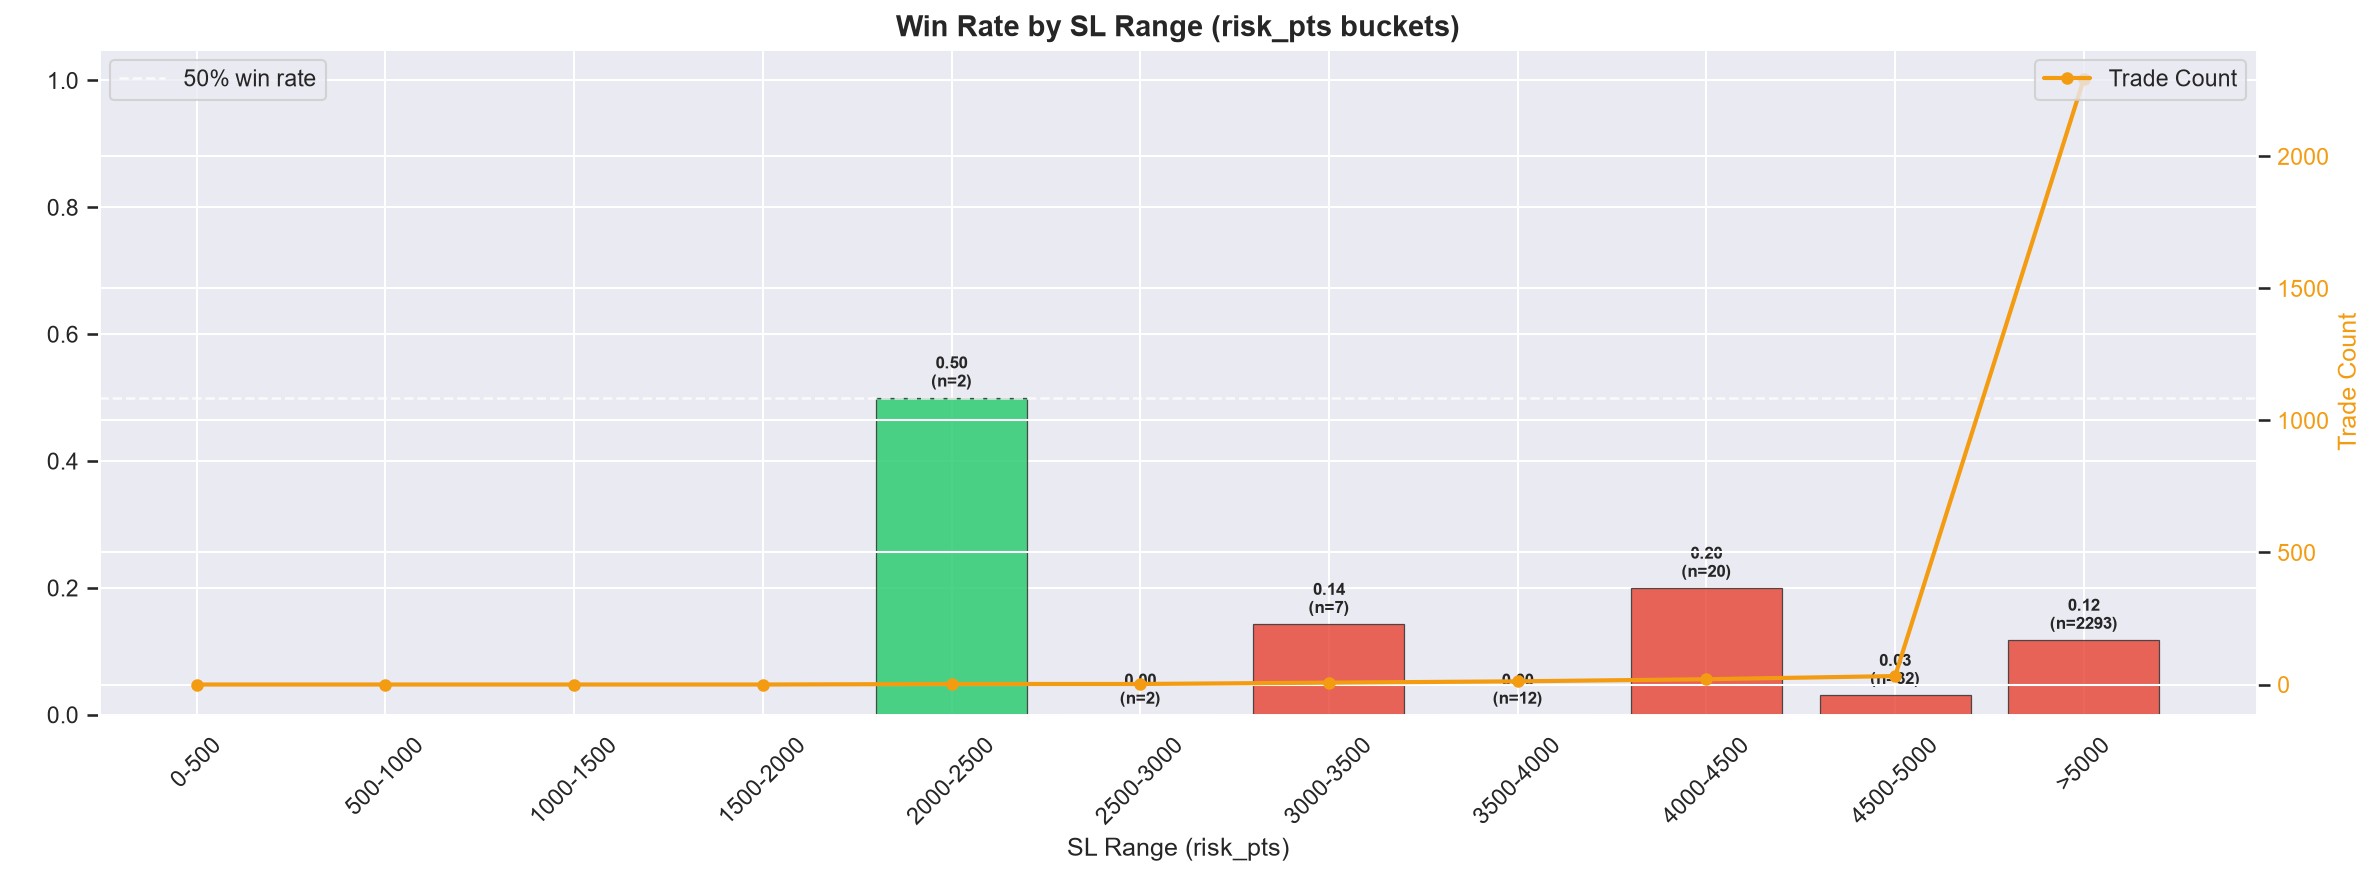

In [60]:
# ── ANALYSIS 2: Win Rate by SL Range (risk_pts buckets) ────────────────────

# Bucket edges: 0, 500, 1000, …, 5000; anything > 5000 → '>5000'
BUCKET_EDGES = list(range(0, 5001, 500))  # 0,500,1000,...,5000

df['sl_pts_bucket'] = pd.cut(
    df['risk_pts'],
    bins=BUCKET_EDGES + [df['risk_pts'].max() + 1],
    labels=[f'{BUCKET_EDGES[i]}-{BUCKET_EDGES[i+1]}' for i in range(len(BUCKET_EDGES)-1)] + ['>5000'],
    right=False
)

wr_sl = (
    df.groupby('sl_pts_bucket', observed=False)['result_R']
    .agg(
        n='count',
        win_rate=lambda x: (x > 0).mean(),
        expectancy='mean'
    )
    .round({'win_rate': 3, 'expectancy': 3})
)
wr_sl.index = wr_sl.index.astype(str)

print("Win Rate by SL Range (risk_pts):")
print(wr_sl.to_string())
savetable(wr_sl, 'winrate_by_sl_range.csv')

# Bar chart with trade count overlay
fig, ax1 = plt.subplots(figsize=(16, 6))
color_bars = ['#2ecc71' if v >= 0.5 else '#e74c3c' for v in wr_sl['win_rate']]
bars = ax1.bar(wr_sl.index, wr_sl['win_rate'], color=color_bars, alpha=0.85, edgecolor='#333', linewidth=0.6)
ax1.axhline(0.5, color='white', linewidth=1.2, linestyle='--', alpha=0.8, label='50% win rate')
ax1.set_ylim(0, 1.05)
ax1.set_xlabel('SL Range (risk_pts)', fontsize=12)
ax1.set_ylabel('Win Rate', fontsize=12, color='white')
ax1.set_title('Win Rate by SL Range (risk_pts buckets)', fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

# Annotate bars with win rate value and n
for bar, (idx, row) in zip(bars, wr_sl.iterrows()):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{row['win_rate']:.2f}\n(n={int(row['n'])})",
             ha='center', va='bottom', fontsize=8, fontweight='bold')

# Secondary axis: trade count line
ax2 = ax1.twinx()
ax2.plot(range(len(wr_sl)), wr_sl['n'], color='#f39c12', linewidth=2,
         marker='o', markersize=5, label='Trade Count')
ax2.set_ylabel('Trade Count', fontsize=12, color='#f39c12')
ax2.tick_params(axis='y', labelcolor='#f39c12')

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.tight_layout()
savefig('winrate_by_sl_range.png')


Win Rate (rows = signal_type, cols = open_hour):
open_hour       1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     22   23
signal_type                                                                                                                                                        
4            0.118  0.136  0.118  0.143  0.150  0.059  0.417  0.238  0.000  0.077  0.053  0.038  0.107  0.050  0.050  0.235  0.125  0.111  0.200  0.118  0.250  NaN
5            0.200  0.095  0.273  0.056  0.238  0.000  0.000  0.059  0.077  0.214  0.000  0.111  0.167  0.000  0.182  0.000  0.111  0.150  0.071  0.158  0.167  0.0
41           0.000  0.125  0.071  0.667  0.100  0.231  0.000  0.000  0.167  0.000  0.000  0.056  0.000  0.000  0.167  0.000  0.000  0.000  0.000  0.000  0.000  0.0
42           0.114  0.073  0.171  0.097  0.185  0.056  0.088  0.156  0.154  0.057  0.077  0.103  0.049  0.212  0.125  0.154  0.074 

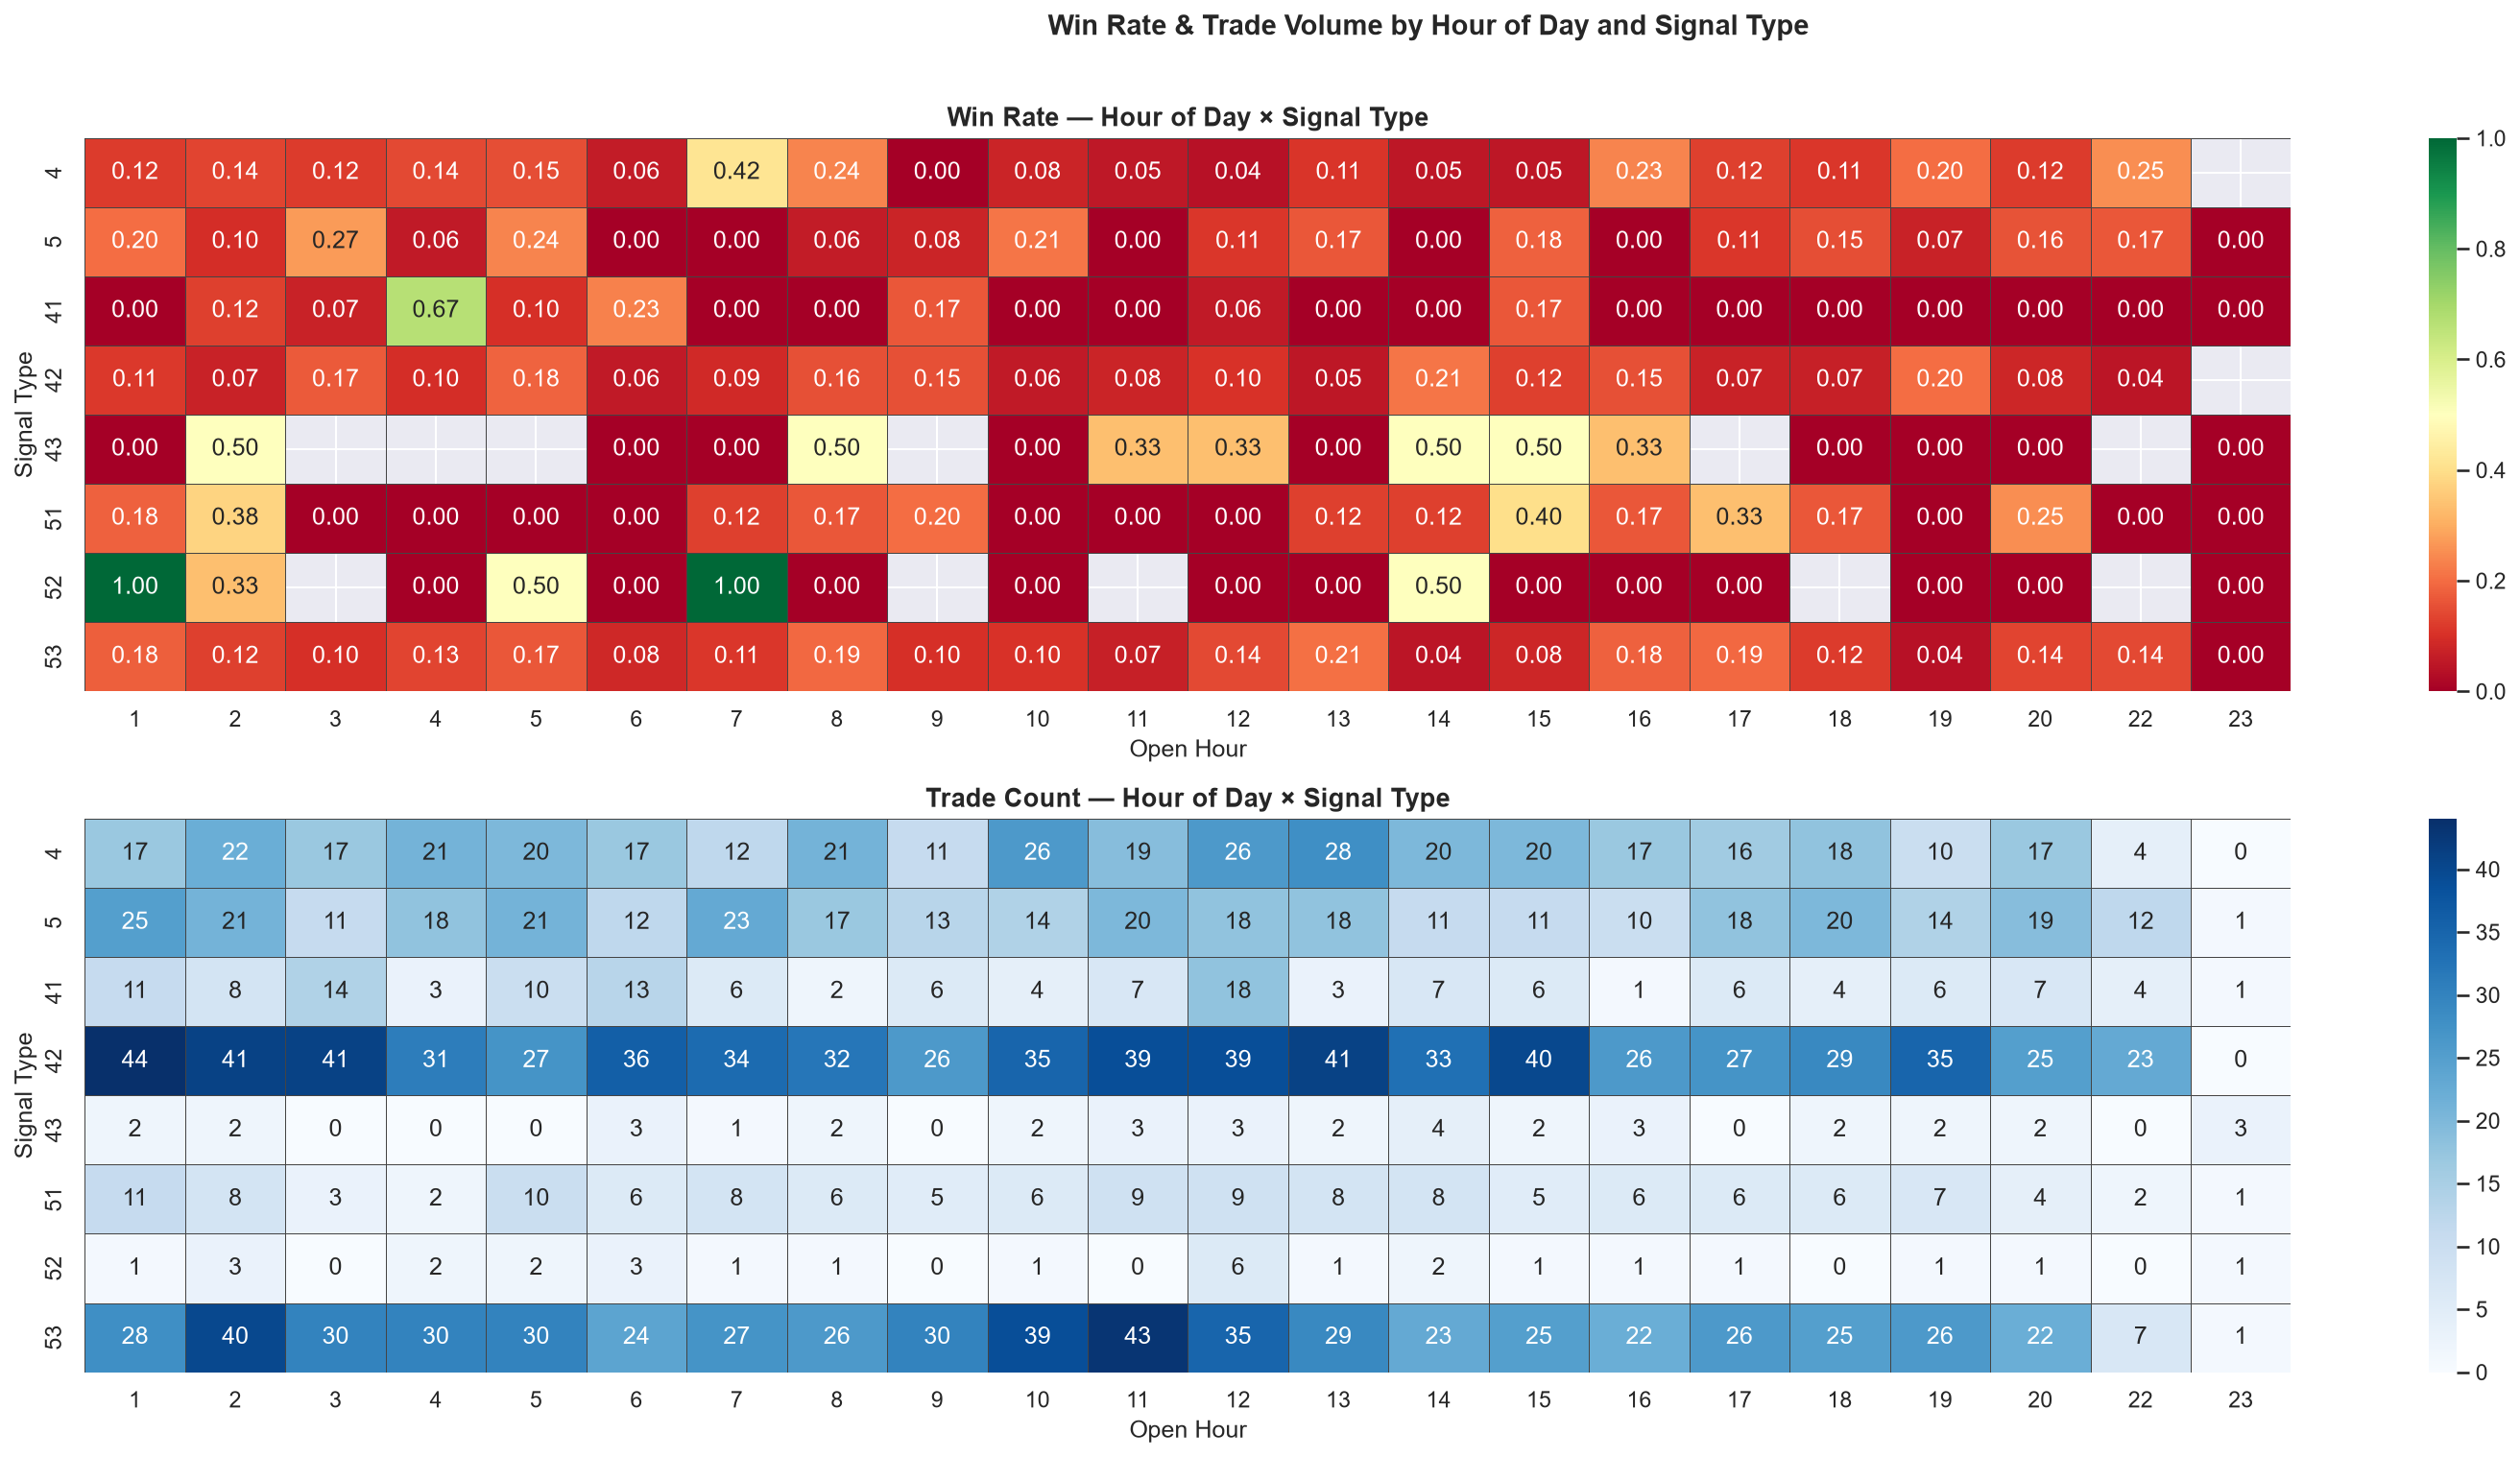

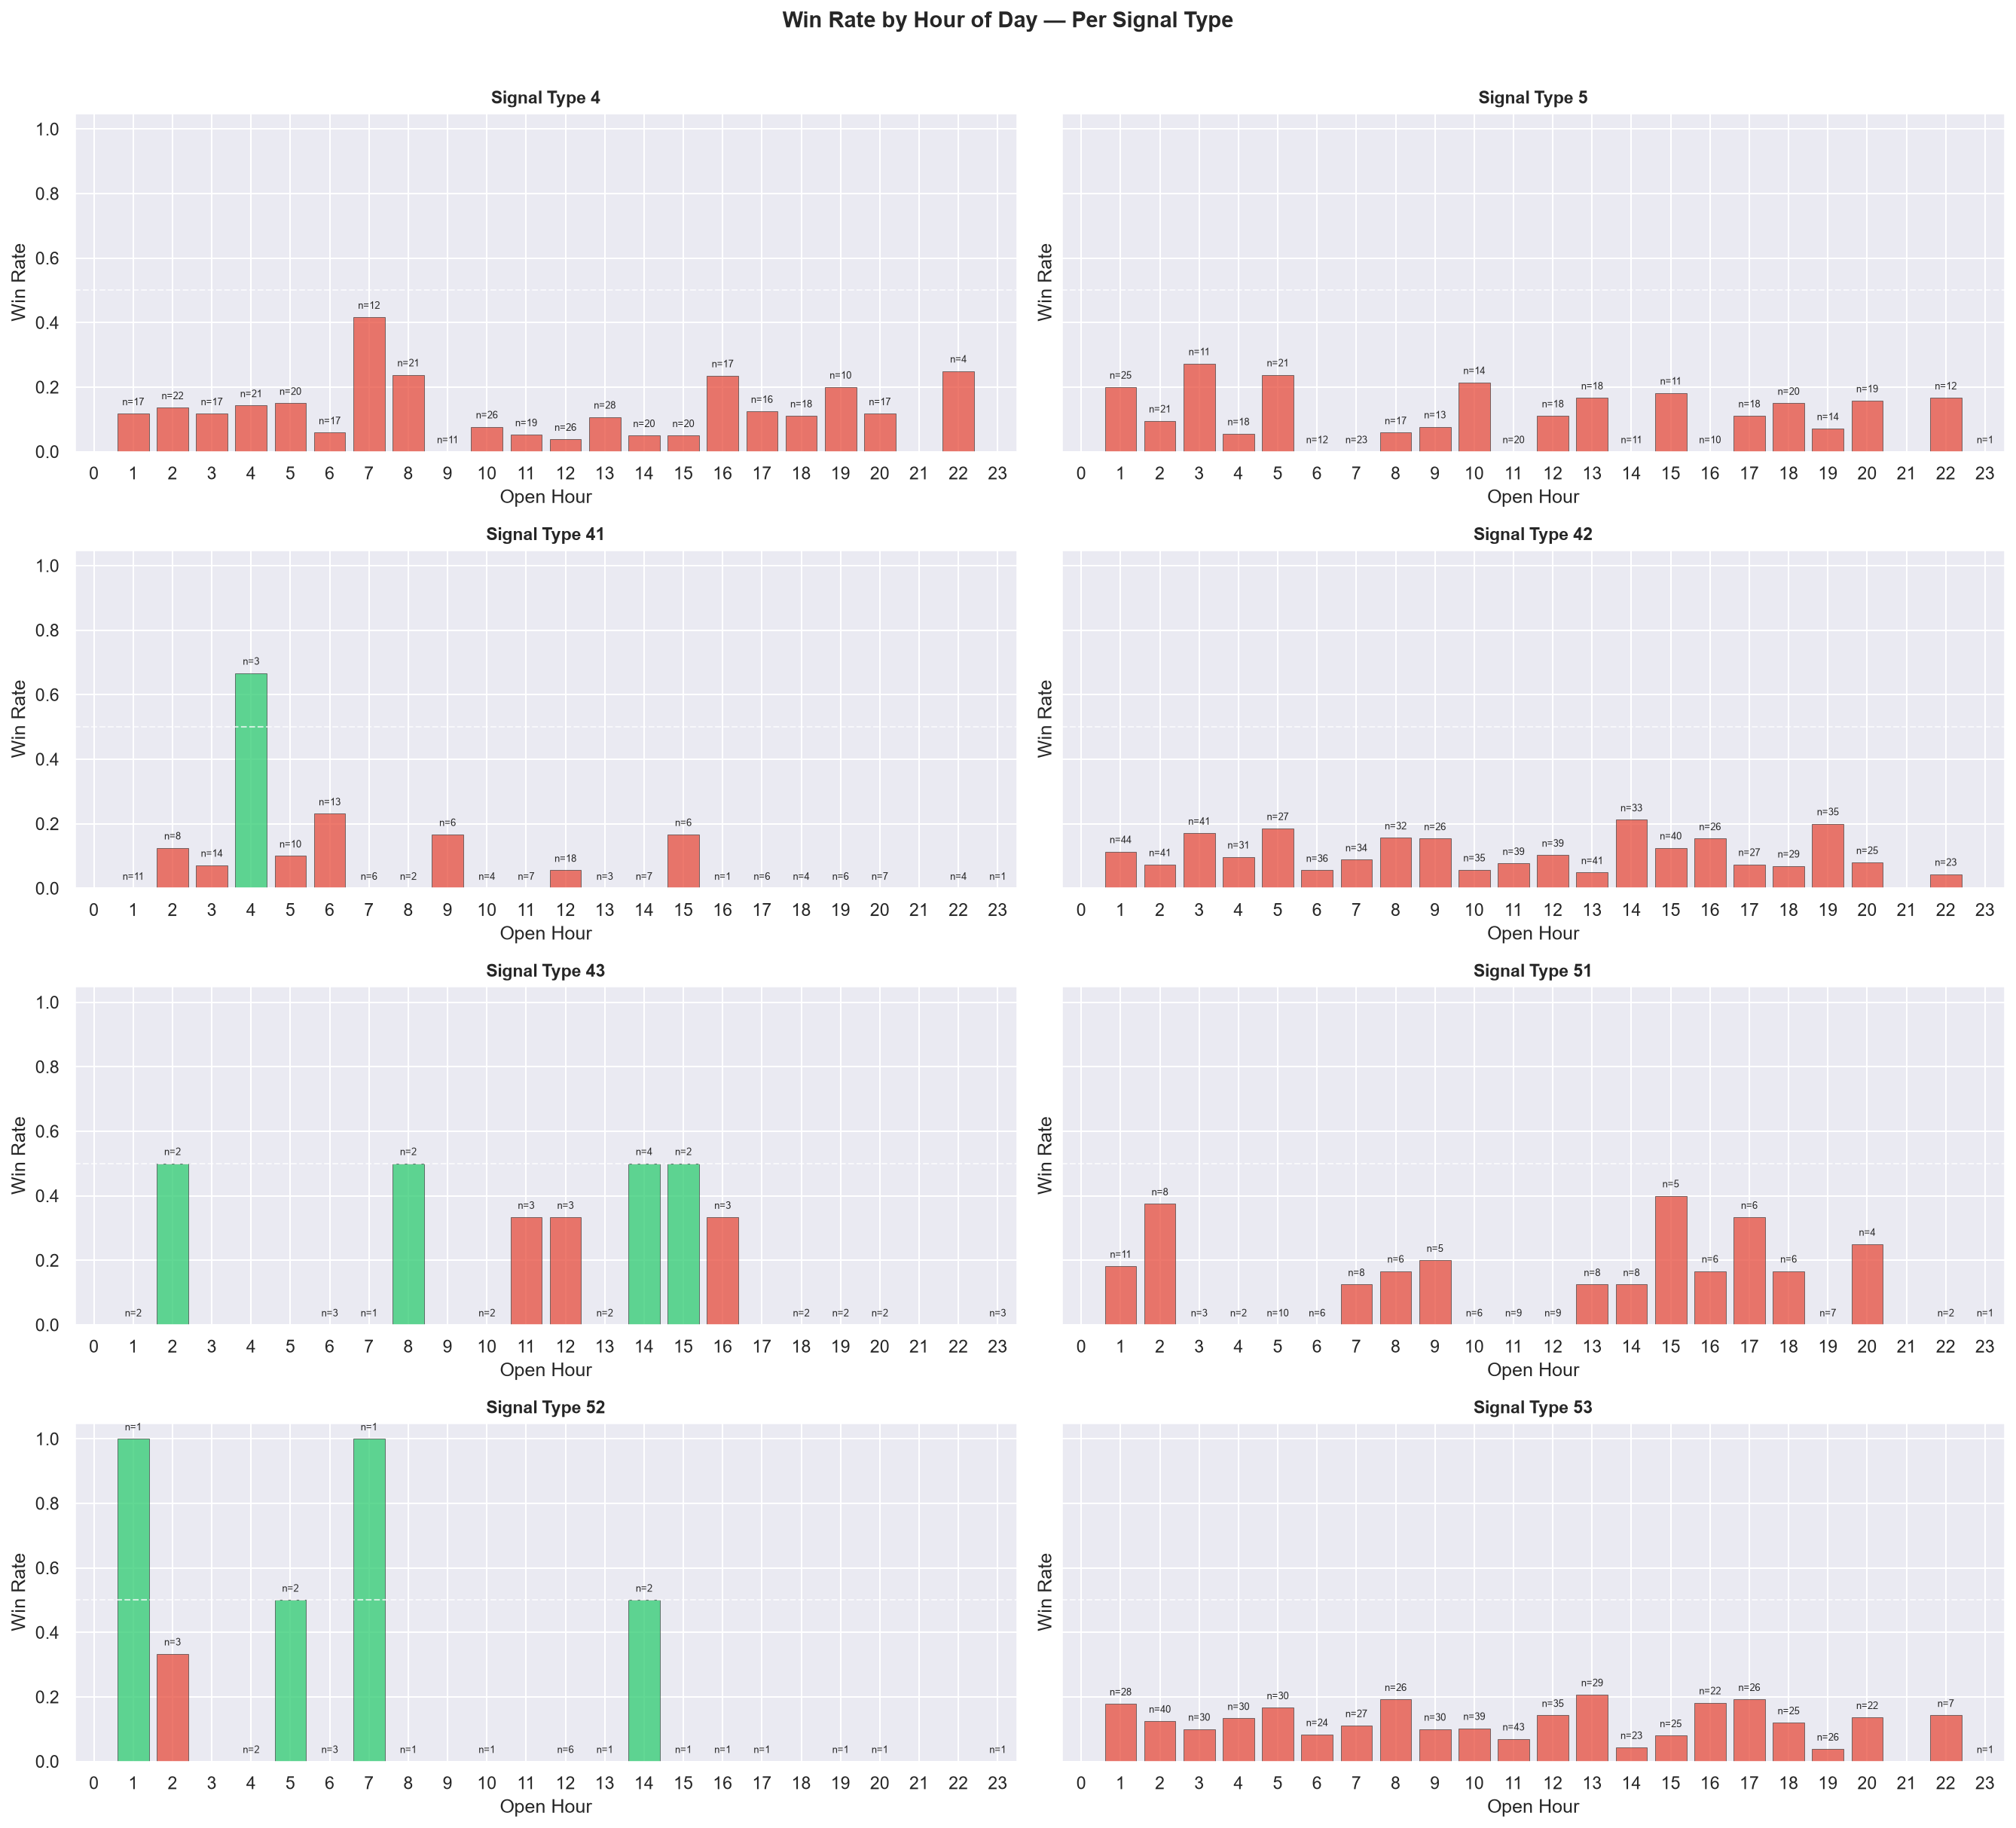

In [61]:
# ── ANALYSIS 3: Win Rate by Hour-of-Day × Signal Type (1-hour intervals) ───

pivot_wr_hour = (
    df.groupby(['signal_type', 'open_hour'], observed=True)['result_R']
    .apply(lambda x: (x > 0).mean())
    .unstack('open_hour')
    .round(3)
)

pivot_n_hour = (
    df.groupby(['signal_type', 'open_hour'], observed=True)['result_R']
    .count()
    .unstack('open_hour')
    .fillna(0)
    .astype(int)
)

print("Win Rate (rows = signal_type, cols = open_hour):")
print(pivot_wr_hour.to_string())
print("\nTrade Count:")
print(pivot_n_hour.to_string())
savetable(pivot_wr_hour, 'winrate_by_hour_x_signal_type.csv')

# ── Heatmap: Win Rate ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(20, 10))

sns.heatmap(
    pivot_wr_hour,
    annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=0, vmax=1,
    linewidths=0.4, linecolor='#444',
    ax=axes[0]
)
axes[0].set_title('Win Rate — Hour of Day × Signal Type', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Open Hour')
axes[0].set_ylabel('Signal Type')

sns.heatmap(
    pivot_n_hour,
    annot=True, fmt='d', cmap='Blues',
    linewidths=0.4, linecolor='#444',
    ax=axes[1]
)
axes[1].set_title('Trade Count — Hour of Day × Signal Type', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Open Hour')
axes[1].set_ylabel('Signal Type')

plt.suptitle('Win Rate & Trade Volume by Hour of Day and Signal Type', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
savefig('winrate_by_hour_x_signal_type.png')

# ── Per-signal line plot ─────────────────────────────────────────────────────
signal_types = sorted(df['signal_type'].unique())
cols = 2
rows = (len(signal_types) + 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(18, 4 * rows), sharey=True)
axes = axes.flatten()

for idx, st in enumerate(signal_types):
    ax = axes[idx]
    sub = df[df['signal_type'] == st]
    hr_wr = (
        sub.groupby('open_hour')['result_R']
        .apply(lambda x: (x > 0).mean())
        .reindex(range(0, 24))
    )
    hr_n = sub.groupby('open_hour')['result_R'].count().reindex(range(0, 24), fill_value=0)

    ax.bar(hr_wr.index, hr_wr.values, color=['#2ecc71' if v >= 0.5 else '#e74c3c'
                                              for v in hr_wr.fillna(0)],
           alpha=0.75, edgecolor='#333', linewidth=0.4, label='Win Rate')
    ax.axhline(0.5, color='white', linewidth=1, linestyle='--', alpha=0.7)
    ax.set_title(f'Signal Type {st}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Open Hour')
    ax.set_ylabel('Win Rate')
    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(range(0, 24))
    ax.set_ylim(0, 1.05)

    # annotate n on each bar
    for h in hr_wr.dropna().index:
        n_val = int(hr_n.get(h, 0))
        wr_val = hr_wr.get(h, 0)
        if n_val > 0:
            ax.text(h, wr_val + 0.02, f'n={n_val}', ha='center', va='bottom', fontsize=6)

# hide unused subplots
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Win Rate by Hour of Day — Per Signal Type', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
savefig('winrate_by_hour_per_signal_type.png')
